# Fase 4 CRISP-DM · Modelado con Árboles de Decisión (`7.0_arbol_decision.ipynb`)

> **Pregunta central del estudio (título y encuadre; no se construye un árbol único para ella)**:
> ### *¿El perfil de un oficio separa a las personas que lo repiten de las que lo ejercen por primera vez?*

---

## 1. Comprensión del Negocio, Alineación con el Acta (`1.0`) y Diseño de Tres Ángulos

### 1.1 Propósito dentro de la serie de Modelado (`7.0`, `7.1`, `7.2`)
Este cuaderno inaugura la serie pedagógica y analítica de la **Fase 4 (Modeling)** de **JobPath** (`7.0_arbol_decision.ipynb`, seguida por `7.1_naive_bayes.ipynb` y `7.2_knn.ipynb`). En lugar de mezclar todas las variables en una caja negra opaca, descomponemos la pregunta central en **tres árboles de decisión CART independientes** que mantienen exactamente la misma variable objetivo `y` (`reincide`), la misma partición agrupada por persona (`resume_id`) y la misma profundidad máxima (`max_depth=4`), cambiando **únicamente** el bloque de variables explicativas `X`:

| Árbol | Pregunta objetivo (texto íntegro) | Bloque de variables `X` (sin mezclar bloques) |
|---|---|---|
| **1 · ISCO** | **¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?** | Información del grupo ocupacional ISCO (10 grandes grupos a 1 dígito como versión principal; subgrupos a 2 dígitos y Top-50 a 4 dígitos solo como variantes registradas en bitácora, con advertencia de circularidad para la de 4 dígitos). |
| **2 · Nivel académico** | **¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?** | Nivel educativo ordinal para categorías reportadas (`1..4`, dejando `'No reportado'` como `NaN` sin rellenar nunca con `0`) + bandera binaria `educacion_no_reportada` (`0/1`). |
| **3 · Competencias ESCO** | **¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?** | `n_skills_essential`, `n_skills_competence`, `n_skills_knowledge` (más auditoría de `n_skills_sin_tipo`, la identidad aditiva $E = C + K$ de 2 grados de libertad y las razones/diferencias derivadas dentro del mismo bloque ESCO). |

### 1.2 Hallazgo de auditoría sobre el Acta del Proyecto (`1.0_comprension_negocio.md`)
Al contrastar el acta fundacional (`1.0_comprension_negocio.md`) con el pipeline vigente de Fase 3 y Fase 4 (`5.0_preparacion_fase3_jobpath.ipynb` y `6.0_modelado_fase4_jobpath.ipynb`), se documenta un desfase formal que debe quedar registrado:
- **En el acta `1.0` original**: el alcance técnico declaraba literalmente *«No supervisado (sin variable objetivo predefinida)»* orientado a segmentación y reglas de asociación.
- **En el pipeline refactorizado vigente**: se incorporó la tarea supervisada binaria sobre `reincide` (`0/1`), definida como `reincide = 1` si `veces_ese_oficio > 1` (donde `veces_ese_oficio` cuenta cuántas veces aparece el par `(resume_id, occupation_code)` en el historial de la persona) y `reincide = 0` si `veces_ese_oficio == 1`.
- **Acción registrada en bitácora**: se mantiene `y = reincide` para garantizar comparabilidad 100% exacta con el techo multivariado de `6.0_modelado_fase4_jobpath.ipynb` y se deja un recordatorio explícito para actualizar `1.0_comprension_negocio.md` reflejando el alcance híbrido (supervisado + descriptivo).

### 1.3 Organización del cuaderno: Versiones A y B separadas y etiquetadas
Para cada uno de los tres árboles se construyen **dos secciones claramente separadas** sobre la totalidad del conjunto clasificado (`1,738,738` filas), utilizando exactamente la misma partición por persona, las mismas variables y los mismos hiperparámetros para que la única diferencia sea la versión del dato limpio (nunca se usa la matriz escalada de `04_transformed` en árboles):
1. **`Versión A · CON outliers`** (`empleos_unificado_limpio.csv`, unidades reales sin winsorizar).
2. **`Versión B · SIN outliers`** (`empleos_limpio_con_competencias_sin_outliers.csv`, recortada por rango intercuartílico IQR).

Al cierre de las dos secciones de cada árbol se presenta una **tabla comparativa lado a lado (`Versión A · CON outliers` vs. `Versión B · SIN outliers`)** por punto de operación (`class_weight=None` y `class_weight='balanced'`) que integra tanto el resultado sobre los datos completos como la prueba de incertidumbre en **5 semillas** (`42, 100, 2026, 7, 999` con `3,000` personas de entrenamiento y `750` de prueba). Toda la bitácora detallada de los 60 intentos de búsqueda y el informe completo A vs. B se escriben en modo **append-only** con identificadores únicos de corrida (`run_id`, marcando las corridas previas como `SUPERSEDED` y la actual como `CURRENT`) en `Bitacora_Arbol_Decision.md` y `Comparacion_A_vs_B_Arbol_Decision.md`.

In [1]:
# First code cell: all standard, third-party, and project module imports
from __future__ import annotations

from pathlib import Path
import sys
import warnings

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 35)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 1000)

# Resolve project root dynamically and attach SOLID module paths
_CANDIDATE_ROOTS = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent,
    Path.cwd() / "MineriaProtect",
]
PROJECT_ROOT = next(
    (p.resolve() for p in _CANDIDATE_ROOTS if (p / "data").is_dir() and (p / "notebooks").is_dir()),
    Path.cwd().resolve(),
)

for _rel_path in ("scripts/ScriptsCsv", "src"):
    _full_path = str((PROJECT_ROOT / _rel_path).resolve())
    if _full_path not in sys.path:
        sys.path.insert(0, _full_path)

from ArbolDecision import (
    ALLOWED_DEPTHS,
    ASPIRATIONAL_TARGET_SCORE,
    BLOCK_EDUCATION,
    BLOCK_ISCO,
    BLOCK_METADATA_ES,
    BLOCK_SKILLS,
    MAIN_QUESTION_ES,
    MAX_TREE_DEPTH,
    RANDOM_STATE,
    TREE_1_QUESTION_ES,
    TREE_2_QUESTION_ES,
    TREE_3_QUESTION_ES,
    VERSION_A,
    VERSION_A_LABEL_ES,
    VERSION_B,
    VERSION_B_LABEL_ES,
    VERSION_LABELS_ES,
    DecisionTreeProjectConfig,
    append_bitacora_arbol_decision_md,
    append_comparacion_a_vs_b_md,
    assert_no_direct_leakage,
    audit_node1_competence_40_threshold_shift,
    audit_partial_circularity,
    audit_profile_20_19_1_occupations,
    audit_skills_additivity_and_version_b_clipping,
    build_course_checklist_table,
    build_data_usage_summary_table,
    build_decision_log_table,
    build_global_comparison_table,
    build_person_split_bundle,
    build_static_literals_audit_table,
    build_tree_ab_reading_es,
    build_tree_version_bundle,
    create_run_metadata,
    demonstrate_narrative_verifier_failure_and_pass,
    evaluate_dummy_baseline,
    evaluate_occupation_grouped_cv_all_trees,
    evaluate_tree3_without_dominant_occupation,
    export_all_tree_artifacts,
    load_clean_version_in_ram,
    load_phase4_ceiling_benchmarks,
    parse_and_verify_narrative_numbers_in_text,
    plot_decision_tree_legible,
    plot_depth_and_confusion_panel,
    plot_feature_importances_three_trees,
    plot_sensitivity_version_a_vs_b,
    plot_trees_vs_baseline_and_ceiling,
    run_version_sensitivity_experiment,
    snapshot_input_file_hashes,
    summarize_unclassified_occupations,
    tune_block_with_grouped_cv,
    verify_input_file_hashes,
    verify_markdown_files_against_memory,
    verify_wording_rules_in_markdown_text,
)

CONFIG = DecisionTreeProjectConfig.from_root(PROJECT_ROOT, random_state=RANDOM_STATE)
INITIAL_INPUT_HASHES = snapshot_input_file_hashes(CONFIG)
CURRENT_RUN_ID, CURRENT_RUN_TIMESTAMP = create_run_metadata()

print(f"Project root resolved to: {CONFIG.project_root}")
print(f"Current Run ID: {CURRENT_RUN_ID} | Timestamp: {CURRENT_RUN_TIMESTAMP}")
print(f"Master random seed: {CONFIG.random_state} | Max tree depth allowed: {CONFIG.max_tree_depth}")
print(f"Main question: {MAIN_QUESTION_ES}")
print(f"Version A label: {VERSION_A_LABEL_ES}")
print(f"Version B label: {VERSION_B_LABEL_ES}")

Project root resolved to: C:\Users\monoc\Desktop\mineria\MineriaProtect
Current Run ID: RUN-20261117-225052 | Timestamp: 2026-11-17 22:50:52
Master random seed: 42 | Max tree depth allowed: 4
Main question: ¿El perfil de un oficio separa a las personas que lo repiten de las que lo ejercen por primera vez?
Version A label: Versión A · CON outliers
Version B label: Versión B · SIN outliers


---

## 2. Auditoría de Datos en RAM, Ocupaciones No Estandarizadas, Split por Persona, Circularidad e Identidad Aditiva (`essential = competence + knowledge`)

Antes de ajustar cualquier árbol (`fit`), verificamos en memoria RAM (`.copy()`, sin modificar ningún archivo de entrada):
1. **Filas sin ocupación estandarizada (`es_ocupacion_clasificada == 0`)**: cuantificamos cuántos registros carecen de código ESCO/ISCO válido (`132,276` filas, `7.07%` de `1,871,014`) y aplicamos la Decisión D07 del proyecto (`5.0_preparacion_fase3_jobpath.ipynb`): excluirlos en RAM antes del split porque carecen de perfil en el catálogo ESCO.
2. **Partición oficial `Train / Test` agrupada por persona (`resume_id`)**: cargamos `split_map_resume_id.csv` (`GroupShuffleSplit(test_size=0.20, random_state=42)`) y comprobamos que no exista **ninguna persona compartida** entre entrenamiento (`281,674` personas; `1,391,018` filas) y prueba (`70,419` personas; `347,720` filas), alineadas 1 a 1 entre **`Versión A · CON outliers`** y **`Versión B · SIN outliers`**.
3. **Auditoría anti-fuga y de circularidad parcial (`N:1`)**:
   - **Cero fuga directa**: ninguna matriz `X` incluye `reincide`, `veces_ese_oficio` ni variables de trayectoria individual.
   - **Circularidad parcial estructural (`N:1`)**: como `reincide` se construye agrupando por `(resume_id, occupation_code)` y tanto `isco_group` como `n_skills_*` son atributos determinísticos del catálogo `occupation_code` (`varianza intra-ocupación = 0.0000`), cualquier combinación discreta de competencias puede actuar como una **huella digital del oficio (occupation fingerprint)**.
4. **Identidad estructural `essential = competence + knowledge` (2 grados de libertad) y efecto del recorte IQR en `Versión B`**:
   - En **`Versión A · CON outliers`**, la suma de 4 términos `n_skills_essential = n_skills_competence + n_skills_knowledge + n_skills_sin_tipo` se cumple en el **`100.00%` de las `1,738,738` filas clasificadas (`0` violaciones)**. Además, en el **`99.10%` de las filas clasificadas (`1,723,128` filas)** `n_skills_sin_tipo == 0`, por lo que se cumple exactamente:
     $$\text{n\_skills\_essential} = \text{n\_skills\_competence} + \text{n\_skills\_knowledge} \quad (E = C + K)$$
   - **Consecuencia estadística**: los tres conteos `(E, C, K)` contienen **únicamente dos piezas independientes de información (2 grados de libertad)**, y las variables derivadas (`diff_competence_knowledge = C - K`, `prop_competence_essential = C / E`, `prop_knowledge_essential = K / E` y `ratio_competence_knowledge = C / (K + 1)`) son combinaciones y reparametrizaciones de esos mismos 2 grados de libertad.
   - **En `Versión B · SIN outliers`**, cada conteo fue recortado por separado mediante IQR (`E <= 47.5`, `C <= 39.5`, `K <= 13.5`), y las variables `diff/prop/ratio` se calcularon **después** de dicho recorte. Cuantificamos a continuación cuántas filas de `Versión B` violan $E = C + K$ tras el recorte y qué ocurre cuando las variables derivadas se calculan **antes** del recorte.

In [2]:
# Load Version A (CON outliers) and Version B (SIN outliers) in RAM and run data, circularity, profile & additivity audits
split_bundle_a = build_person_split_bundle(CONFIG, version=VERSION_A)
split_bundle_b = build_person_split_bundle(CONFIG, version=VERSION_B)

unclassified_a = split_bundle_a.unclassified_summary.copy()
unclassified_a.insert(0, "version_datos", VERSION_A_LABEL_ES)
unclassified_b = split_bundle_b.unclassified_summary.copy()
unclassified_b.insert(0, "version_datos", VERSION_B_LABEL_ES)
unclassified_summary_df = pd.concat([unclassified_a, unclassified_b], ignore_index=True)

split_audit_df = pd.concat([split_bundle_a.split_audit, split_bundle_b.split_audit], ignore_index=True)
circularity_audit_df = audit_partial_circularity(split_bundle_a.df_train)
phase4_benchmarks_df = load_phase4_ceiling_benchmarks(CONFIG)

# Audit the 12 occupations sharing profile (E=20, C=19, K=1), E = C + K additivity / Version B IQR clipping,
# Node 1 threshold shift (39.25 vs 40.50), Tree 3 without 3343.1, and GroupKFold on occupation_code
profile_20_19_1_df, profile_20_19_1_isco_df = audit_profile_20_19_1_occupations(
    df_train=split_bundle_a.df_train,
    df_test=split_bundle_a.df_test,
)
additivity_audit_df, clipping_effect_df = audit_skills_additivity_and_version_b_clipping(
    bundle_a=split_bundle_a,
    bundle_b=split_bundle_b,
)
node1_threshold_audit_df = audit_node1_competence_40_threshold_shift(
    bundle_a=split_bundle_a,
    bundle_b=split_bundle_b,
)
tree3_no_3343_df = evaluate_tree3_without_dominant_occupation(
    bundle_a=split_bundle_a,
    bundle_b=split_bundle_b,
    dominant_code="3343.1",
)
occ_grouped_cv_df = evaluate_occupation_grouped_cv_all_trees(
    bundle_a=split_bundle_a,
)

display(Markdown("### 2.1 Resumen de filas con y sin ocupación estandarizada ESCO/ISCO"))
display(unclassified_summary_df)

display(Markdown("### 2.2 Verificación de la partición oficial agrupada por persona (`resume_id`)"))
display(split_audit_df)

display(Markdown("### 2.3 Auditoría de circularidad parcial (`occupation_code` → `isco_group`, `n_skills_*`)"))
display(circularity_audit_df)

display(Markdown("### 2.4 Auditoría de la identidad `essential = competence + knowledge` (2 grados de libertad) y violaciones por recorte IQR en `Versión B`"))
display(additivity_audit_df)

display(Markdown("### 2.5 Efecto en `Versión B` de calcular las variables derivadas (`diff/prop/ratio`) DESPUÉS vs. ANTES del recorte IQR"))
display(clipping_effect_df)

display(Markdown("### 2.6 Por qué `Versión B2` (derivadas antes del recorte) y `Versión A` dan métricas idénticas en el punto balanceado con umbral de nivel 2 `39.25` vs. `40.50` (`0` filas con `n_skills_competence == 40` en ese nodo)"))
display(node1_threshold_audit_df)

### 2.1 Resumen de filas con y sin ocupación estandarizada ESCO/ISCO

version_datos,segmento,filas,porcentaje_filas,personas_unicas,decision_proyecto
Versión A · CON outliers,Total unificado limpio (03_processed),1871014,100.00,355308.0,Universo completo en disco (inmutable)
Versión A · CON outliers,Con ocupación ESCO estandarizada (n_skills_essential no nulo),1738738,92.93,352093.0,Incluido en modelado (Decisión D07)
Versión A · CON outliers,Sin ocupación ESCO estandarizada (total excluido en RAM),132276,7.07,3215.0,Excluido en RAM antes del split (sin perfil ESCO)
Versión A · CON outliers,└─ Desglose: emparejado == 'unknown',128981,6.89,NaN,Texto libre sin correspondencia ESCO
Versión A · CON outliers,└─ Desglose: emparejado == 'rescatado' sin padre ESCO,3295,0.18,NaN,Rescate léxico sin perfil de competencias ESCO
Versión B · SIN outliers,Total unificado limpio (03_processed),1871014,100.00,355308.0,Universo completo en disco (inmutable)
Versión B · SIN outliers,Con ocupación ESCO estandarizada (n_skills_essential no nulo),1738738,92.93,352093.0,Incluido en modelado (Decisión D07)
Versión B · SIN outliers,Sin ocupación ESCO estandarizada (total excluido en RAM),132276,7.07,3215.0,Excluido en RAM antes del split (sin perfil ESCO)
Versión B · SIN outliers,└─ Desglose: emparejado == 'unknown',128981,6.89,NaN,Texto libre sin correspondencia ESCO
Versión B · SIN outliers,└─ Desglose: emparejado == 'rescatado' sin padre ESCO,3295,0.18,NaN,Rescate léxico sin perfil de competencias ESCO


### 2.2 Verificación de la partición oficial agrupada por persona (`resume_id`)

version,particion,filas,personas_unicas,positivos_reincide_1,negativos_reincide_0,tasa_clase_1_pct,personas_compartidas_train_test,coincide_split_map,coincide_y_04_transformed
Versión A · CON outliers,Train (80%),1391018,281674,417471,973547,30.01,0,Sí,Sí
Versión A · CON outliers,Test (20%),347720,70419,104225,243495,29.97,0,Sí,Sí
Versión B · SIN outliers,Train (80%),1391018,281674,417471,973547,30.01,0,Sí,Sí
Versión B · SIN outliers,Test (20%),347720,70419,104225,243495,29.97,0,Sí,Sí


### 2.3 Auditoría de circularidad parcial (`occupation_code` → `isco_group`, `n_skills_*`)

componente_evaluado,llave_estructural,cardinalidad_en_train,varianza_intra_occupation_code,diagnostico_circularidad
Target reincide = (veces_ese_oficio > 1),resume_id + occupation_code,2968 oficios × 281674 personas,Varía por persona (no determinista por oficio),Definición legítima del evento de repetición laboral
1 · ISCO (¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?),occupation_code -> isco_group[0],10 grandes grupos (promedio 296.8 oficios/grupo),0.0000 (1 grupo ISCO por oficio; máx=1),Circularidad parcial BAJA (agregación macro de ~296.8 oficios por gran grupo)
1 · ISCO Variantes (2 dígitos / Top-50 4 dígitos),occupation_code -> isco_group[:2] / isco_group,42 subgrupos (2d) / 426 grupos unitarios (4d),0.0000 (asignación N:1 desde ESCO),Circularidad parcial ALTA en 4 dígitos (casi identifica el oficio específico)
2 · Education level (¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?),resume_id (atributo de la persona en el CV),4 niveles reportados (1..4) + bandera no reportado (MNAR),Alta (personas con distinta educación ejercen el mismo oficio),"SIN circularidad con occupation_code (atributo del trabajador, no del catálogo ESCO)"
3 · Skills (¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?),occupation_code -> catálogo ESCO v1.2.1,"612 combinaciones únicas de (essential, competence, knowledge)",std máx = 0.0000 / 0.0000 / 0.0000,Circularidad parcial MODERADA: los conteos cuelgan determinísticamente de occupation_code (N:1); los cortes sobre conteos actúan parcialmente como huella del oficio


... (2 outputs left out)

### 2.5 Efecto en `Versión B` de calcular las variables derivadas (`diff/prop/ratio`) DESPUÉS vs. ANTES del recorte IQR

esquema_variables_arbol_3,punto_operacion,profundidad_efectiva,n_hojas,train_accuracy,test_accuracy,test_precision_1,test_recall_1,test_f1_1,test_roc_auc,umbral_raiz,umbral_nivel2_izq,umbral_nivel2_der
Versión A · CON outliers (sin recorte IQR; E = C + K intacto),Punto Exactitud (class_weight=None),4,13,0.7048,0.7046,0.5363,0.1060,0.1769,0.6145,diff_competence_knowledge <= 16.50,n_skills_competence <= 40.50,diff_competence_knowledge <= 18.50
Versión B · SIN outliers · Derivadas DESPUÉS del recorte IQR (actual),Punto Exactitud (class_weight=None),4,16,0.7043,0.7047,0.5255,0.1535,0.2376,0.6213,diff_competence_knowledge <= 16.50,n_skills_essential <= 10.50,prop_competence_essential <= 0.95
Versión B · SIN outliers · Derivadas ANTES del recorte IQR (conteos truncados + razones/dif reales),Punto Exactitud (class_weight=None),4,13,0.7042,0.7040,0.5323,0.1014,0.1703,0.6157,diff_competence_knowledge <= 16.50,n_skills_competence <= 39.25,diff_competence_knowledge <= 18.50
Versión A · CON outliers (sin recorte IQR; E = C + K intacto),Punto Recall (class_weight='balanced'),4,13,0.6113,0.6107,0.3920,0.5421,0.4550,0.6157,diff_competence_knowledge <= 16.50,n_skills_competence <= 40.50,diff_competence_knowledge <= 18.50
Versión B · SIN outliers · Derivadas DESPUÉS del recorte IQR (actual),Punto Recall (class_weight='balanced'),4,16,0.5780,0.5777,0.3762,0.6217,0.4688,0.6203,diff_competence_knowledge <= 16.50,n_skills_essential <= 10.50,prop_competence_essential <= 0.95
Versión B · SIN outliers · Derivadas ANTES del recorte IQR (conteos truncados + razones/dif reales),Punto Recall (class_weight='balanced'),4,13,0.6113,0.6107,0.3920,0.5421,0.4550,0.6157,diff_competence_knowledge <= 16.50,n_skills_competence <= 39.25,diff_competence_knowledge <= 18.50


### 2.6 Por qué `Versión B2` (derivadas antes del recorte) y `Versión A` dan métricas idénticas en el punto balanceado con umbral de nivel 2 `39.25` vs. `40.50` (`0` filas con `n_skills_competence == 40` en ese nodo)

particion,filas_en_nodo1_izq_diff_le_16_5,filas_en_nodo1_con_competence_igual_39,filas_en_nodo1_con_competence_igual_40,filas_en_nodo1_con_competence_igual_41,filas_en_nodo1_con_competence_igual_42,filas_en_nodo1_con_competence_le_39,filas_en_nodo1_con_competence_gt_39,filas_rama_der_en_A_competence_gt_40_50,filas_rama_der_en_B2_competence_gt_39_25,valores_consecutivos_nodo1_en_A,punto_medio_sklearn_en_A,valores_consecutivos_nodo1_en_B2,punto_medio_sklearn_en_B2,filas_globales_con_competence_igual_40,filas_competence_40_en_rama_derecha_raiz_diff_gt_16_5
Train (80%),780001,63,0,0,898,777461,2540,2540,2540,"39.0, 42.0, 43.0",40.5,"39.0, 39.5",39.25,583,583
Test (20%),195015,6,0,0,212,194375,640,640,640,"39.0, 42.0, 43.0",40.5,"39.0, 39.5",39.25,134,134


---

## 3. Las Tres Referencias Obligatorias, Proporción del Techo en `ROC-AUC` y Búsqueda Honesta en CV Agrupado

### 3.1 Tres referencias obligatorias y métrica de proporción del techo basada en `ROC-AUC`
En un problema con prevalencia de clase positiva $p = P(\text{reincide}=1) \approx 0.3000$ (`30.01%` en Train y `29.97%` en Test), ninguna métrica aislada dice toda la verdad. Por eso cada árbol y versión se contrasta siempre frente a **tres referencias calculadas**:
1. **Ref 1 · Baseline de clase mayoritaria (`DummyClassifier(strategy="most_frequent")`)**: predice siempre `0` (`No reincide`). Alcanza `test_accuracy = 0.7003`, pero con `recall = 0.0000`, `F1 = 0.0000` y `ROC-AUC = 0.5000`. Cuando un árbol en `class_weight=None` tiene `recall = 0.0000`, decimos estrictamente que **«empata el baseline porque no predice ningún positivo»** (nunca que lo supera).
2. **Ref 2 · Clasificador trivial todo-positivo (predice siempre `1`)**: si un modelo predice `1` para todas las filas, obtiene `recall = 1.0000` y un F1 de clase 1 igual a:
   $$F1_{\text{todo-1}} = \frac{2p}{1+p} = \frac{2(0.2997)}{1.2997} = 0.4612$$
   pero a costa de hundir la exactitud global a `0.2997` y con `ROC-AUC = 0.5000`. Por esta razón, **no debe medirse el porcentaje del techo dividiendo F1 entre el F1 del techo (`0.5321`)** —pues un clasificador trivial sin poder discriminante ya marcaría `86.7%`—, sino que el F1 de cada árbol debe leerse siempre al lado de la referencia trivial `0.4612`.
3. **Ref 3 · Techo multivariado real del proyecto (`6.0_modelado_fase4_jobpath.ipynb`) y Proporción del Techo en `ROC-AUC`**: la Regresión Logística Regularizada con `2,981` columnas OHE que combina simultáneamente oficio fino, educación, competencias y trayectoria individual alcanza en Test `F1 = 0.5321` (`Versión A · CON outliers`) / `0.5325` (`Versión B · SIN outliers`) y `ROC-AUC = 0.7133`. La **proporción del techo alcanzada por cada árbol** se mide estrictamente por su ganancia discriminante en `ROC-AUC` sobre el azar (`0.5000`):
   $$\text{Proporción del techo (ROC-AUC)} = \frac{\text{ROC-AUC}_{\text{árbol}} - 0.5000}{\text{ROC-AUC}_{\text{techo 6.0}} - 0.5000} = \frac{\text{ROC-AUC}_{\text{árbol}} - 0.5000}{0.7133 - 0.5000}$$

### 3.2 Reglas de decisión para declarar separación y mejora sobre el baseline
- **¿El árbol separa las clases?**: Sí, únicamente si el límite inferior del **IC95% por persona** del `ROC-AUC` en Test supera `0.50` **y** la **mejor hoja elegida estrictamente con estadísticas de `Train`** (soporte en `Train` $\ge 0.5\%$, es decir $\ge 6,955$ filas en Train, y mayor `lift_train`) alcanza al evaluarse fuera de muestra en `Test` un **Lift** $\ge 1.50$ (conservando el `max-test-lift` únicamente como referencia optimista etiquetada).
- **¿Supera al baseline en exactitud?**: Sí, únicamente si en el punto orientado a exactitud (`class_weight=None` o en el umbral OOF $\tau^*$) la exactitud en Test es $> 0.7003$ con `recall > 0.0000`; si `recall == 0.0000` y `accuracy == 0.7003`, **empata el baseline porque no predice ningún positivo**.
- **Línea de referencia `0.85`**: se conserva únicamente como cota aspiracional pedagógica, reportando explícitamente la brecha (`0.85 - métrica`) sin forzar jamás sobreajuste ni fuga.

In [3]:
# Precompute 5 person-grouped folds once per version and run the 10-attempt tuning per block and version
gkf_master = GroupKFold(n_splits=CONFIG.cv_folds)
shared_folds_a = list(
    gkf_master.split(split_bundle_a.df_train, split_bundle_a.y_train, groups=split_bundle_a.groups_train)
)
shared_folds_b = list(
    gkf_master.split(split_bundle_b.df_train, split_bundle_b.y_train, groups=split_bundle_b.groups_train)
)

tuning_results_a = {}
tuning_results_b = {}
leakage_audit_rows = []
bundles_a = {}
bundles_b = {}

for block_id in (BLOCK_ISCO, BLOCK_EDUCATION, BLOCK_SKILLS):
    # 1. Tune on Version A (CON outliers) using 1-SE rule on GroupKFold ROC-AUC
    tune_a = tune_block_with_grouped_cv(
        block_id=block_id,
        version=VERSION_A,
        df_train=split_bundle_a.df_train,
        df_test=split_bundle_a.df_test,
        y_train=split_bundle_a.y_train,
        y_test=split_bundle_a.y_test,
        groups_train=split_bundle_a.groups_train,
        config=CONFIG,
        precomputed_folds=shared_folds_a,
    )
    tuning_results_a[block_id] = tune_a

    # 2. Tune on Version B (SIN outliers) logging all 10 attempts and locking the same selected spec as A
    tune_b = tune_block_with_grouped_cv(
        block_id=block_id,
        version=VERSION_B,
        df_train=split_bundle_b.df_train,
        df_test=split_bundle_b.df_test,
        y_train=split_bundle_b.y_train,
        y_test=split_bundle_b.y_test,
        groups_train=split_bundle_b.groups_train,
        config=CONFIG,
        precomputed_folds=shared_folds_b,
        locked_attempt_id=tune_a.selected_attempt_id,
    )
    tuning_results_b[block_id] = tune_b

    # 3. Verify zero direct leakage and audit MNAR education counts across Train, Test, and Total
    leakage_audit_rows.append(
        assert_no_direct_leakage(
            tune_a.X_train,
            tune_a.X_test,
            split_bundle_a.y_train,
            block_id,
            version_label=VERSION_A_LABEL_ES,
        )
    )
    leakage_audit_rows.append(
        assert_no_direct_leakage(
            tune_b.X_train,
            tune_b.X_test,
            split_bundle_b.y_train,
            block_id,
            version_label=VERSION_B_LABEL_ES,
        )
    )

    # 4. Build complete inspection bundles (2 operating points + OOF tau* + person-bootstrap CIs + Wilson CIs + profile rules)
    bundles_a[block_id] = build_tree_version_bundle(
        tuning_result=tune_a,
        split_bundle=split_bundle_a,
        phase4_bench_df=phase4_benchmarks_df,
        config=CONFIG,
        profile_20_19_1_df=profile_20_19_1_df if block_id == BLOCK_SKILLS else None,
    )
    bundles_b[block_id] = build_tree_version_bundle(
        tuning_result=tune_b,
        split_bundle=split_bundle_b,
        phase4_bench_df=phase4_benchmarks_df,
        config=CONFIG,
        profile_20_19_1_df=profile_20_19_1_df if block_id == BLOCK_SKILLS else None,
    )

leakage_audit_df = pd.concat(leakage_audit_rows, ignore_index=True)
_, dummy_metrics_df, _ = evaluate_dummy_baseline(
    X_train=bundles_a[BLOCK_ISCO].tuning_result.X_train,
    y_train=split_bundle_a.y_train,
    X_test=bundles_a[BLOCK_ISCO].tuning_result.X_test,
    y_test=split_bundle_a.y_test,
    random_state=CONFIG.random_state,
)

# Run the 5-seed (42, 100, 2026, 7, 999) person-sampled sensitivity experiment + full-data A vs B comparison
sensitivity_result = run_version_sensitivity_experiment(
    bundle_a=split_bundle_a,
    bundle_b=split_bundle_b,
    tuning_results_a=tuning_results_a,
    tuning_results_b=tuning_results_b,
    config=CONFIG,
)

display(Markdown("### 3.3 Verificación anti-fuga y reconciliación de nulos MNAR de educación (`160,664` Train / `40,270` Test / `200,934` Total clasificado)"))
display(leakage_audit_df)

display(Markdown("### 3.4 Tabla de las Tres Referencias Obligatorias (`Versión A · CON outliers` y `Versión B · SIN outliers`)"))
display(
    pd.concat(
        [bundles_a[BLOCK_ISCO].references_df, bundles_b[BLOCK_ISCO].references_df],
        ignore_index=True,
    )
)

### 3.3 Verificación anti-fuga y reconciliación de nulos MNAR de educación (`160,664` Train / `40,270` Test / `200,934` Total clasificado)

version_datos,bloque,pregunta_objetivo,n_variables_X,columnas_fuga_detectadas,nulos_inesperados_train,nulos_inesperados_test,nulos_no_esperados,nulos_mnar_separados_train,nulos_mnar_separados_test,nulos_mnar_separados_total,esquema_train_test_identico,variable_mayor_corr_abs_y,max_corr_abs_con_reincide,veredicto_anti_fuga
Versión A · CON outliers,tree_1_isco,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,10,0,0,0,0,0,0,0,Sí,isco_major_4,0.0487,APROBADO (sin fuga directa)
Versión B · SIN outliers,tree_1_isco,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,10,0,0,0,0,0,0,0,Sí,isco_major_4,0.0487,APROBADO (sin fuga directa)
Versión A · CON outliers,tree_2_education,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,2,0,0,0,0,160664,40270,200934,Sí,nivel_academico_ord,0.0414,APROBADO (sin fuga directa)
Versión B · SIN outliers,tree_2_education,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,2,0,0,0,0,160664,40270,200934,Sí,nivel_academico_ord,0.0414,APROBADO (sin fuga directa)
Versión A · CON outliers,tree_3_skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,7,0,0,0,0,0,0,0,Sí,diff_competence_knowledge,0.0828,APROBADO (sin fuga directa)
Versión B · SIN outliers,tree_3_skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,7,0,0,0,0,0,0,0,Sí,diff_competence_knowledge,0.1056,APROBADO (sin fuga directa)


### 3.4 Tabla de las Tres Referencias Obligatorias (`Versión A · CON outliers` y `Versión B · SIN outliers`)

version_datos,referencia_id,regla_decision,train_accuracy,test_accuracy,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,test_roc_auc,brecha_vs_meta_085_f1,significado_metodologico
Versión A · CON outliers,Ref 1 · Baseline clase mayoritaria (Dummy most_frequent),Predice siempre 0 (no reincide),0.6999,0.7003,0.0000,0.0000,0.0000,0.5000,0.8500,Piso de exactitud global (70.03%): cualquier modelo en el punto orientado a accuracy debe no caer por debajo.
Versión A · CON outliers,Ref 2 · Clasificador trivial todo-positivo (predice todo 1),Predice siempre 1 (reincide),0.3001,0.2997,0.2997,1.0000,0.4612,0.5000,0.3888,F1 trivial 2p/(1+p) = 0.4612 con exactitud de apenas 29.97% y sin poder discriminante (AUC=0.50).
Versión A · CON outliers,"Ref 3 · Techo real del proyecto (6.0 Logística OHE 2,981 cols)","Combina simultáneamente oficio OHE, educación, competencias y trayectoria",NaN,0.6760,0.4691,0.6147,0.5321,0.7133,0.3179,"Techo multivariado real de Fase 4 (F1=0.5321, ROC-AUC=0.7133): muestra cuánto alcanza cada árbol de un solo bloque frente al modelo completo."
Versión B · SIN outliers,Ref 1 · Baseline clase mayoritaria (Dummy most_frequent),Predice siempre 0 (no reincide),0.6999,0.7003,0.0000,0.0000,0.0000,0.5000,0.8500,Piso de exactitud global (70.03%): cualquier modelo en el punto orientado a accuracy debe no caer por debajo.
Versión B · SIN outliers,Ref 2 · Clasificador trivial todo-positivo (predice todo 1),Predice siempre 1 (reincide),0.3001,0.2997,0.2997,1.0000,0.4612,0.5000,0.3888,F1 trivial 2p/(1+p) = 0.4612 con exactitud de apenas 29.97% y sin poder discriminante (AUC=0.50).
Versión B · SIN outliers,"Ref 3 · Techo real del proyecto (6.0 Logística OHE 2,981 cols)","Combina simultáneamente oficio OHE, educación, competencias y trayectoria",NaN,0.6757,0.4688,0.6162,0.5325,0.7132,0.3175,"Techo multivariado real de Fase 4 (F1=0.5325, ROC-AUC=0.7132): muestra cuánto alcanza cada árbol de un solo bloque frente al modelo completo."


---

## 4. Árbol 1 · ISCO: ¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?

### 4.1 Sección `Versión A · CON outliers` — ¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?
En esta sección entrenamos, visualizamos y auditamos el árbol de profundidad máxima `max_depth=4` exclusivamente sobre **`Versión A · CON outliers`** (unidades originales sin winsorizar), reportando sus dos puntos de operación (`class_weight=None` y `class_weight='balanced'`), el umbral OOF $\tau^*$, la proporción del techo en `ROC-AUC` (`(AUC - 0.5) / (0.7133 - 0.5)`) junto a la referencia trivial todo-positivo (`F1 = 0.4612`), la evolución en profundidades `2, 3 y 4`, las primeras preguntas vía `decision_path`, la importancia relativa de variables (*lo que este árbol miró*, nunca causalidad), las hojas con **IC95% Wilson** y las reglas de negocio con soporte $\ge 0.5\%$.

#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión A · CON outliers`
**Pregunta**: *¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?*

version_datos,arbol,pregunta_objetivo,punto_operacion,regla_decision,profundidad_efectiva,n_hojas,train_accuracy,test_accuracy,test_accuracy_ic95_persona,gap_acc_train_test,train_precision_1,test_precision_1,train_recall_1,test_recall_1,test_recall_1_ic95_persona,train_f1_1,test_f1_1,test_f1_1_ic95_persona,f1_ref_trivial_todo_1,delta_f1_vs_trivial_todo_1,train_roc_auc,test_roc_auc,test_roc_auc_ic95_persona,roc_auc_ic95_inf,roc_auc_ic95_sup,roc_auc_techo_6_0,pct_del_techo_auc_6_0,hoja_elegida_en_train_id,lift_train_hoja_elegida,max_lift_hoja_soporte_05pct,max_lift_test_referencia_optimista,hoja_con_lift_ge_150_y_soporte_05pct,criterio_separa_clases,supera_baseline_exactitud_7003,brecha_vs_meta_085_f1,tn_test,fp_test,fn_test,tp_test
Versión A · CON outliers,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Punto 1 · Orientado a Exactitud (class_weight=None),Umbral estándar 0.50 sobre tasa empírica de hoja,4,5,0.6999,0.7003,"[0.6981, 0.7025]",-0.0004,0.0000,0.0000,0.0000,0.0000,"[0.0000, 0.0000]",0.000,0.000,"[0.0000, 0.0000]",0.4612,-0.4612,0.5455,0.5459,"[0.5436, 0.5482]",0.5436,0.5482,0.7133,21.53,4,1.086,1.086,1.086,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),Empata el baseline porque no predice ningún positivo,0.850,243495,0,104225,0
Versión A · CON outliers,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),Pesos balanceados inversamente proporcionales a 70/30,4,5,0.4451,0.4443,"[0.4420, 0.4461]",0.0008,0.3258,0.3254,0.7939,0.7961,"[0.7922, 0.8002]",0.462,0.462,"[0.4588, 0.4648]",0.4612,0.0008,0.5455,0.5459,"[0.5436, 0.5482]",0.5436,0.5482,0.7133,21.53,4,1.086,1.086,1.086,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),No (prioriza Recall sobre exactitud global),0.388,71512,171983,21250,82975
Versión A · CON outliers,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Punto 3 · Umbral OOF óptimo en Train (tau*=0.330),Predice 1 si P(reincide=1|hoja) >= 0.330 (sujeto a Acc >= Baseline en OOF Train),4,5,0.6999,0.7003,"[0.6981, 0.7025]",-0.0004,0.0000,0.0000,0.0000,0.0000,"[0.0000, 0.0000]",0.000,0.000,"[0.0000, 0.0000]",0.4612,-0.4612,0.5455,0.5459,"[0.5436, 0.5482]",0.5436,0.5482,0.7133,21.53,4,1.086,1.086,1.086,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),Empata el baseline porque no predice ningún positivo,0.850,243495,0,104225,0


#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión A · CON outliers`

version_datos,arbol,punto_operacion,max_depth,profundidad_alcanzada,n_leaves,train_acc,test_acc,gap_train_test,train_f1_clase_1,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,test_roc_auc
Versión A · CON outliers,Árbol 1 · ISCO,class_weight=None (Exactitud),2,2,3,0.6999,0.7003,-0.0004,0.0000,0.0000,0.0000,0.0000,0.5260
Versión A · CON outliers,Árbol 1 · ISCO,class_weight=None (Exactitud),3,3,4,0.6999,0.7003,-0.0004,0.0000,0.0000,0.0000,0.0000,0.5380
Versión A · CON outliers,Árbol 1 · ISCO,class_weight=None (Exactitud),4,4,5,0.6999,0.7003,-0.0004,0.0000,0.0000,0.0000,0.0000,0.5459
Versión A · CON outliers,Árbol 1 · ISCO,class_weight='balanced' (Recall),2,2,3,0.3769,0.3763,0.0006,0.4636,0.3123,0.8991,0.4636,0.5260
Versión A · CON outliers,Árbol 1 · ISCO,class_weight='balanced' (Recall),3,3,4,0.4157,0.4150,0.0007,0.4637,0.3197,0.8438,0.4637,0.5380
Versión A · CON outliers,Árbol 1 · ISCO,class_weight='balanced' (Recall),4,4,5,0.4451,0.4443,0.0008,0.4620,0.3254,0.7961,0.4620,0.5459


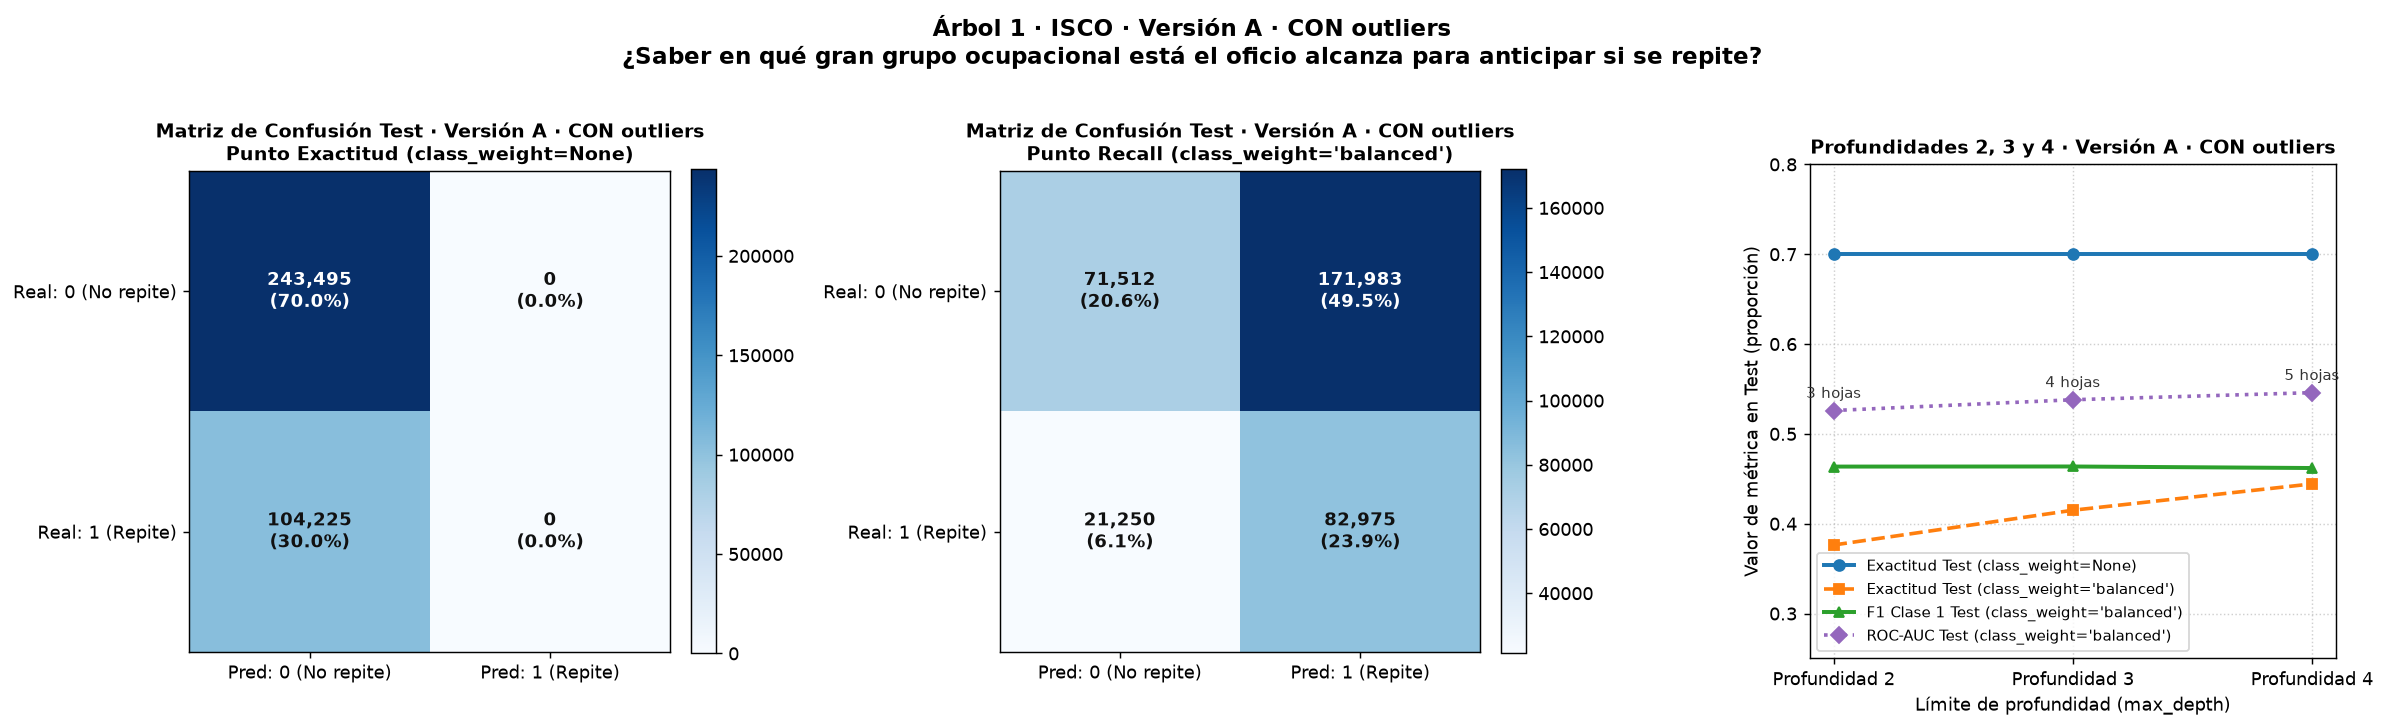

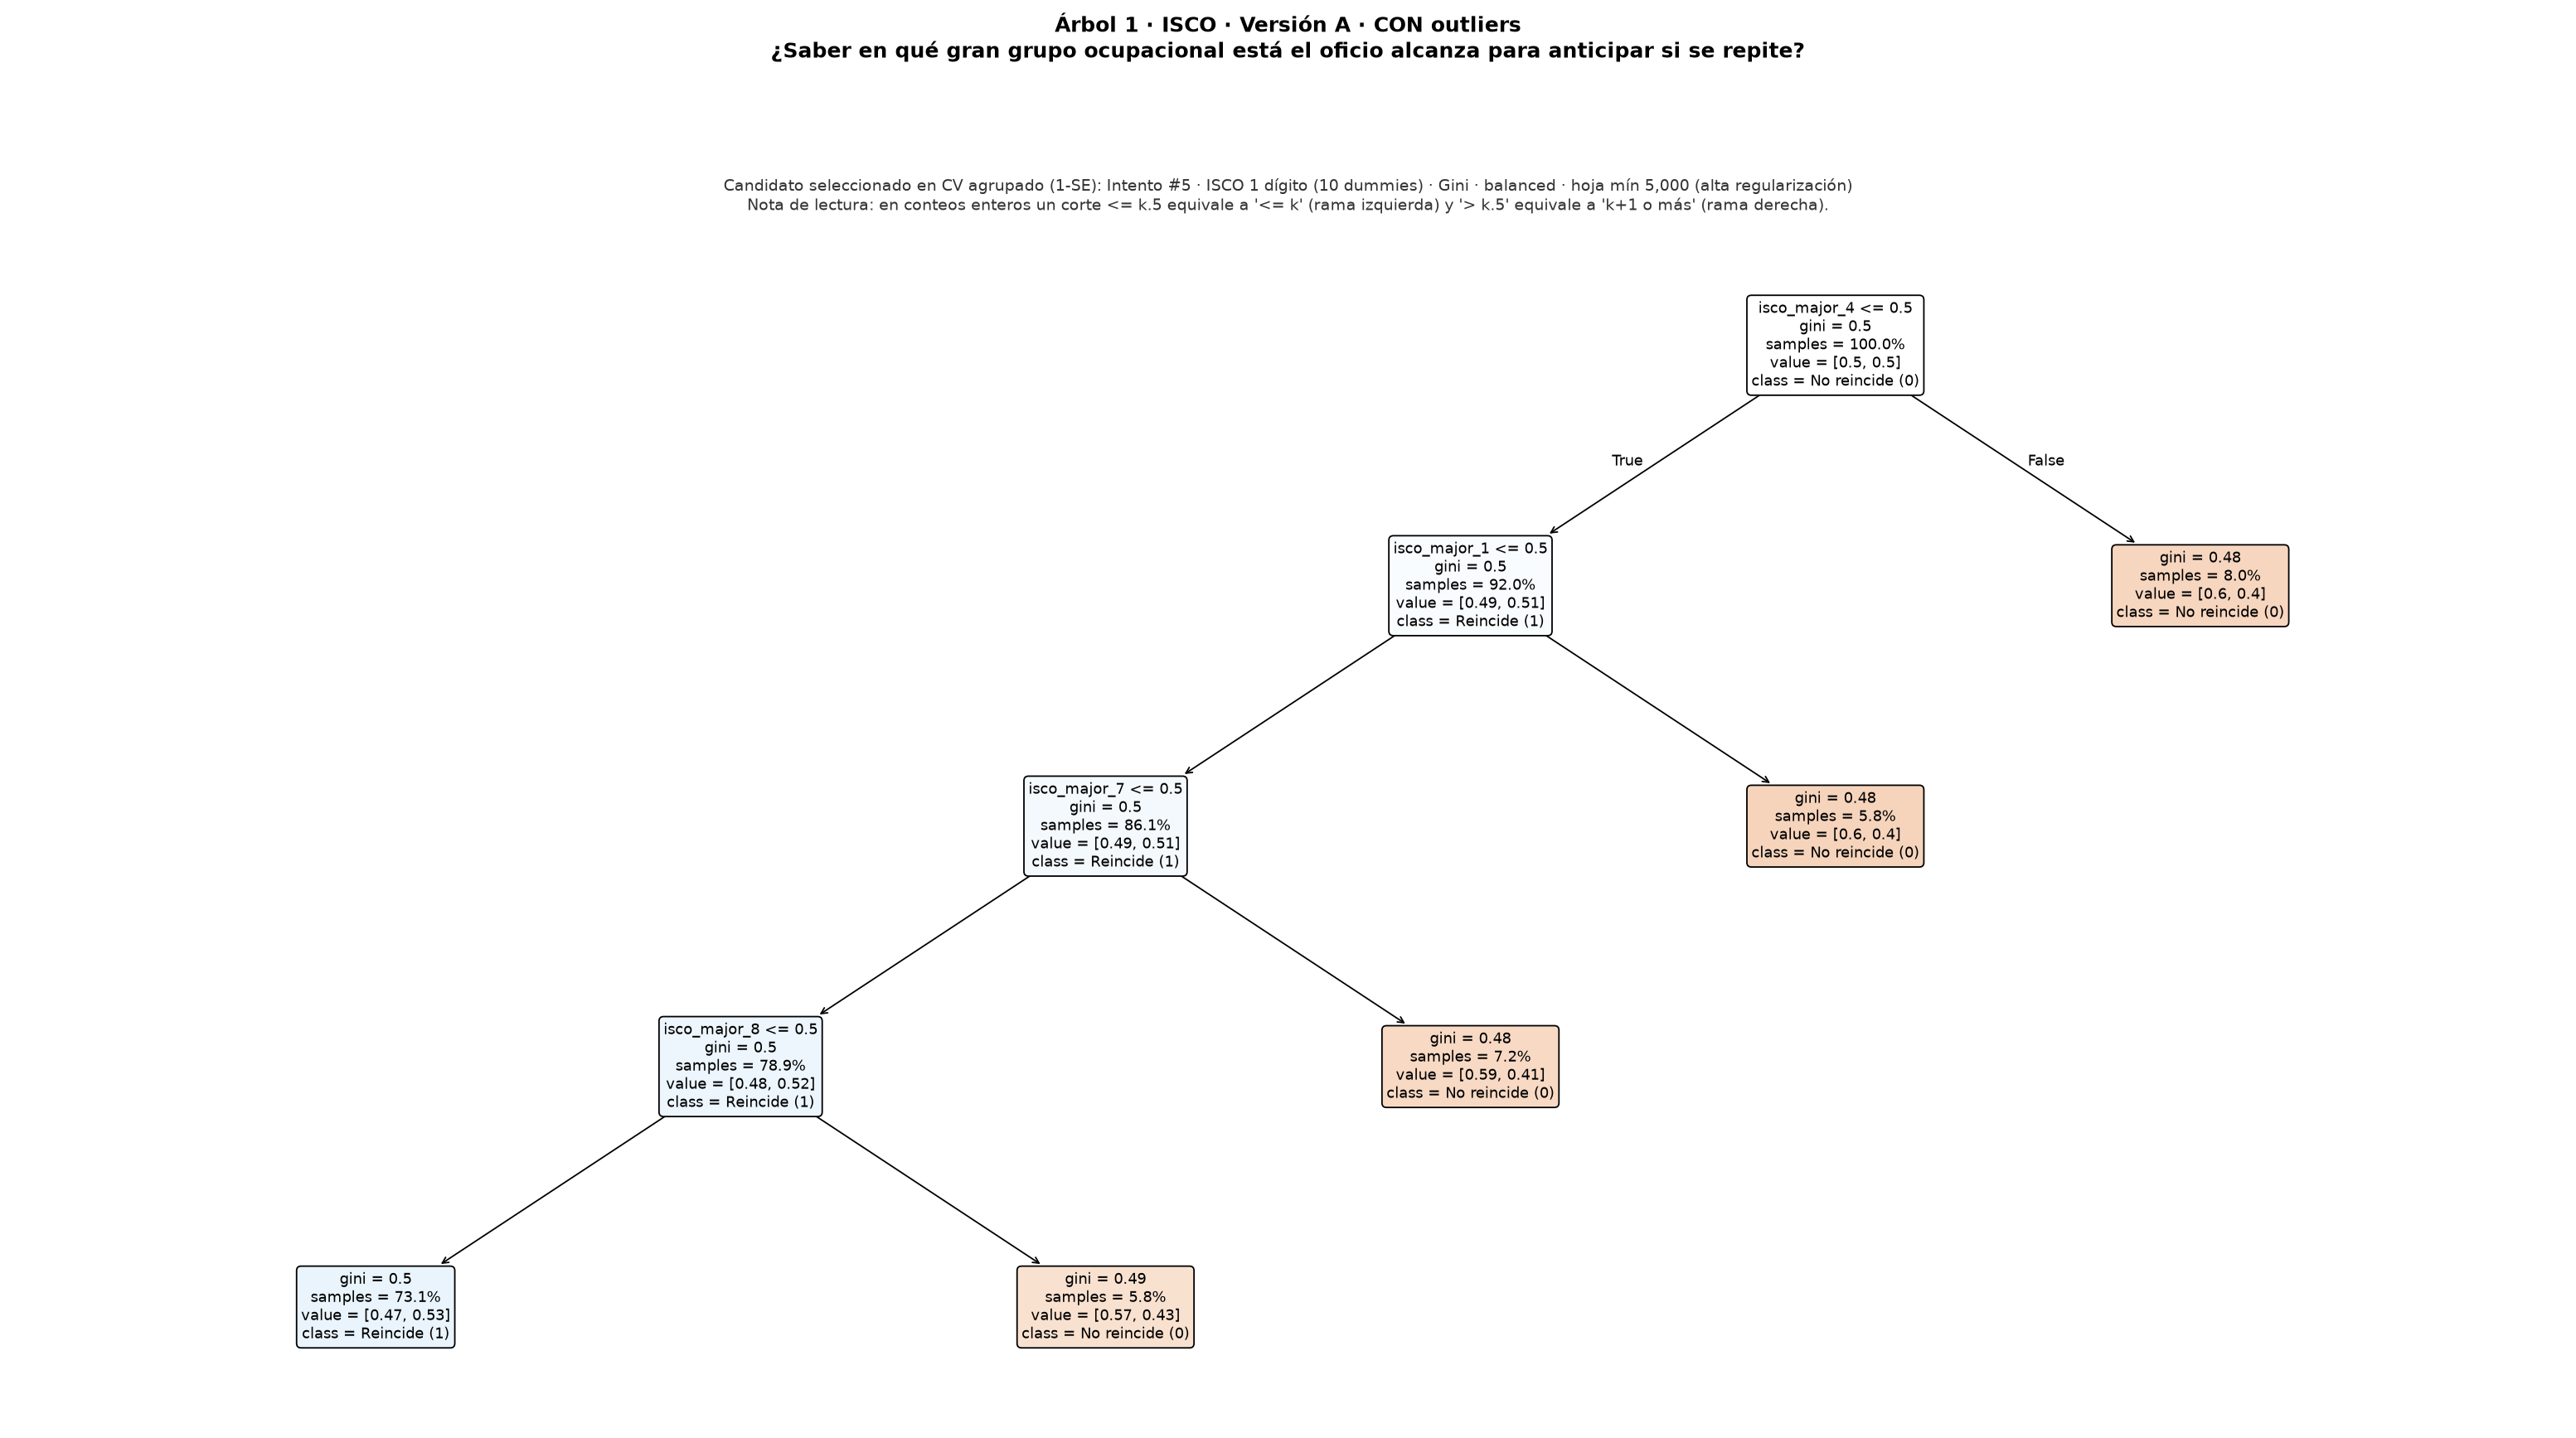

#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión A · CON outliers`

|--- isco_major_4 <= 0.50
|   |--- isco_major_1 <= 0.50
|   |   |--- isco_major_7 <= 0.50
|   |   |   |--- isco_major_8 <= 0.50
|   |   |   |   |--- weights: [489976.19, 552159.22] class: 1
|   |   |   |--- isco_major_8 >  0.50
|   |   |   |   |--- weights: [43415.96, 33141.85] class: 0
|   |   |--- isco_major_7 >  0.50
|   |   |   |--- weights: [55137.95, 38636.33] class: 0
|   |--- isco_major_1 >  0.50
|   |   |--- weights: [45097.67, 29778.18] class: 0
|--- isco_major_4 >  0.50
|   |--- weights: [61881.24, 41793.42] class: 0



#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión A · CON outliers`

version_datos,particion,nivel_arbol,nodo_id,variable,umbral_sklearn,pregunta_es,n_en_nodo,n_izquierda,pct_izquierda,tasa_clase1_izquierda,lift_izquierda,n_derecha,pct_derecha,tasa_clase1_derecha,lift_derecha
Versión A · CON outliers,Train (80%),Nivel 1 · Raíz (Nodo 0),0,isco_major_4,0.5,¿isco_major_4 <= 0.50? [Izq: NO pertenece a [4 · Personal de apoyo administrativo] | Der: SÍ pertenece a [4 · Personal de apoyo administrativo]],1391018,1279313,91.97,0.3067,1.022,111705,8.03,0.2246,0.748
Versión A · CON outliers,Train (80%),Nivel 2 · Rama Izquierda (Nodo 1),1,isco_major_1,0.5,¿isco_major_1 <= 0.50? [Izq: NO pertenece a [1 · Directores y gerentes] | Der: SÍ pertenece a [1 · Directores y gerentes]],1279313,1198313,93.67,0.3125,1.041,81000,6.33,0.2207,0.735
Versión A · CON outliers,Test (20%),Nivel 1 · Raíz (Nodo 0),0,isco_major_4,0.5,¿isco_major_4 <= 0.50? [Izq: NO pertenece a [4 · Personal de apoyo administrativo] | Der: SÍ pertenece a [4 · Personal de apoyo administrativo]],347720,319936,92.01,0.3062,1.022,27784,7.99,0.2255,0.752
Versión A · CON outliers,Test (20%),Nivel 2 · Rama Izquierda (Nodo 1),1,isco_major_1,0.5,¿isco_major_1 <= 0.50? [Izq: NO pertenece a [1 · Directores y gerentes] | Der: SÍ pertenece a [1 · Directores y gerentes]],319936,300063,93.79,0.3123,1.042,19873,6.21,0.2137,0.713


#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión A · CON outliers`

version_datos,variable,importancia,importancia_pct,descripcion_variable,lectura_metodologica
Versión A · CON outliers,isco_major_7,0.2849,28.49,"Indicador binario (0/1) del Gran Grupo ISCO-08 7 · Oficiales, operarios y artesanos",Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,isco_major_4,0.2800,28.00,Indicador binario (0/1) del Gran Grupo ISCO-08 4 · Personal de apoyo administrativo,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,isco_major_1,0.2567,25.67,Indicador binario (0/1) del Gran Grupo ISCO-08 1 · Directores y gerentes,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,isco_major_8,0.1785,17.85,Indicador binario (0/1) del Gran Grupo ISCO-08 8 · Operadores de instalaciones y máquinas,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,isco_major_0,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 0 · Ocupaciones militares,No utilizada por el árbol en profundidad <= 4
Versión A · CON outliers,isco_major_2,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 2 · Profesionales científicos e intelectuales,No utilizada por el árbol en profundidad <= 4
Versión A · CON outliers,isco_major_5,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 5 · Trabajadores de los servicios y vendedores,No utilizada por el árbol en profundidad <= 4
Versión A · CON outliers,isco_major_3,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 3 · Técnicos y profesionales de nivel medio,No utilizada por el árbol en profundidad <= 4
Versión A · CON outliers,isco_major_6,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 6 · Agricultores y trabajadores agropecuarios,No utilizada por el árbol en profundidad <= 4
Versión A · CON outliers,isco_major_9,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 9 · Ocupaciones elementales,No utilizada por el árbol en profundidad <= 4


#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión A · CON outliers`

version_datos,punto_operacion,hoja_id,profundidad,predice_reincide,n_train,pct_train,tasa_clase1_train,wilson_ic95_train,tasa_base_train,lift_train,n_test,pct_test,tasa_clase1_test,wilson_ic95_test,wilson_ic95_test_inf,wilson_ic95_test_sup,tasa_base_test,lift_test,soporte_suficiente_train,soporte_suficiente_test,condiciones_hoja_es
Versión A · CON outliers,class_weight='balanced',4,4,1,1017277,73.13,0.3258,"[0.3249, 0.3267]",0.3001,1.086,254958,73.32,0.3254,"[0.3236, 0.3273]",0.3236,0.3273,0.2997,1.086,Sí,Sí,"NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y NO pertenece a [7 · Oficiales, operarios y artesanos] Y NO pertenece a [8 · Operadores de instalaciones y máquinas]"
Versión A · CON outliers,class_weight='balanced',5,4,0,80665,5.80,0.2466,"[0.2437, 0.2496]",0.3001,0.822,20103,5.78,0.2471,"[0.2412, 0.2531]",0.2412,0.2531,0.2997,0.824,Sí,Sí,"NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y NO pertenece a [7 · Oficiales, operarios y artesanos] Y SÍ pertenece a [8 · Operadores de instalaciones y máquinas]"
Versión A · CON outliers,class_weight='balanced',6,3,0,100371,7.22,0.2311,"[0.2285, 0.2337]",0.3001,0.770,25002,7.19,0.2308,"[0.2256, 0.2361]",0.2256,0.2361,0.2997,0.770,Sí,Sí,"NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y SÍ pertenece a [7 · Oficiales, operarios y artesanos]"
Versión A · CON outliers,class_weight='balanced',8,1,0,111705,8.03,0.2246,"[0.2221, 0.2270]",0.3001,0.748,27784,7.99,0.2255,"[0.2206, 0.2304]",0.2206,0.2304,0.2997,0.752,Sí,Sí,SÍ pertenece a [4 · Personal de apoyo administrativo]
Versión A · CON outliers,class_weight='balanced',7,2,0,81000,5.82,0.2207,"[0.2178, 0.2235]",0.3001,0.735,19873,5.72,0.2137,"[0.2081, 0.2195]",0.2081,0.2195,0.2997,0.713,Sí,Sí,NO pertenece a [4 · Personal de apoyo administrativo] Y SÍ pertenece a [1 · Directores y gerentes]


#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión A · CON outliers`

version_datos,regla_num,hoja_id,predice_reincide,n_registros_train,tasa_clase1_train_pct,lift_train,n_registros_test,tasa_clase1_test_pct,wilson_ic95_test,lift_test,regla_negocio_espanol,advertencia_lo_que_no_dice
Versión A · CON outliers,1,4,1,1017277,32.58,1.086,254958,32.54,"[0.3236, 0.3273]",1.086,"Regla 1 (Árbol 1 · ISCO · Versión A · CON outliers, Hoja 4): SI el registro de empleo cumple que [NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y NO pertenece a [7 · Oficiales, operarios y artesanos] Y NO pertenece a [8 · Operadores de instalaciones y máquinas]], ENTONCES el árbol ubica el perfil del oficio con mayor propensión a repetición (predice reincide = 1 en punto balanceado). En Train agrupa 1,017,277 registros (73.13% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 32.58% frente a la tasa base de 30.01% (Lift = 1.086x). En Test comprende 254,958 registros (73.32%) con tasa de 32.54% (IC95% Wilson = [0.3236, 0.3273]) frente a 29.97% base (Lift = 1.086x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."
Versión A · CON outliers,2,7,0,81000,22.07,0.735,19873,21.37,"[0.2081, 0.2195]",0.713,"Regla 2 (Árbol 1 · ISCO · Versión A · CON outliers, Hoja 7): SI el registro de empleo cumple que [NO pertenece a [4 · Personal de apoyo administrativo] Y SÍ pertenece a [1 · Directores y gerentes]], ENTONCES el árbol ubica el perfil del oficio con menor propensión a repetición / ejercicio único (predice reincide = 0). En Train agrupa 81,000 registros (5.82% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 22.07% frente a la tasa base de 30.01% (Lift = 0.735x). En Test comprende 19,873 registros (5.72%) con tasa de 21.37% (IC95% Wilson = [0.2081, 0.2195]) frente a 29.97% base (Lift = 0.713x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."


In [4]:
# Section 4.1: Árbol 1 · ISCO on Version A (CON outliers)
bundle_a_curr = bundles_a["tree_1_isco"]
cm_none_a = bundle_a_curr.confusion_matrices_by_point["Punto 1 · Orientado a Exactitud (class_weight=None)"]["test"]
cm_bal_a = bundle_a_curr.confusion_matrices_by_point["Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced')"]["test"]

display(Markdown(f"#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión A · CON outliers`\n**Pregunta**: *¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?*"))
display(bundle_a_curr.operating_points_df)

display(Markdown(f"#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión A · CON outliers`"))
display(bundle_a_curr.depth_df)

fig_panel_a = plot_depth_and_confusion_panel(
    depth_df=bundle_a_curr.depth_df,
    cm_test_none=cm_none_a,
    cm_test_balanced=cm_bal_a,
    tree_label_es=bundle_a_curr.tree_label_es,
    question_es=bundle_a_curr.question_es,
    version_label_es=bundle_a_curr.version_label_es,
    output_path=CONFIG.figures_dir / "01_arbol_1_isco_panel_version_a.png",
)
plt.show()
plt.close(fig_panel_a)

fig_tree_a = plot_decision_tree_legible(
    clf=bundle_a_curr.tuning_result.fitted_tree_balanced,
    feature_names=list(bundle_a_curr.tuning_result.X_train.columns),
    tree_label_es=bundle_a_curr.tree_label_es,
    question_es=bundle_a_curr.question_es,
    version_label_es=bundle_a_curr.version_label_es,
    subtitle_es=f"Candidato seleccionado en CV agrupado (1-SE): Intento #{bundle_a_curr.tuning_result.selected_attempt_id} · {bundle_a_curr.tuning_result.selected_spec.description_es}",
    output_path=CONFIG.figures_dir / "01_arbol_1_isco_tree_depth4_version_a.png",
)
plt.show()
plt.close(fig_tree_a)

display(Markdown(f"#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión A · CON outliers`"))
print(bundle_a_curr.export_text_balanced_str)

display(Markdown(f"#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión A · CON outliers`"))
display(pd.concat([bundle_a_curr.first_questions_train_df, bundle_a_curr.first_questions_test_df], ignore_index=True))

display(Markdown(f"#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión A · CON outliers`"))
display(bundle_a_curr.importances_df.head(10))

display(Markdown(f"#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión A · CON outliers`"))
display(bundle_a_curr.leaf_lift_balanced_df)

display(Markdown(f"#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión A · CON outliers`"))
display(bundle_a_curr.business_rules_df[["version_datos", "regla_num", "hoja_id", "predice_reincide", "n_registros_train", "tasa_clase1_train_pct", "lift_train", "n_registros_test", "tasa_clase1_test_pct", "wilson_ic95_test", "lift_test", "regla_negocio_espanol", "advertencia_lo_que_no_dice"]])

### 4.2 Sección `Versión B · SIN outliers` — ¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?
A continuación replicamos exactamente el mismo análisis, partición por persona, variables e hiperparámetros sobre **`Versión B · SIN outliers`** (datos winsorizados por IQR), manteniendo todas las etiquetas de versión explícitas en tablas y gráficos.

#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión B · SIN outliers`
**Pregunta**: *¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?*

version_datos,arbol,pregunta_objetivo,punto_operacion,regla_decision,profundidad_efectiva,n_hojas,train_accuracy,test_accuracy,test_accuracy_ic95_persona,gap_acc_train_test,train_precision_1,test_precision_1,train_recall_1,test_recall_1,test_recall_1_ic95_persona,train_f1_1,test_f1_1,test_f1_1_ic95_persona,f1_ref_trivial_todo_1,delta_f1_vs_trivial_todo_1,train_roc_auc,test_roc_auc,test_roc_auc_ic95_persona,roc_auc_ic95_inf,roc_auc_ic95_sup,roc_auc_techo_6_0,pct_del_techo_auc_6_0,hoja_elegida_en_train_id,lift_train_hoja_elegida,max_lift_hoja_soporte_05pct,max_lift_test_referencia_optimista,hoja_con_lift_ge_150_y_soporte_05pct,criterio_separa_clases,supera_baseline_exactitud_7003,brecha_vs_meta_085_f1,tn_test,fp_test,fn_test,tp_test
Versión B · SIN outliers,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Punto 1 · Orientado a Exactitud (class_weight=None),Umbral estándar 0.50 sobre tasa empírica de hoja,4,5,0.6999,0.7003,"[0.6981, 0.7025]",-0.0004,0.0000,0.0000,0.0000,0.0000,"[0.0000, 0.0000]",0.000,0.000,"[0.0000, 0.0000]",0.4612,-0.4612,0.5455,0.5459,"[0.5436, 0.5482]",0.5436,0.5482,0.7132,21.54,4,1.086,1.086,1.086,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),Empata el baseline porque no predice ningún positivo,0.850,243495,0,104225,0
Versión B · SIN outliers,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),Pesos balanceados inversamente proporcionales a 70/30,4,5,0.4451,0.4443,"[0.4420, 0.4461]",0.0008,0.3258,0.3254,0.7939,0.7961,"[0.7922, 0.8002]",0.462,0.462,"[0.4588, 0.4648]",0.4612,0.0008,0.5455,0.5459,"[0.5436, 0.5482]",0.5436,0.5482,0.7132,21.54,4,1.086,1.086,1.086,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),No (prioriza Recall sobre exactitud global),0.388,71512,171983,21250,82975
Versión B · SIN outliers,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Punto 3 · Umbral OOF óptimo en Train (tau*=0.330),Predice 1 si P(reincide=1|hoja) >= 0.330 (sujeto a Acc >= Baseline en OOF Train),4,5,0.6999,0.7003,"[0.6981, 0.7025]",-0.0004,0.0000,0.0000,0.0000,0.0000,"[0.0000, 0.0000]",0.000,0.000,"[0.0000, 0.0000]",0.4612,-0.4612,0.5455,0.5459,"[0.5436, 0.5482]",0.5436,0.5482,0.7132,21.54,4,1.086,1.086,1.086,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),Empata el baseline porque no predice ningún positivo,0.850,243495,0,104225,0


#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión B · SIN outliers`

version_datos,arbol,punto_operacion,max_depth,profundidad_alcanzada,n_leaves,train_acc,test_acc,gap_train_test,train_f1_clase_1,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,test_roc_auc
Versión B · SIN outliers,Árbol 1 · ISCO,class_weight=None (Exactitud),2,2,3,0.6999,0.7003,-0.0004,0.0000,0.0000,0.0000,0.0000,0.5260
Versión B · SIN outliers,Árbol 1 · ISCO,class_weight=None (Exactitud),3,3,4,0.6999,0.7003,-0.0004,0.0000,0.0000,0.0000,0.0000,0.5380
Versión B · SIN outliers,Árbol 1 · ISCO,class_weight=None (Exactitud),4,4,5,0.6999,0.7003,-0.0004,0.0000,0.0000,0.0000,0.0000,0.5459
Versión B · SIN outliers,Árbol 1 · ISCO,class_weight='balanced' (Recall),2,2,3,0.3769,0.3763,0.0006,0.4636,0.3123,0.8991,0.4636,0.5260
Versión B · SIN outliers,Árbol 1 · ISCO,class_weight='balanced' (Recall),3,3,4,0.4157,0.4150,0.0007,0.4637,0.3197,0.8438,0.4637,0.5380
Versión B · SIN outliers,Árbol 1 · ISCO,class_weight='balanced' (Recall),4,4,5,0.4451,0.4443,0.0008,0.4620,0.3254,0.7961,0.4620,0.5459


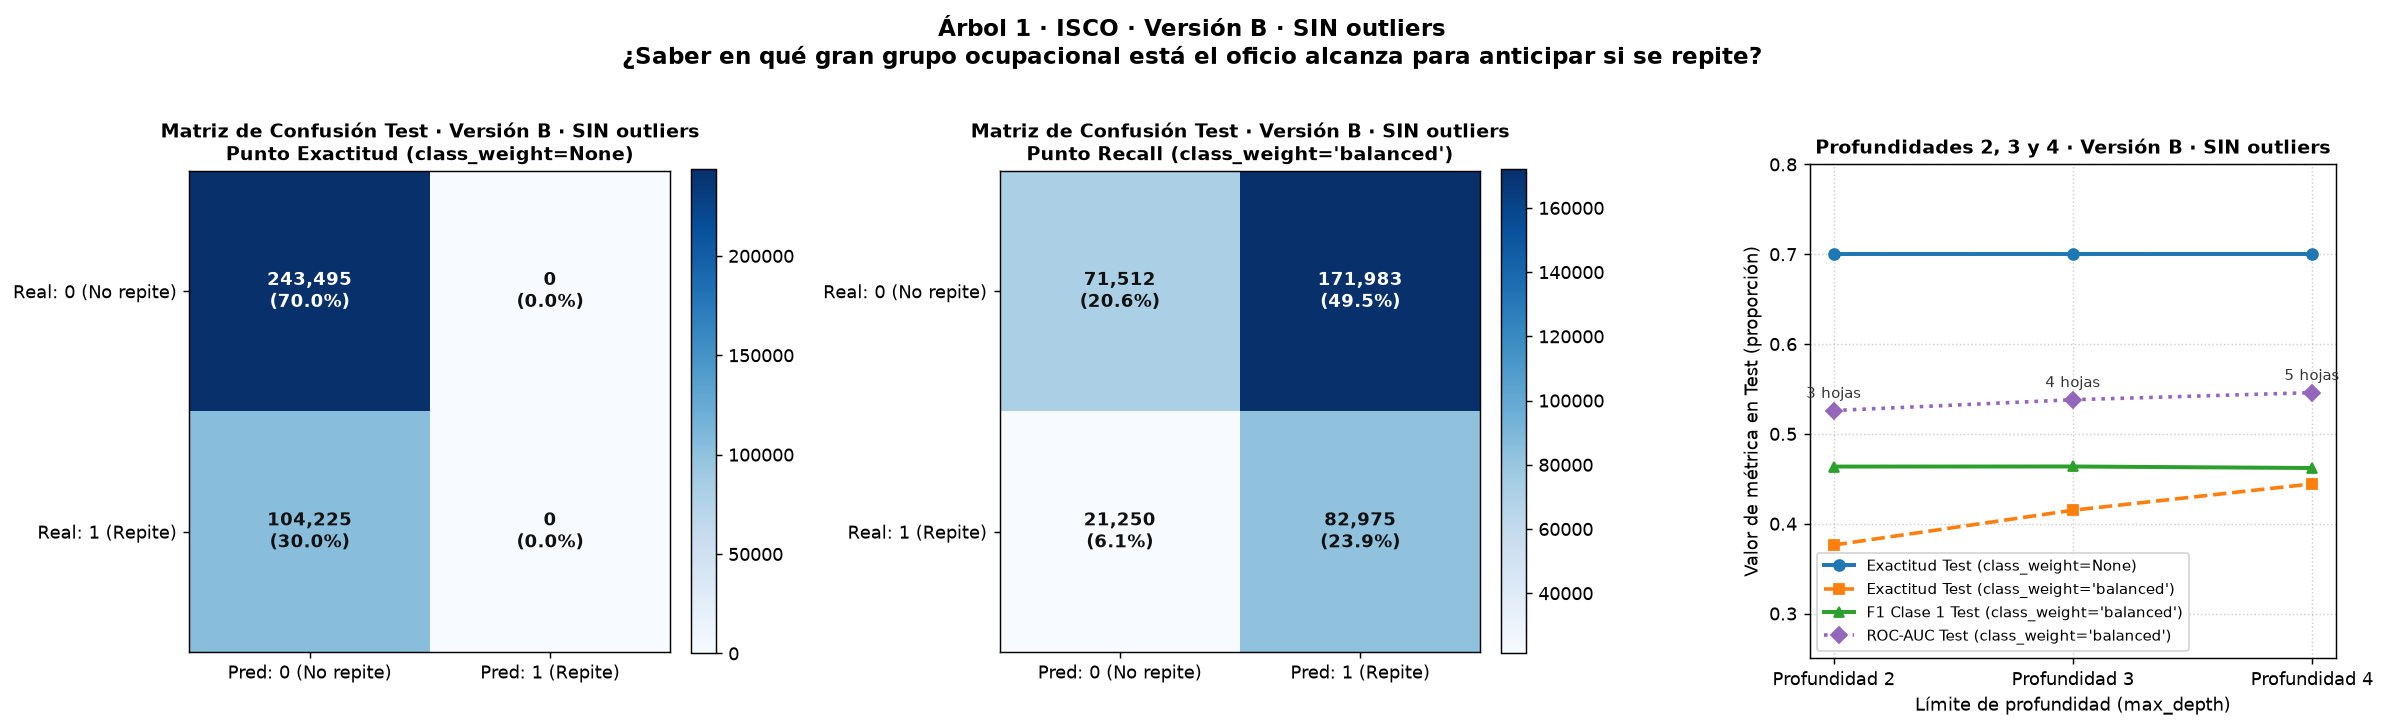

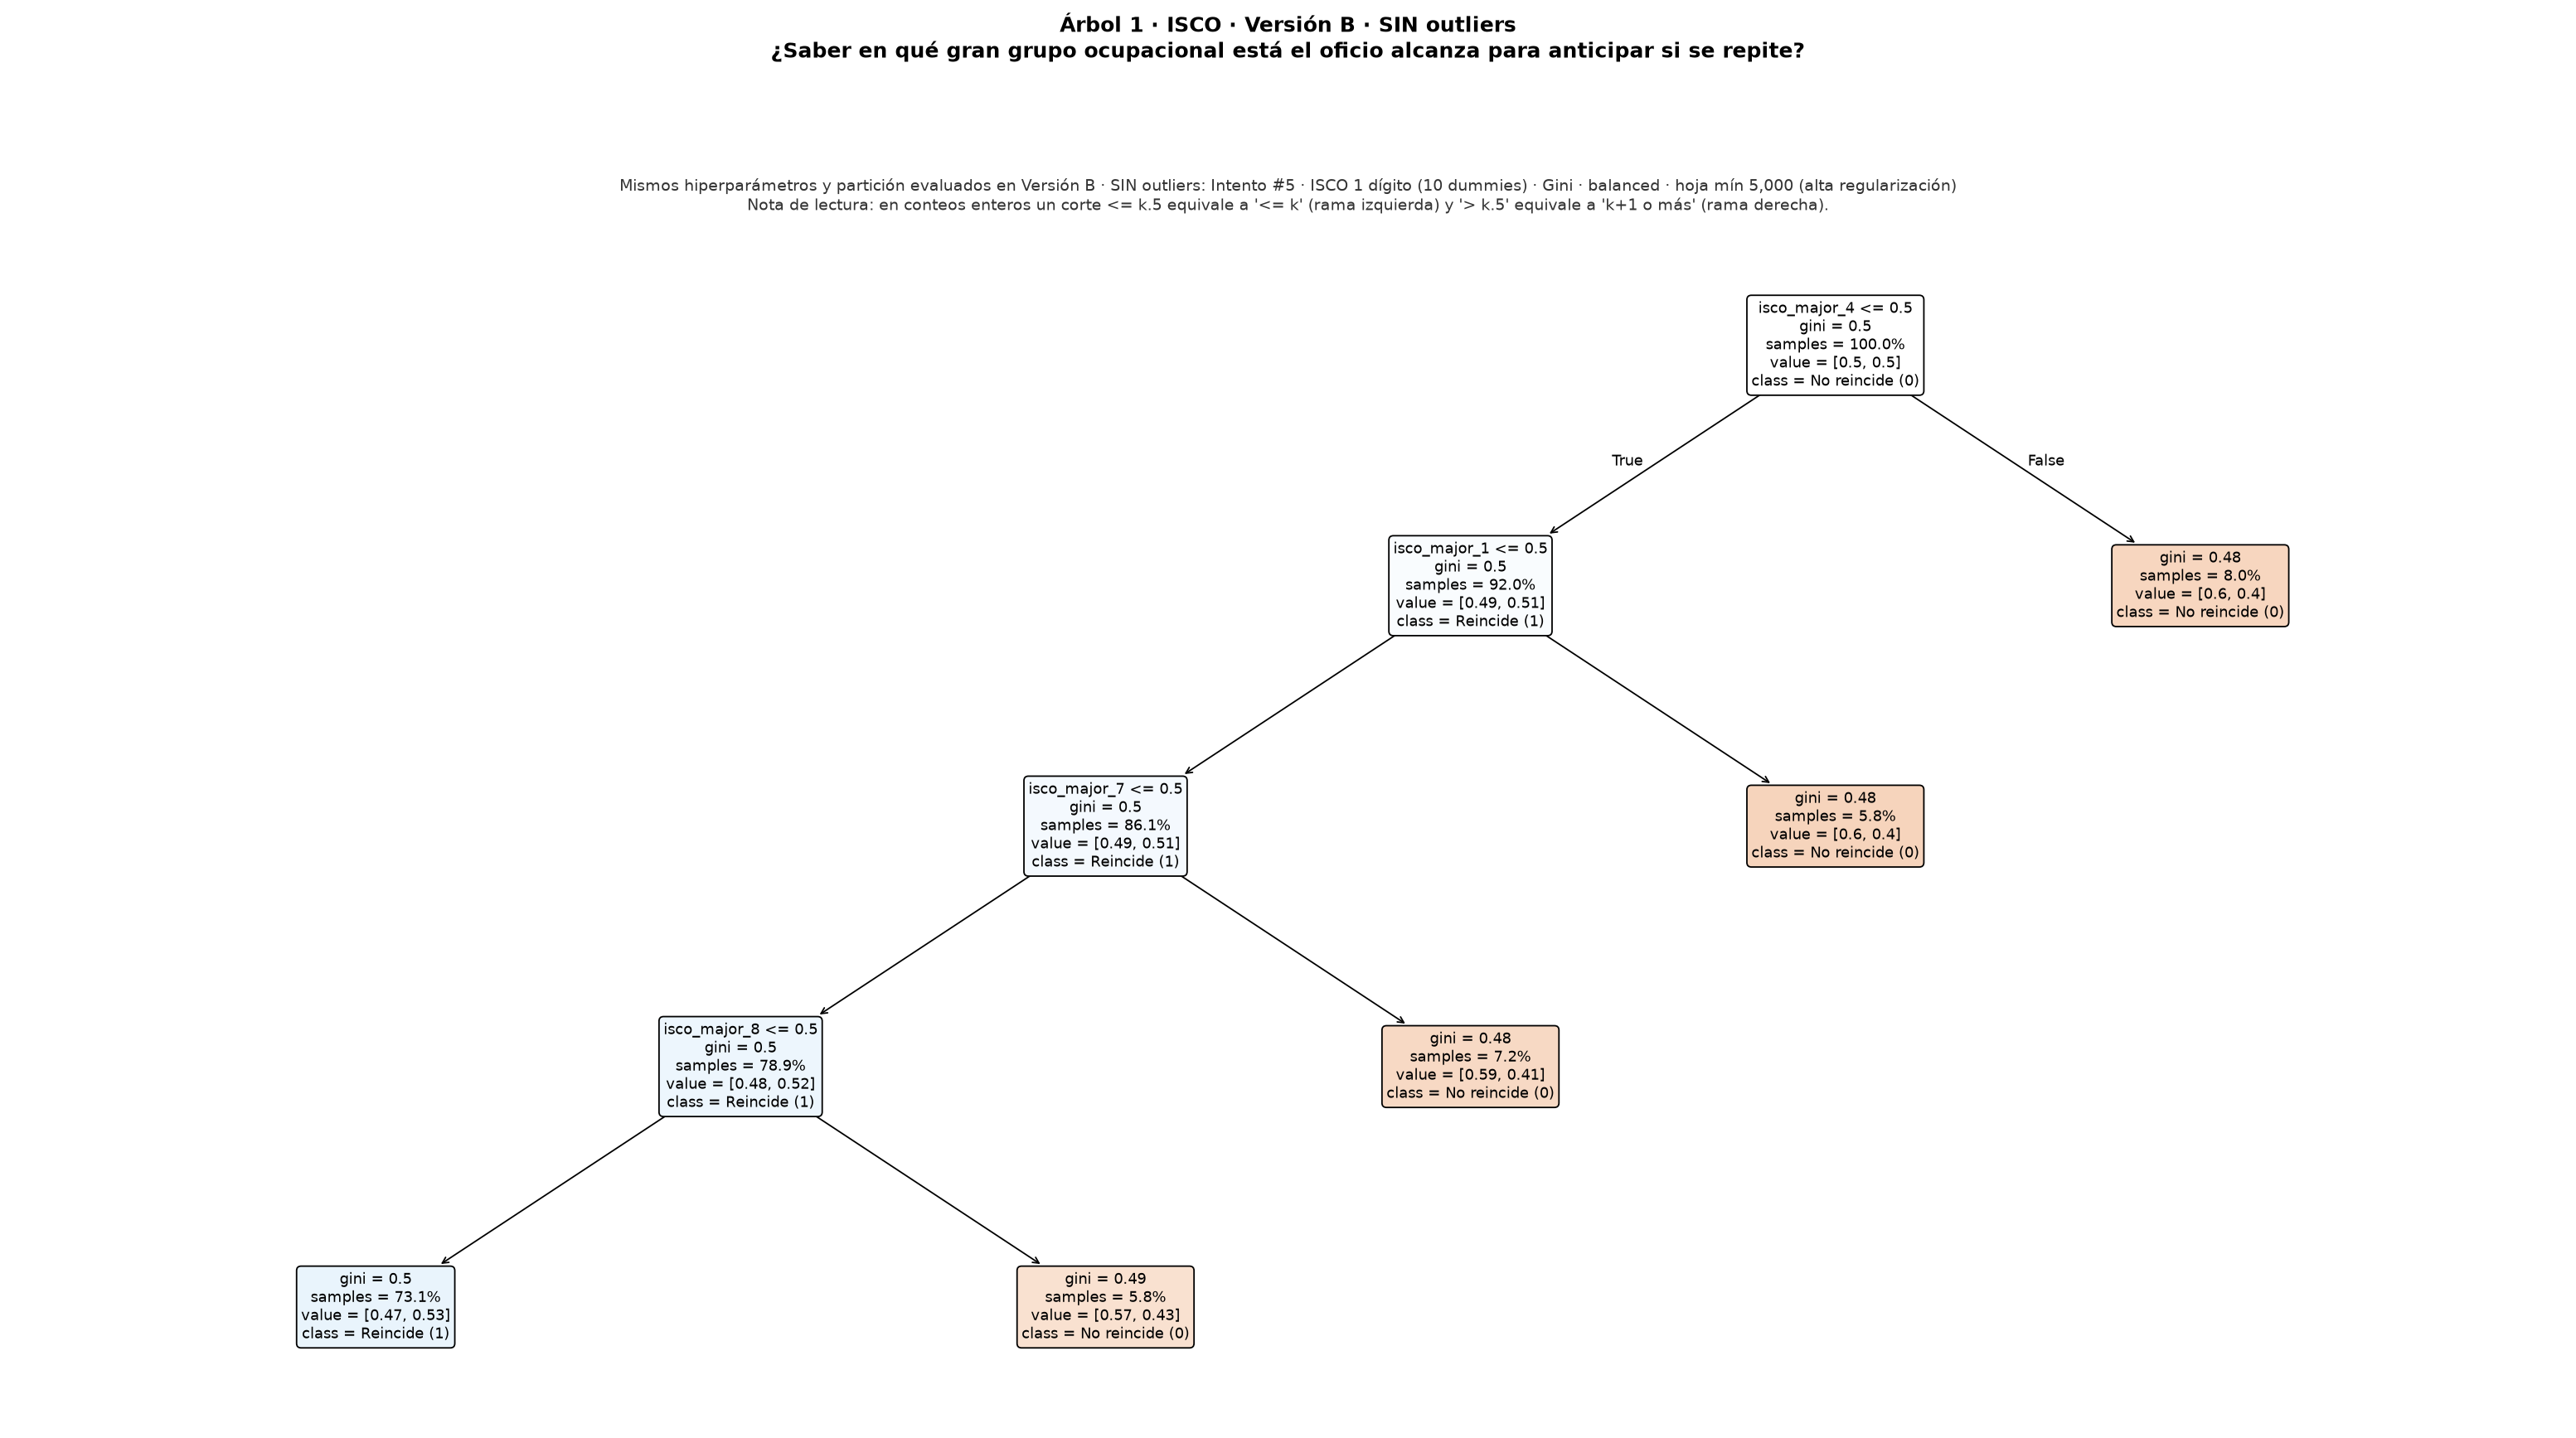

#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión B · SIN outliers`

|--- isco_major_4 <= 0.50
|   |--- isco_major_1 <= 0.50
|   |   |--- isco_major_7 <= 0.50
|   |   |   |--- isco_major_8 <= 0.50
|   |   |   |   |--- weights: [489976.19, 552159.22] class: 1
|   |   |   |--- isco_major_8 >  0.50
|   |   |   |   |--- weights: [43415.96, 33141.85] class: 0
|   |   |--- isco_major_7 >  0.50
|   |   |   |--- weights: [55137.95, 38636.33] class: 0
|   |--- isco_major_1 >  0.50
|   |   |--- weights: [45097.67, 29778.18] class: 0
|--- isco_major_4 >  0.50
|   |--- weights: [61881.24, 41793.42] class: 0



#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión B · SIN outliers`

version_datos,particion,nivel_arbol,nodo_id,variable,umbral_sklearn,pregunta_es,n_en_nodo,n_izquierda,pct_izquierda,tasa_clase1_izquierda,lift_izquierda,n_derecha,pct_derecha,tasa_clase1_derecha,lift_derecha
Versión B · SIN outliers,Train (80%),Nivel 1 · Raíz (Nodo 0),0,isco_major_4,0.5,¿isco_major_4 <= 0.50? [Izq: NO pertenece a [4 · Personal de apoyo administrativo] | Der: SÍ pertenece a [4 · Personal de apoyo administrativo]],1391018,1279313,91.97,0.3067,1.022,111705,8.03,0.2246,0.748
Versión B · SIN outliers,Train (80%),Nivel 2 · Rama Izquierda (Nodo 1),1,isco_major_1,0.5,¿isco_major_1 <= 0.50? [Izq: NO pertenece a [1 · Directores y gerentes] | Der: SÍ pertenece a [1 · Directores y gerentes]],1279313,1198313,93.67,0.3125,1.041,81000,6.33,0.2207,0.735
Versión B · SIN outliers,Test (20%),Nivel 1 · Raíz (Nodo 0),0,isco_major_4,0.5,¿isco_major_4 <= 0.50? [Izq: NO pertenece a [4 · Personal de apoyo administrativo] | Der: SÍ pertenece a [4 · Personal de apoyo administrativo]],347720,319936,92.01,0.3062,1.022,27784,7.99,0.2255,0.752
Versión B · SIN outliers,Test (20%),Nivel 2 · Rama Izquierda (Nodo 1),1,isco_major_1,0.5,¿isco_major_1 <= 0.50? [Izq: NO pertenece a [1 · Directores y gerentes] | Der: SÍ pertenece a [1 · Directores y gerentes]],319936,300063,93.79,0.3123,1.042,19873,6.21,0.2137,0.713


#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión B · SIN outliers`

version_datos,variable,importancia,importancia_pct,descripcion_variable,lectura_metodologica
Versión B · SIN outliers,isco_major_7,0.2849,28.49,"Indicador binario (0/1) del Gran Grupo ISCO-08 7 · Oficiales, operarios y artesanos",Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,isco_major_4,0.2800,28.00,Indicador binario (0/1) del Gran Grupo ISCO-08 4 · Personal de apoyo administrativo,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,isco_major_1,0.2567,25.67,Indicador binario (0/1) del Gran Grupo ISCO-08 1 · Directores y gerentes,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,isco_major_8,0.1785,17.85,Indicador binario (0/1) del Gran Grupo ISCO-08 8 · Operadores de instalaciones y máquinas,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,isco_major_0,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 0 · Ocupaciones militares,No utilizada por el árbol en profundidad <= 4
Versión B · SIN outliers,isco_major_2,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 2 · Profesionales científicos e intelectuales,No utilizada por el árbol en profundidad <= 4
Versión B · SIN outliers,isco_major_5,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 5 · Trabajadores de los servicios y vendedores,No utilizada por el árbol en profundidad <= 4
Versión B · SIN outliers,isco_major_3,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 3 · Técnicos y profesionales de nivel medio,No utilizada por el árbol en profundidad <= 4
Versión B · SIN outliers,isco_major_6,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 6 · Agricultores y trabajadores agropecuarios,No utilizada por el árbol en profundidad <= 4
Versión B · SIN outliers,isco_major_9,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 9 · Ocupaciones elementales,No utilizada por el árbol en profundidad <= 4


#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión B · SIN outliers`

version_datos,punto_operacion,hoja_id,profundidad,predice_reincide,n_train,pct_train,tasa_clase1_train,wilson_ic95_train,tasa_base_train,lift_train,n_test,pct_test,tasa_clase1_test,wilson_ic95_test,wilson_ic95_test_inf,wilson_ic95_test_sup,tasa_base_test,lift_test,soporte_suficiente_train,soporte_suficiente_test,condiciones_hoja_es
Versión B · SIN outliers,class_weight='balanced',4,4,1,1017277,73.13,0.3258,"[0.3249, 0.3267]",0.3001,1.086,254958,73.32,0.3254,"[0.3236, 0.3273]",0.3236,0.3273,0.2997,1.086,Sí,Sí,"NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y NO pertenece a [7 · Oficiales, operarios y artesanos] Y NO pertenece a [8 · Operadores de instalaciones y máquinas]"
Versión B · SIN outliers,class_weight='balanced',5,4,0,80665,5.80,0.2466,"[0.2437, 0.2496]",0.3001,0.822,20103,5.78,0.2471,"[0.2412, 0.2531]",0.2412,0.2531,0.2997,0.824,Sí,Sí,"NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y NO pertenece a [7 · Oficiales, operarios y artesanos] Y SÍ pertenece a [8 · Operadores de instalaciones y máquinas]"
Versión B · SIN outliers,class_weight='balanced',6,3,0,100371,7.22,0.2311,"[0.2285, 0.2337]",0.3001,0.770,25002,7.19,0.2308,"[0.2256, 0.2361]",0.2256,0.2361,0.2997,0.770,Sí,Sí,"NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y SÍ pertenece a [7 · Oficiales, operarios y artesanos]"
Versión B · SIN outliers,class_weight='balanced',8,1,0,111705,8.03,0.2246,"[0.2221, 0.2270]",0.3001,0.748,27784,7.99,0.2255,"[0.2206, 0.2304]",0.2206,0.2304,0.2997,0.752,Sí,Sí,SÍ pertenece a [4 · Personal de apoyo administrativo]
Versión B · SIN outliers,class_weight='balanced',7,2,0,81000,5.82,0.2207,"[0.2178, 0.2235]",0.3001,0.735,19873,5.72,0.2137,"[0.2081, 0.2195]",0.2081,0.2195,0.2997,0.713,Sí,Sí,NO pertenece a [4 · Personal de apoyo administrativo] Y SÍ pertenece a [1 · Directores y gerentes]


#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión B · SIN outliers`

version_datos,regla_num,hoja_id,predice_reincide,n_registros_train,tasa_clase1_train_pct,lift_train,n_registros_test,tasa_clase1_test_pct,wilson_ic95_test,lift_test,regla_negocio_espanol,advertencia_lo_que_no_dice
Versión B · SIN outliers,1,4,1,1017277,32.58,1.086,254958,32.54,"[0.3236, 0.3273]",1.086,"Regla 1 (Árbol 1 · ISCO · Versión B · SIN outliers, Hoja 4): SI el registro de empleo cumple que [NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y NO pertenece a [7 · Oficiales, operarios y artesanos] Y NO pertenece a [8 · Operadores de instalaciones y máquinas]], ENTONCES el árbol ubica el perfil del oficio con mayor propensión a repetición (predice reincide = 1 en punto balanceado). En Train agrupa 1,017,277 registros (73.13% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 32.58% frente a la tasa base de 30.01% (Lift = 1.086x). En Test comprende 254,958 registros (73.32%) con tasa de 32.54% (IC95% Wilson = [0.3236, 0.3273]) frente a 29.97% base (Lift = 1.086x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."
Versión B · SIN outliers,2,7,0,81000,22.07,0.735,19873,21.37,"[0.2081, 0.2195]",0.713,"Regla 2 (Árbol 1 · ISCO · Versión B · SIN outliers, Hoja 7): SI el registro de empleo cumple que [NO pertenece a [4 · Personal de apoyo administrativo] Y SÍ pertenece a [1 · Directores y gerentes]], ENTONCES el árbol ubica el perfil del oficio con menor propensión a repetición / ejercicio único (predice reincide = 0). En Train agrupa 81,000 registros (5.82% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 22.07% frente a la tasa base de 30.01% (Lift = 0.735x). En Test comprende 19,873 registros (5.72%) con tasa de 21.37% (IC95% Wilson = [0.2081, 0.2195]) frente a 29.97% base (Lift = 0.713x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."


In [5]:
# Section 4.2: Árbol 1 · ISCO on Version B (SIN outliers)
bundle_b_curr = bundles_b["tree_1_isco"]
cm_none_b = bundle_b_curr.confusion_matrices_by_point["Punto 1 · Orientado a Exactitud (class_weight=None)"]["test"]
cm_bal_b = bundle_b_curr.confusion_matrices_by_point["Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced')"]["test"]

display(Markdown(f"#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión B · SIN outliers`\n**Pregunta**: *¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?*"))
display(bundle_b_curr.operating_points_df)

display(Markdown(f"#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión B · SIN outliers`"))
display(bundle_b_curr.depth_df)

fig_panel_b = plot_depth_and_confusion_panel(
    depth_df=bundle_b_curr.depth_df,
    cm_test_none=cm_none_b,
    cm_test_balanced=cm_bal_b,
    tree_label_es=bundle_b_curr.tree_label_es,
    question_es=bundle_b_curr.question_es,
    version_label_es=bundle_b_curr.version_label_es,
    output_path=CONFIG.figures_dir / "01_arbol_1_isco_panel_version_b.png",
)
plt.show()
plt.close(fig_panel_b)

fig_tree_b = plot_decision_tree_legible(
    clf=bundle_b_curr.tuning_result.fitted_tree_balanced,
    feature_names=list(bundle_b_curr.tuning_result.X_train.columns),
    tree_label_es=bundle_b_curr.tree_label_es,
    question_es=bundle_b_curr.question_es,
    version_label_es=bundle_b_curr.version_label_es,
    subtitle_es=f"Mismos hiperparámetros y partición evaluados en Versión B · SIN outliers: Intento #{bundle_b_curr.tuning_result.selected_attempt_id} · {bundle_b_curr.tuning_result.selected_spec.description_es}",
    output_path=CONFIG.figures_dir / "01_arbol_1_isco_tree_depth4_version_b.png",
)
plt.show()
plt.close(fig_tree_b)

display(Markdown(f"#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión B · SIN outliers`"))
print(bundle_b_curr.export_text_balanced_str)

display(Markdown(f"#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión B · SIN outliers`"))
display(pd.concat([bundle_b_curr.first_questions_train_df, bundle_b_curr.first_questions_test_df], ignore_index=True))

display(Markdown(f"#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión B · SIN outliers`"))
display(bundle_b_curr.importances_df.head(10))

display(Markdown(f"#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión B · SIN outliers`"))
display(bundle_b_curr.leaf_lift_balanced_df)

display(Markdown(f"#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión B · SIN outliers`"))
display(bundle_b_curr.business_rules_df[["version_datos", "regla_num", "hoja_id", "predice_reincide", "n_registros_train", "tasa_clase1_train_pct", "lift_train", "n_registros_test", "tasa_clase1_test_pct", "wilson_ic95_test", "lift_test", "regla_negocio_espanol", "advertencia_lo_que_no_dice"]])

### 4.3 Tabla Comparativa Lado a Lado y Lectura Dinámica: `Versión A · CON outliers` vs. `Versión B · SIN outliers` (Árbol 1 · ISCO)

In [6]:
# Section 4.3: Side-by-side Version A vs Version B comparison for Árbol 1 · ISCO (generated dynamically from result objects)
sub_full_curr = sensitivity_result.full_data_ab_table.loc[
    sensitivity_result.full_data_ab_table["bloque_id"] == "tree_1_isco"
].reset_index(drop=True)
sub_sum_curr = sensitivity_result.summary_table.loc[
    sensitivity_result.summary_table["bloque_id"] == "tree_1_isco"
].reset_index(drop=True)
sub_thr_curr = sensitivity_result.threshold_comparison_table.loc[
    sensitivity_result.threshold_comparison_table["bloque_id"] == "tree_1_isco"
].reset_index(drop=True)

display(Markdown("#### A vs. B en el Conjunto Completo (`Train = 1,391,018` / `Test = 347,720`) por Punto de Operación y contraste contra 1 DE entre semillas"))
display(sub_full_curr)

display(Markdown("#### A vs. B en las 5 Semillas de Sensibilidad (`42, 100, 2026, 7, 999` · 3,000 personas Train / 750 Test)"))
display(sub_sum_curr)

display(Markdown("#### Comparación Semilla por Semilla de Umbrales (Raíz y Nivel 2) entre Versión A y Versión B"))
display(sub_thr_curr)

display(Markdown(f"### 4.4 Lectura Comparativa Generada Dinámicamente desde los Objetos de Resultado — ¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?"))
display(
    Markdown(
        build_tree_ab_reading_es(
            block_id="tree_1_isco",
            full_ab_sub=sub_full_curr,
            sum_sub=sub_sum_curr,
            bundle_a=bundles_a["tree_1_isco"],
            bundle_b=bundles_b["tree_1_isco"],
        )
    )
)

#### A vs. B en el Conjunto Completo (`Train = 1,391,018` / `Test = 347,720`) por Punto de Operación y contraste contra 1 DE entre semillas

bloque_id,arbol,pregunta_objetivo,version_datos,punto_operacion,profundidad_efectiva,n_hojas,train_accuracy,test_accuracy,test_precision_1,test_recall_1,test_f1_1,test_roc_auc,umbral_raiz,umbral_nivel2_izq,umbral_nivel2_der,delta_abs_acc_A_vs_B,delta_abs_f1_A_vs_B,std_f1_5_semillas,delta_abs_auc_A_vs_B,std_auc_5_semillas,diferencia_supera_1_std_semillas
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Versión A · CON outliers,Punto Exactitud (class_weight=None),4,5,0.6999,0.7003,0.0000,0.0000,0.000,0.5459,isco_major_4 <= 0.50,isco_major_1 <= 0.50,Hoja terminal,0.0,0.0,0.0134,0.0,0.0048,No (dentro del ruido de muestreo <= 1 SD)
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Versión B · SIN outliers,Punto Exactitud (class_weight=None),4,5,0.6999,0.7003,0.0000,0.0000,0.000,0.5459,isco_major_4 <= 0.50,isco_major_1 <= 0.50,Hoja terminal,0.0,0.0,0.0134,0.0,0.0048,No (dentro del ruido de muestreo <= 1 SD)
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Versión A · CON outliers,Punto Recall (class_weight='balanced'),4,5,0.4451,0.4443,0.3254,0.7961,0.462,0.5459,isco_major_4 <= 0.50,isco_major_1 <= 0.50,Hoja terminal,0.0,0.0,0.0134,0.0,0.0048,No (dentro del ruido de muestreo <= 1 SD)
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Versión B · SIN outliers,Punto Recall (class_weight='balanced'),4,5,0.4451,0.4443,0.3254,0.7961,0.462,0.5459,isco_major_4 <= 0.50,isco_major_1 <= 0.50,Hoja terminal,0.0,0.0,0.0134,0.0,0.0048,No (dentro del ruido de muestreo <= 1 SD)


#### A vs. B en las 5 Semillas de Sensibilidad (`42, 100, 2026, 7, 999` · 3,000 personas Train / 750 Test)

bloque_id,arbol,pregunta_objetivo,version_datos,n_semillas,cv_train_roc_auc_media,cv_train_roc_auc_std,cv_train_acc_media,cv_train_acc_std,cv_train_prec1_media,cv_train_rec1_media,cv_train_f1_media,cv_train_f1_std,test_roc_auc_media,test_roc_auc_std,test_acc_media,test_acc_std,test_prec1_media,test_rec1_media,test_f1_media,test_f1_std,n_hojas_media,fit_time_ms_media,raiz_modal_5_semillas,nivel2_izq_modal,nivel2_der_modal
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Versión A · CON outliers,5,0.5477,0.0018,0.4583,0.0137,0.3248,0.7622,0.4547,0.0067,0.5496,0.0048,0.4506,0.0177,0.3277,0.7946,0.4636,0.0134,5.0,16.13,isco_major_1 <= 0.50,isco_major_4 <= 0.50,Hoja terminal
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Versión B · SIN outliers,5,0.5477,0.0018,0.4583,0.0137,0.3248,0.7622,0.4547,0.0067,0.5496,0.0048,0.4506,0.0177,0.3277,0.7946,0.4636,0.0134,5.0,23.75,isco_major_1 <= 0.50,isco_major_4 <= 0.50,Hoja terminal


#### Comparación Semilla por Semilla de Umbrales (Raíz y Nivel 2) entre Versión A y Versión B

bloque_id,arbol,pregunta_objetivo,semilla,cv_f1_A,cv_f1_B,delta_cv_f1_A_menos_B,test_f1_A,test_f1_B,delta_test_f1_A_menos_B,test_roc_auc_A,test_roc_auc_B,delta_test_auc_A_menos_B,hojas_A,hojas_B,raiz_A,raiz_B,nivel2_izq_A,nivel2_izq_B,nivel2_der_A,nivel2_der_B,misma_raiz_A_y_B
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,42,0.4594,0.4594,0.0,0.4639,0.4639,0.0,0.5409,0.5409,0.0,5,5,isco_major_4 <= 0.50,isco_major_4 <= 0.50,isco_major_7 <= 0.50,isco_major_7 <= 0.50,Hoja terminal,Hoja terminal,Sí
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,100,0.4455,0.4455,0.0,0.4606,0.4606,0.0,0.5517,0.5517,0.0,5,5,isco_major_7 <= 0.50,isco_major_7 <= 0.50,isco_major_1 <= 0.50,isco_major_1 <= 0.50,Hoja terminal,Hoja terminal,Sí
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,2026,0.4554,0.4554,0.0,0.4515,0.4515,0.0,0.5482,0.5482,0.0,5,5,isco_major_1 <= 0.50,isco_major_1 <= 0.50,isco_major_4 <= 0.50,isco_major_4 <= 0.50,Hoja terminal,Hoja terminal,Sí
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,7,0.4639,0.4639,0.0,0.4889,0.4889,0.0,0.5522,0.5522,0.0,5,5,isco_major_4 <= 0.50,isco_major_4 <= 0.50,isco_major_7 <= 0.50,isco_major_7 <= 0.50,Hoja terminal,Hoja terminal,Sí
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,999,0.4492,0.4492,0.0,0.4532,0.4532,0.0,0.5548,0.5548,0.0,5,5,isco_major_1 <= 0.50,isco_major_1 <= 0.50,isco_major_4 <= 0.50,isco_major_4 <= 0.50,Hoja terminal,Hoja terminal,Sí


### 4.4 Lectura Comparativa Generada Dinámicamente desde los Objetos de Resultado — ¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?

- **Qué umbrales cambiaron y por qué**: En `Árbol 1 · ISCO` (¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?), ningún umbral ni hoja cambia entre **Versión A · CON outliers** y **Versión B · SIN outliers** (`n_hojas = 5`, `delta_abs_acc_A_vs_B = 0.0000`, `delta_abs_f1_A_vs_B = 0.0000`, `delta_abs_auc_A_vs_B = 0.0000`). En el punto orientado a exactitud (`class_weight=None`), el árbol obtiene `test_accuracy = 0.7003` con `test_recall_1 = 0.0000`, por lo que **empata el baseline porque no predice ningún positivo**. En el punto orientado a recall (`class_weight='balanced'`), alcanza `test_recall_1 = 0.7961`, `test_f1_1 = 0.4620` (frente al F1 trivial todo-positivo `0.4612`) y `test_roc_auc = 0.5459` (que representa el `21.53%` del techo en ROC-AUC `0.7133`). En las `5` semillas muestrales, `cv_train_roc_auc_media` es `0.5477` (`std = 0.0018`) y `test_roc_auc_media` es `0.5496` (`std = 0.0048`).
- **¿Cambian las conclusiones o reglas de negocio?**: **No**. En ambas versiones el Lift en Test de la mejor hoja elegida en Train con soporte suficiente es `1.086` (inferior a `1.5000`), por lo que no supera el criterio estricto de separación.

---

## 5. Árbol 2 · Nivel académico: ¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?

### 5.1 Sección `Versión A · CON outliers` — ¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?
En esta sección entrenamos, visualizamos y auditamos el árbol de profundidad máxima `max_depth=4` exclusivamente sobre **`Versión A · CON outliers`** (unidades originales sin winsorizar), reportando sus dos puntos de operación (`class_weight=None` y `class_weight='balanced'`), el umbral OOF $\tau^*$, la proporción del techo en `ROC-AUC` (`(AUC - 0.5) / (0.7133 - 0.5)`) junto a la referencia trivial todo-positivo (`F1 = 0.4612`), la evolución en profundidades `2, 3 y 4`, las primeras preguntas vía `decision_path`, la importancia relativa de variables (*lo que este árbol miró*, nunca causalidad), las hojas con **IC95% Wilson** y las reglas de negocio con soporte $\ge 0.5\%$.

#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión A · CON outliers`
**Pregunta**: *¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?*

version_datos,arbol,pregunta_objetivo,punto_operacion,regla_decision,profundidad_efectiva,n_hojas,train_accuracy,test_accuracy,test_accuracy_ic95_persona,gap_acc_train_test,train_precision_1,test_precision_1,train_recall_1,test_recall_1,test_recall_1_ic95_persona,train_f1_1,test_f1_1,test_f1_1_ic95_persona,f1_ref_trivial_todo_1,delta_f1_vs_trivial_todo_1,train_roc_auc,test_roc_auc,test_roc_auc_ic95_persona,roc_auc_ic95_inf,roc_auc_ic95_sup,roc_auc_techo_6_0,pct_del_techo_auc_6_0,hoja_elegida_en_train_id,lift_train_hoja_elegida,max_lift_hoja_soporte_05pct,max_lift_test_referencia_optimista,hoja_con_lift_ge_150_y_soporte_05pct,criterio_separa_clases,supera_baseline_exactitud_7003,brecha_vs_meta_085_f1,tn_test,fp_test,fn_test,tp_test
Versión A · CON outliers,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Punto 1 · Orientado a Exactitud (class_weight=None),Umbral estándar 0.50 sobre tasa empírica de hoja,3,5,0.6999,0.7003,"[0.6981, 0.7025]",-0.0004,0.0000,0.0000,0.0000,0.0000,"[0.0000, 0.0000]",0.000,0.0000,"[0.0000, 0.0000]",0.4612,-0.4612,0.5198,0.5208,"[0.5181, 0.5239]",0.5181,0.5239,0.7133,9.77,2,1.036,1.041,1.041,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),Empata el baseline porque no predice ningún positivo,0.8500,243495,0,104225,0
Versión A · CON outliers,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),Pesos balanceados inversamente proporcionales a 70/30,3,5,0.3752,0.3760,"[0.3734, 0.3787]",-0.0008,0.3091,0.3088,0.8762,0.8738,"[0.8694, 0.8781]",0.457,0.4564,"[0.4535, 0.4597]",0.4612,-0.0049,0.5198,0.5208,"[0.5181, 0.5239]",0.5181,0.5239,0.7133,9.77,2,1.036,1.041,1.041,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),No (prioriza Recall sobre exactitud global),0.3936,39679,203816,13152,91073
Versión A · CON outliers,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Punto 3 · Umbral OOF óptimo en Train (tau*=0.315),Predice 1 si P(reincide=1|hoja) >= 0.315 (sujeto a Acc >= Baseline en OOF Train),3,5,0.6999,0.7003,"[0.6981, 0.7025]",-0.0004,0.0000,0.0000,0.0000,0.0000,"[0.0000, 0.0000]",0.000,0.0000,"[0.0000, 0.0000]",0.4612,-0.4612,0.5198,0.5208,"[0.5181, 0.5239]",0.5181,0.5239,0.7133,9.77,2,1.036,1.041,1.041,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),Empata el baseline porque no predice ningún positivo,0.8500,243495,0,104225,0


#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión A · CON outliers`

version_datos,arbol,punto_operacion,max_depth,profundidad_alcanzada,n_leaves,train_acc,test_acc,gap_train_test,train_f1_clase_1,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,test_roc_auc
Versión A · CON outliers,Árbol 2 · Education level,class_weight=None (Exactitud),2,2,4,0.6999,0.7003,-0.0004,0.000,0.0000,0.0000,0.0000,0.5209
Versión A · CON outliers,Árbol 2 · Education level,class_weight=None (Exactitud),3,3,5,0.6999,0.7003,-0.0004,0.000,0.0000,0.0000,0.0000,0.5208
Versión A · CON outliers,Árbol 2 · Education level,class_weight=None (Exactitud),4,3,5,0.6999,0.7003,-0.0004,0.000,0.0000,0.0000,0.0000,0.5208
Versión A · CON outliers,Árbol 2 · Education level,class_weight='balanced' (Recall),2,2,4,0.3752,0.3760,-0.0008,0.457,0.3088,0.8738,0.4564,0.5209
Versión A · CON outliers,Árbol 2 · Education level,class_weight='balanced' (Recall),3,3,5,0.3752,0.3760,-0.0008,0.457,0.3088,0.8738,0.4564,0.5208
Versión A · CON outliers,Árbol 2 · Education level,class_weight='balanced' (Recall),4,3,5,0.3752,0.3760,-0.0008,0.457,0.3088,0.8738,0.4564,0.5208


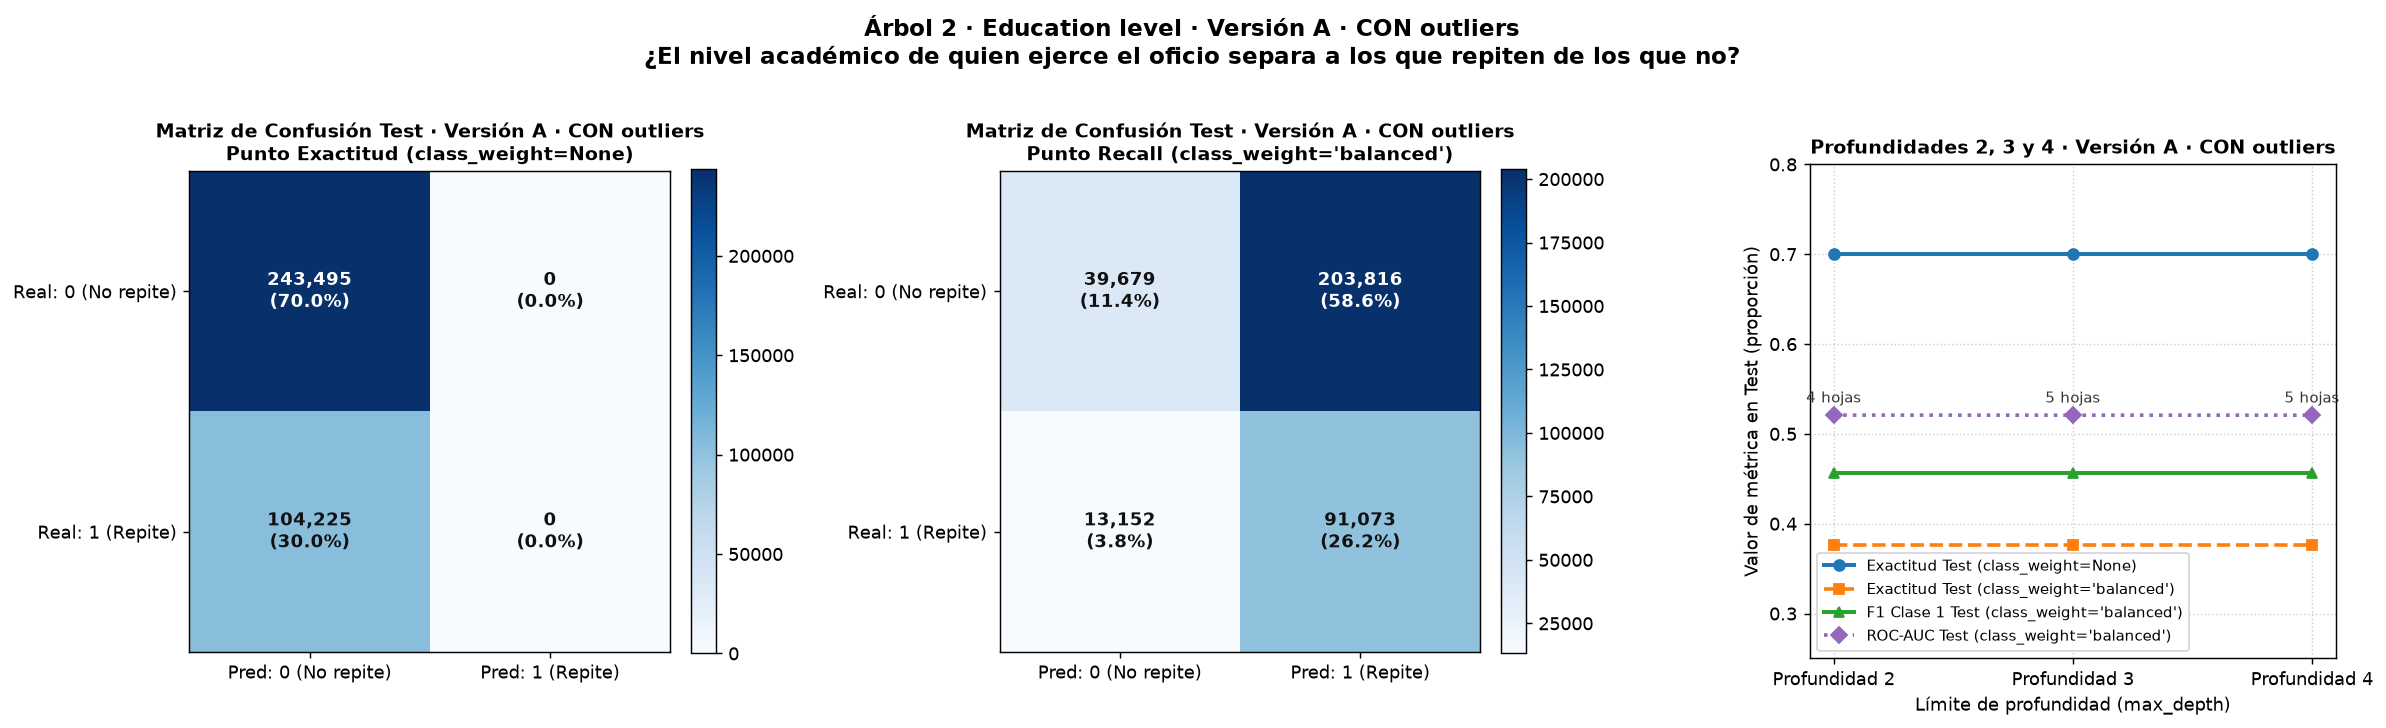

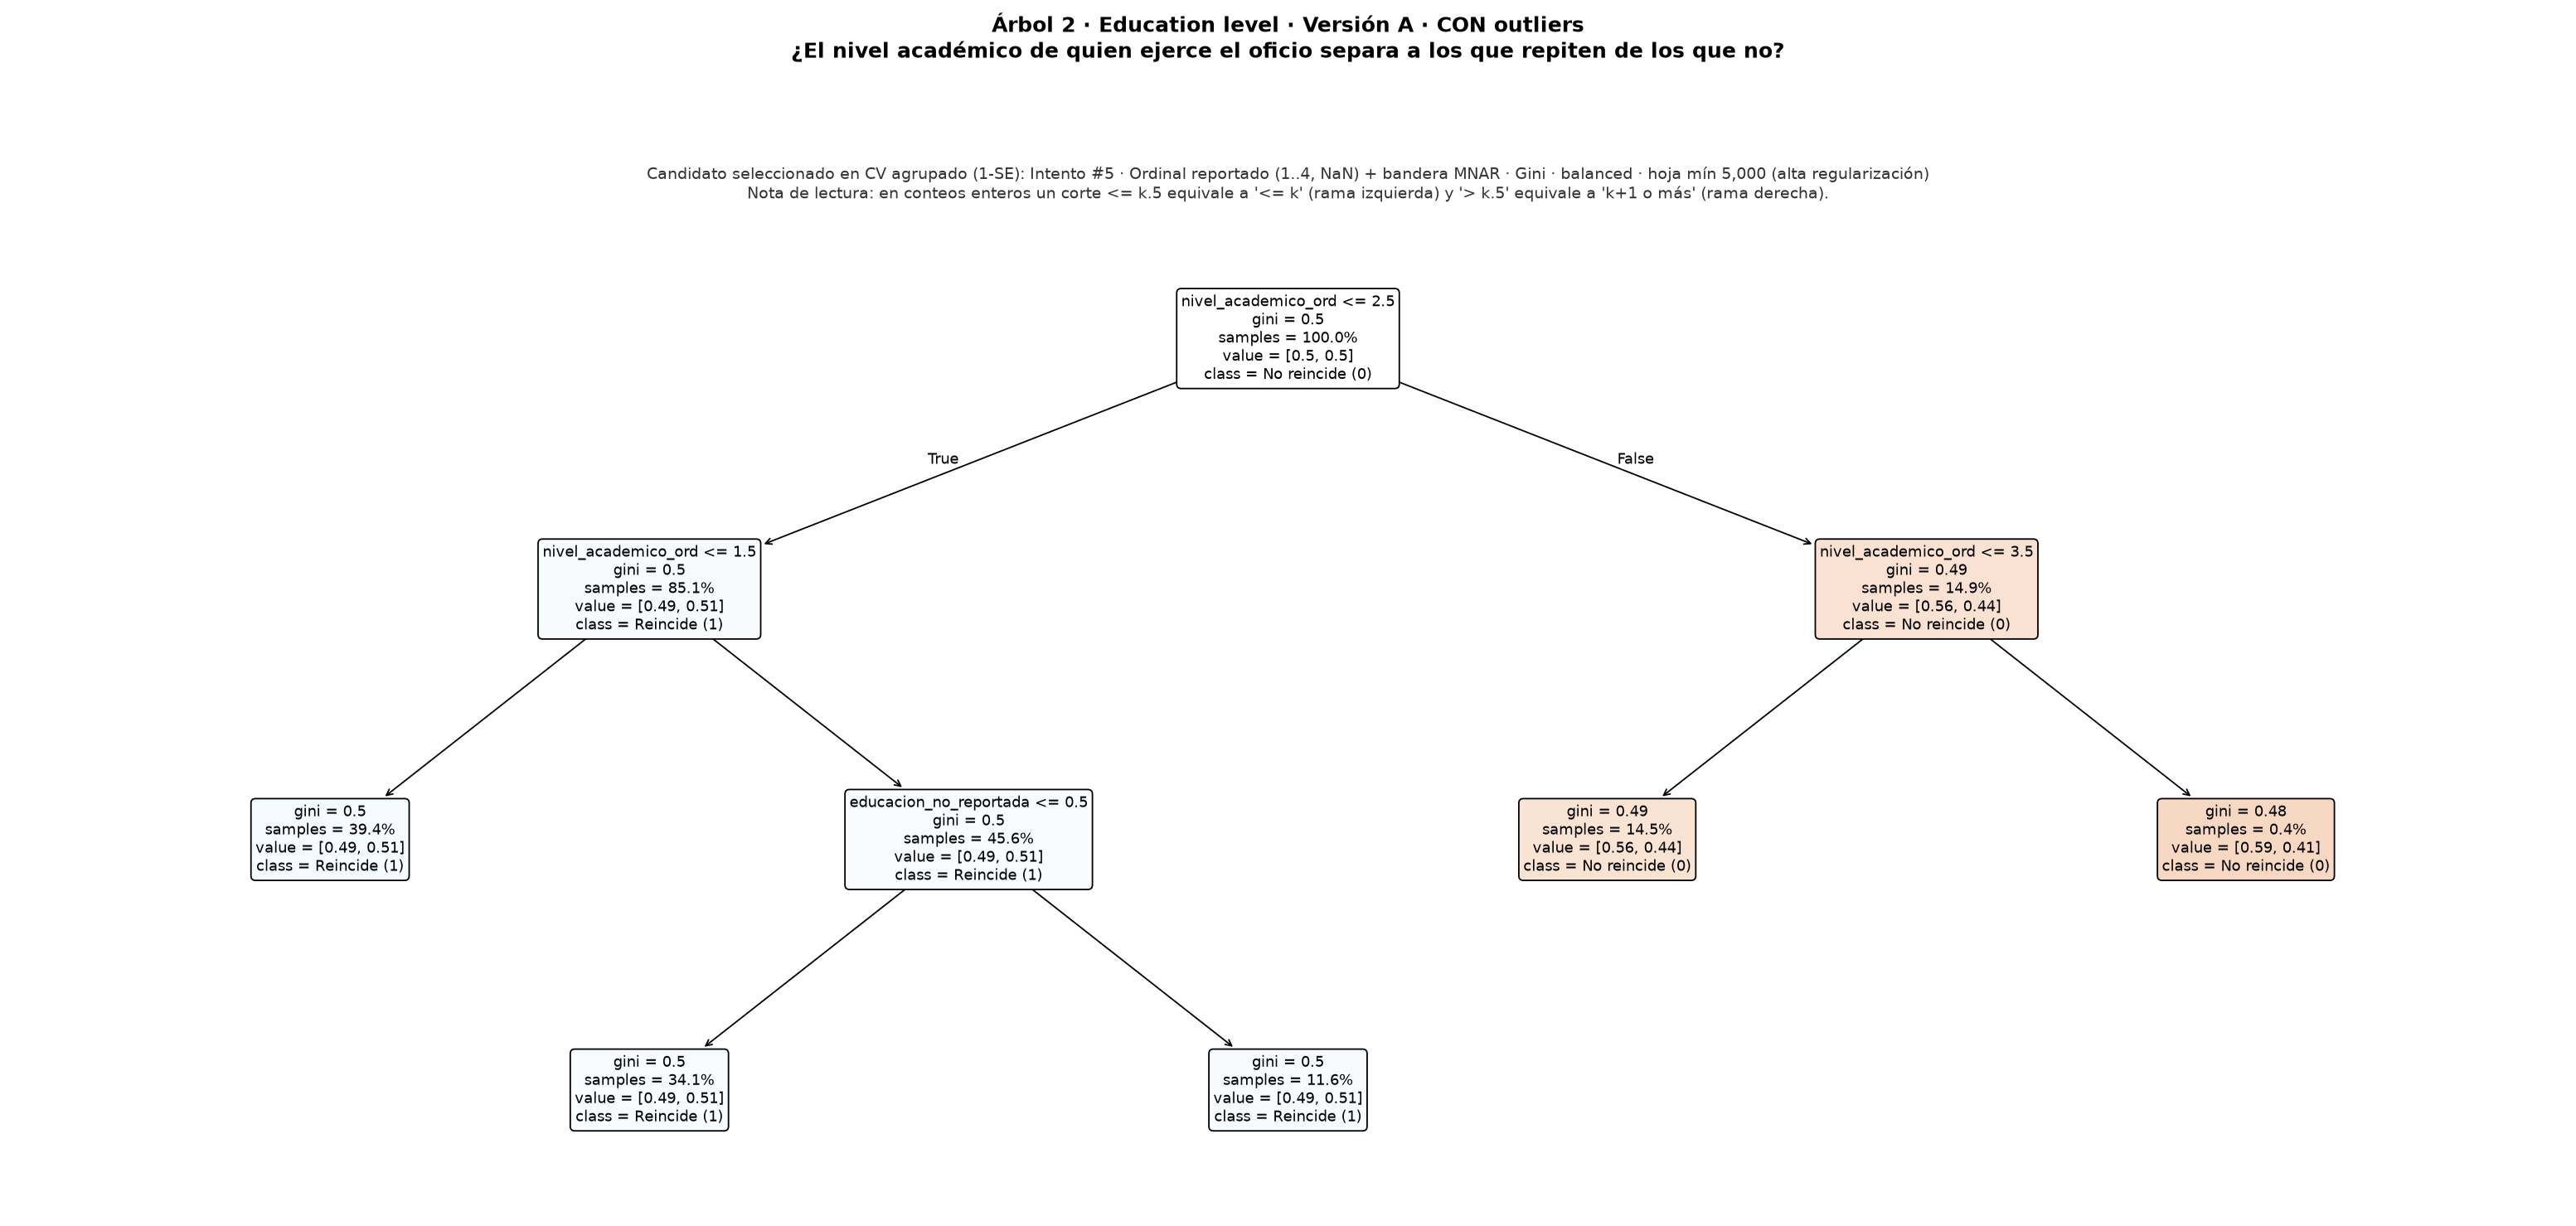

#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión A · CON outliers`

|--- nivel_academico_ord <= 2.50
|   |--- nivel_academico_ord <= 1.50
|   |   |--- weights: [270111.65, 284212.22] class: 1
|   |--- nivel_academico_ord >  1.50
|   |   |--- educacion_no_reportada <= 0.50
|   |   |   |--- weights: [234431.30, 242727.01] class: 1
|   |   |--- educacion_no_reportada >  0.50
|   |   |   |--- weights: [79423.51, 82450.61] class: 1
|--- nivel_academico_ord >  2.50
|   |--- nivel_academico_ord <= 3.50
|   |   |--- weights: [108249.12, 83846.73] class: 0
|   |--- nivel_academico_ord >  3.50
|   |   |--- weights: [3293.42, 2272.43] class: 0



#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión A · CON outliers`

version_datos,particion,nivel_arbol,nodo_id,variable,umbral_sklearn,pregunta_es,n_en_nodo,n_izquierda,pct_izquierda,tasa_clase1_izquierda,lift_izquierda,n_derecha,pct_derecha,tasa_clase1_derecha,lift_derecha
Versión A · CON outliers,Train (80%),Nivel 1 · Raíz (Nodo 0),0,nivel_academico_ord,2.5,¿nivel_academico_ord <= 2.50? [Izq: nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] | Der: nivel_academico_ord > 2.5 (desde Master (3) o superior)],1391018,1183193,85.06,0.3091,1.030,207825,14.94,0.2487,0.829
Versión A · CON outliers,Train (80%),Nivel 2 · Rama Izquierda (Nodo 1),1,nivel_academico_ord,1.5,¿nivel_academico_ord <= 1.50? [Izq: nivel_academico_ord <= 1.5 (hasta Secondary school (1)) | Der: nivel_academico_ord > 1.5 (desde Bachelor (2) o superior) [incluye NaN / No reportado]],1183193,548687,46.37,0.3109,1.036,634506,53.63,0.3076,1.025
Versión A · CON outliers,Train (80%),Nivel 2 · Rama Derecha (Nodo 6),6,nivel_academico_ord,3.5,¿nivel_academico_ord <= 3.50? [Izq: nivel_academico_ord <= 3.5 (hasta Master (3)) [incluye NaN / No reportado] | Der: nivel_academico_ord > 3.5 (desde PhD (4) o superior)],207825,201851,97.13,0.2493,0.831,5974,2.87,0.2283,0.761
Versión A · CON outliers,Test (20%),Nivel 1 · Raíz (Nodo 0),0,nivel_academico_ord,2.5,¿nivel_academico_ord <= 2.50? [Izq: nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] | Der: nivel_academico_ord > 2.5 (desde Master (3) o superior)],347720,294889,84.81,0.3088,1.030,52831,15.19,0.2489,0.831
Versión A · CON outliers,Test (20%),Nivel 2 · Rama Izquierda (Nodo 1),1,nivel_academico_ord,1.5,¿nivel_academico_ord <= 1.50? [Izq: nivel_academico_ord <= 1.5 (hasta Secondary school (1)) | Der: nivel_academico_ord > 1.5 (desde Bachelor (2) o superior) [incluye NaN / No reportado]],294889,136581,46.32,0.3120,1.041,158308,53.68,0.3061,1.021
Versión A · CON outliers,Test (20%),Nivel 2 · Rama Derecha (Nodo 6),6,nivel_academico_ord,3.5,¿nivel_academico_ord <= 3.50? [Izq: nivel_academico_ord <= 3.5 (hasta Master (3)) [incluye NaN / No reportado] | Der: nivel_academico_ord > 3.5 (desde PhD (4) o superior)],52831,51275,97.05,0.2499,0.834,1556,2.95,0.2166,0.723


#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión A · CON outliers`

version_datos,variable,importancia,importancia_pct,descripcion_variable,lectura_metodologica
Versión A · CON outliers,nivel_academico_ord,0.9999,99.99,"Nivel educativo ordinal solo para reportados (1=Secondary school, 2=Bachelor, 3=Master, 4=PhD; 'No reportado' queda como NaN sin rellenar con 0)",Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,educacion_no_reportada,0.0001,0.01,Bandera binaria separada (0/1) de ausencia informativa (MNAR: 1 si 'No reportado'),Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)


#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión A · CON outliers`

version_datos,punto_operacion,hoja_id,profundidad,predice_reincide,n_train,pct_train,tasa_clase1_train,wilson_ic95_train,tasa_base_train,lift_train,n_test,pct_test,tasa_clase1_test,wilson_ic95_test,wilson_ic95_test_inf,wilson_ic95_test_sup,tasa_base_test,lift_test,soporte_suficiente_train,soporte_suficiente_test,condiciones_hoja_es
Versión A · CON outliers,class_weight='balanced',2,2,1,548687,39.44,0.3109,"[0.3097, 0.3121]",0.3001,1.036,136581,39.28,0.3120,"[0.3095, 0.3145]",0.3095,0.3145,0.2997,1.041,Sí,Sí,nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] Y nivel_academico_ord <= 1.5 (hasta Secondary school (1))
Versión A · CON outliers,class_weight='balanced',5,3,1,160664,11.55,0.3080,"[0.3058, 0.3103]",0.3001,1.026,40270,11.58,0.3054,"[0.3009, 0.3099]",0.3009,0.3099,0.2997,1.019,Sí,Sí,nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] Y nivel_academico_ord > 1.5 (desde Bachelor (2) o superior) [incluye NaN / No reportado] Y educación NO reportada = Sí (1)
Versión A · CON outliers,class_weight='balanced',4,3,1,473842,34.06,0.3075,"[0.3062, 0.3088]",0.3001,1.025,118038,33.95,0.3064,"[0.3038, 0.3090]",0.3038,0.3090,0.2997,1.022,Sí,Sí,nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] Y nivel_academico_ord > 1.5 (desde Bachelor (2) o superior) [incluye NaN / No reportado] Y educación NO reportada = No (0)
Versión A · CON outliers,class_weight='balanced',7,2,0,201851,14.51,0.2493,"[0.2474, 0.2512]",0.3001,0.831,51275,14.75,0.2499,"[0.2462, 0.2537]",0.2462,0.2537,0.2997,0.834,Sí,Sí,nivel_academico_ord > 2.5 (desde Master (3) o superior) Y nivel_academico_ord <= 3.5 (hasta Master (3)) [incluye NaN / No reportado]
Versión A · CON outliers,class_weight='balanced',8,2,0,5974,0.43,0.2283,"[0.2179, 0.2391]",0.3001,0.761,1556,0.45,0.2166,"[0.1968, 0.2377]",0.1968,0.2377,0.2997,0.723,No (<0.5%),No (<0.5%),nivel_academico_ord > 2.5 (desde Master (3) o superior) Y nivel_academico_ord > 3.5 (desde PhD (4) o superior)


#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión A · CON outliers`

version_datos,regla_num,hoja_id,predice_reincide,n_registros_train,tasa_clase1_train_pct,lift_train,n_registros_test,tasa_clase1_test_pct,wilson_ic95_test,lift_test,regla_negocio_espanol,advertencia_lo_que_no_dice
Versión A · CON outliers,1,2,1,548687,31.09,1.036,136581,31.20,"[0.3095, 0.3145]",1.041,"Regla 1 (Árbol 2 · Education level · Versión A · CON outliers, Hoja 2): SI el registro de empleo cumple que [nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] Y nivel_academico_ord <= 1.5 (hasta Secondary school (1))], ENTONCES el árbol ubica el perfil del oficio con mayor propensión a repetición (predice reincide = 1 en punto balanceado). En Train agrupa 548,687 registros (39.44% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 31.09% frente a la tasa base de 30.01% (Lift = 1.036x). En Test comprende 136,581 registros (39.28%) con tasa de 31.20% (IC95% Wilson = [0.3095, 0.3145]) frente a 29.97% base (Lift = 1.041x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."
Versión A · CON outliers,2,5,1,160664,30.80,1.026,40270,30.54,"[0.3009, 0.3099]",1.019,"Regla 2 (Árbol 2 · Education level · Versión A · CON outliers, Hoja 5): SI el registro de empleo cumple que [nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] Y nivel_academico_ord > 1.5 (desde Bachelor (2) o superior) [incluye NaN / No reportado] Y educación NO reportada = Sí (1)], ENTONCES el árbol ubica el perfil del oficio con mayor propensión a repetición (predice reincide = 1 en punto balanceado). En Train agrupa 160,664 registros (11.55% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 30.80% frente a la tasa base de 30.01% (Lift = 1.026x). En Test comprende 40,270 registros (11.58%) con tasa de 30.54% (IC95% Wilson = [0.3009, 0.3099]) frente a 29.97% base (Lift = 1.019x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."
Versión A · CON outliers,3,7,0,201851,24.93,0.831,51275,24.99,"[0.2462, 0.2537]",0.834,"Regla 3 (Árbol 2 · Education level · Versión A · CON outliers, Hoja 7): SI el registro de empleo cumple que [nivel_academico_ord > 2.5 (desde Master (3) o superior) Y nivel_academico_ord <= 3.5 (hasta Master (3)) [incluye NaN / No reportado]], ENTONCES el árbol ubica el perfil del oficio con menor propensión a repetición / ejercicio único (predice reincide = 0). En Train agrupa 201,851 registros (14.51% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 24.93% frente a la tasa base de 30.01% (Lift = 0.831x). En Test comprende 51,275 registros (14.75%) con tasa de 24.99% (IC95% Wilson = [0.2462, 0.2537]) frente a 29.97% base (Lift = 0.834x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."


In [7]:
# Section 5.1: Árbol 2 · Nivel académico on Version A (CON outliers)
bundle_a_curr = bundles_a["tree_2_education"]
cm_none_a = bundle_a_curr.confusion_matrices_by_point["Punto 1 · Orientado a Exactitud (class_weight=None)"]["test"]
cm_bal_a = bundle_a_curr.confusion_matrices_by_point["Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced')"]["test"]

display(Markdown(f"#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión A · CON outliers`\n**Pregunta**: *¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?*"))
display(bundle_a_curr.operating_points_df)

display(Markdown(f"#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión A · CON outliers`"))
display(bundle_a_curr.depth_df)

fig_panel_a = plot_depth_and_confusion_panel(
    depth_df=bundle_a_curr.depth_df,
    cm_test_none=cm_none_a,
    cm_test_balanced=cm_bal_a,
    tree_label_es=bundle_a_curr.tree_label_es,
    question_es=bundle_a_curr.question_es,
    version_label_es=bundle_a_curr.version_label_es,
    output_path=CONFIG.figures_dir / "02_arbol_2_educacion_panel_version_a.png",
)
plt.show()
plt.close(fig_panel_a)

fig_tree_a = plot_decision_tree_legible(
    clf=bundle_a_curr.tuning_result.fitted_tree_balanced,
    feature_names=list(bundle_a_curr.tuning_result.X_train.columns),
    tree_label_es=bundle_a_curr.tree_label_es,
    question_es=bundle_a_curr.question_es,
    version_label_es=bundle_a_curr.version_label_es,
    subtitle_es=f"Candidato seleccionado en CV agrupado (1-SE): Intento #{bundle_a_curr.tuning_result.selected_attempt_id} · {bundle_a_curr.tuning_result.selected_spec.description_es}",
    output_path=CONFIG.figures_dir / "02_arbol_2_educacion_tree_depth4_version_a.png",
)
plt.show()
plt.close(fig_tree_a)

display(Markdown(f"#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión A · CON outliers`"))
print(bundle_a_curr.export_text_balanced_str)

display(Markdown(f"#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión A · CON outliers`"))
display(pd.concat([bundle_a_curr.first_questions_train_df, bundle_a_curr.first_questions_test_df], ignore_index=True))

display(Markdown(f"#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión A · CON outliers`"))
display(bundle_a_curr.importances_df.head(10))

display(Markdown(f"#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión A · CON outliers`"))
display(bundle_a_curr.leaf_lift_balanced_df)

display(Markdown(f"#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión A · CON outliers`"))
display(bundle_a_curr.business_rules_df[["version_datos", "regla_num", "hoja_id", "predice_reincide", "n_registros_train", "tasa_clase1_train_pct", "lift_train", "n_registros_test", "tasa_clase1_test_pct", "wilson_ic95_test", "lift_test", "regla_negocio_espanol", "advertencia_lo_que_no_dice"]])

### 5.2 Sección `Versión B · SIN outliers` — ¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?
A continuación replicamos exactamente el mismo análisis, partición por persona, variables e hiperparámetros sobre **`Versión B · SIN outliers`** (datos winsorizados por IQR), manteniendo todas las etiquetas de versión explícitas en tablas y gráficos.

#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión B · SIN outliers`
**Pregunta**: *¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?*

version_datos,arbol,pregunta_objetivo,punto_operacion,regla_decision,profundidad_efectiva,n_hojas,train_accuracy,test_accuracy,test_accuracy_ic95_persona,gap_acc_train_test,train_precision_1,test_precision_1,train_recall_1,test_recall_1,test_recall_1_ic95_persona,train_f1_1,test_f1_1,test_f1_1_ic95_persona,f1_ref_trivial_todo_1,delta_f1_vs_trivial_todo_1,train_roc_auc,test_roc_auc,test_roc_auc_ic95_persona,roc_auc_ic95_inf,roc_auc_ic95_sup,roc_auc_techo_6_0,pct_del_techo_auc_6_0,hoja_elegida_en_train_id,lift_train_hoja_elegida,max_lift_hoja_soporte_05pct,max_lift_test_referencia_optimista,hoja_con_lift_ge_150_y_soporte_05pct,criterio_separa_clases,supera_baseline_exactitud_7003,brecha_vs_meta_085_f1,tn_test,fp_test,fn_test,tp_test
Versión B · SIN outliers,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Punto 1 · Orientado a Exactitud (class_weight=None),Umbral estándar 0.50 sobre tasa empírica de hoja,3,5,0.6999,0.7003,"[0.6981, 0.7025]",-0.0004,0.0000,0.0000,0.0000,0.0000,"[0.0000, 0.0000]",0.000,0.0000,"[0.0000, 0.0000]",0.4612,-0.4612,0.5198,0.5208,"[0.5181, 0.5239]",0.5181,0.5239,0.7132,9.78,2,1.036,1.041,1.041,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),Empata el baseline porque no predice ningún positivo,0.8500,243495,0,104225,0
Versión B · SIN outliers,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),Pesos balanceados inversamente proporcionales a 70/30,3,5,0.3752,0.3760,"[0.3734, 0.3787]",-0.0008,0.3091,0.3088,0.8762,0.8738,"[0.8694, 0.8781]",0.457,0.4564,"[0.4535, 0.4597]",0.4612,-0.0049,0.5198,0.5208,"[0.5181, 0.5239]",0.5181,0.5239,0.7132,9.78,2,1.036,1.041,1.041,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),No (prioriza Recall sobre exactitud global),0.3936,39679,203816,13152,91073
Versión B · SIN outliers,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Punto 3 · Umbral OOF óptimo en Train (tau*=0.315),Predice 1 si P(reincide=1|hoja) >= 0.315 (sujeto a Acc >= Baseline en OOF Train),3,5,0.6999,0.7003,"[0.6981, 0.7025]",-0.0004,0.0000,0.0000,0.0000,0.0000,"[0.0000, 0.0000]",0.000,0.0000,"[0.0000, 0.0000]",0.4612,-0.4612,0.5198,0.5208,"[0.5181, 0.5239]",0.5181,0.5239,0.7132,9.78,2,1.036,1.041,1.041,No,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),Empata el baseline porque no predice ningún positivo,0.8500,243495,0,104225,0


#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión B · SIN outliers`

version_datos,arbol,punto_operacion,max_depth,profundidad_alcanzada,n_leaves,train_acc,test_acc,gap_train_test,train_f1_clase_1,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,test_roc_auc
Versión B · SIN outliers,Árbol 2 · Education level,class_weight=None (Exactitud),2,2,4,0.6999,0.7003,-0.0004,0.000,0.0000,0.0000,0.0000,0.5209
Versión B · SIN outliers,Árbol 2 · Education level,class_weight=None (Exactitud),3,3,5,0.6999,0.7003,-0.0004,0.000,0.0000,0.0000,0.0000,0.5208
Versión B · SIN outliers,Árbol 2 · Education level,class_weight=None (Exactitud),4,3,5,0.6999,0.7003,-0.0004,0.000,0.0000,0.0000,0.0000,0.5208
Versión B · SIN outliers,Árbol 2 · Education level,class_weight='balanced' (Recall),2,2,4,0.3752,0.3760,-0.0008,0.457,0.3088,0.8738,0.4564,0.5209
Versión B · SIN outliers,Árbol 2 · Education level,class_weight='balanced' (Recall),3,3,5,0.3752,0.3760,-0.0008,0.457,0.3088,0.8738,0.4564,0.5208
Versión B · SIN outliers,Árbol 2 · Education level,class_weight='balanced' (Recall),4,3,5,0.3752,0.3760,-0.0008,0.457,0.3088,0.8738,0.4564,0.5208


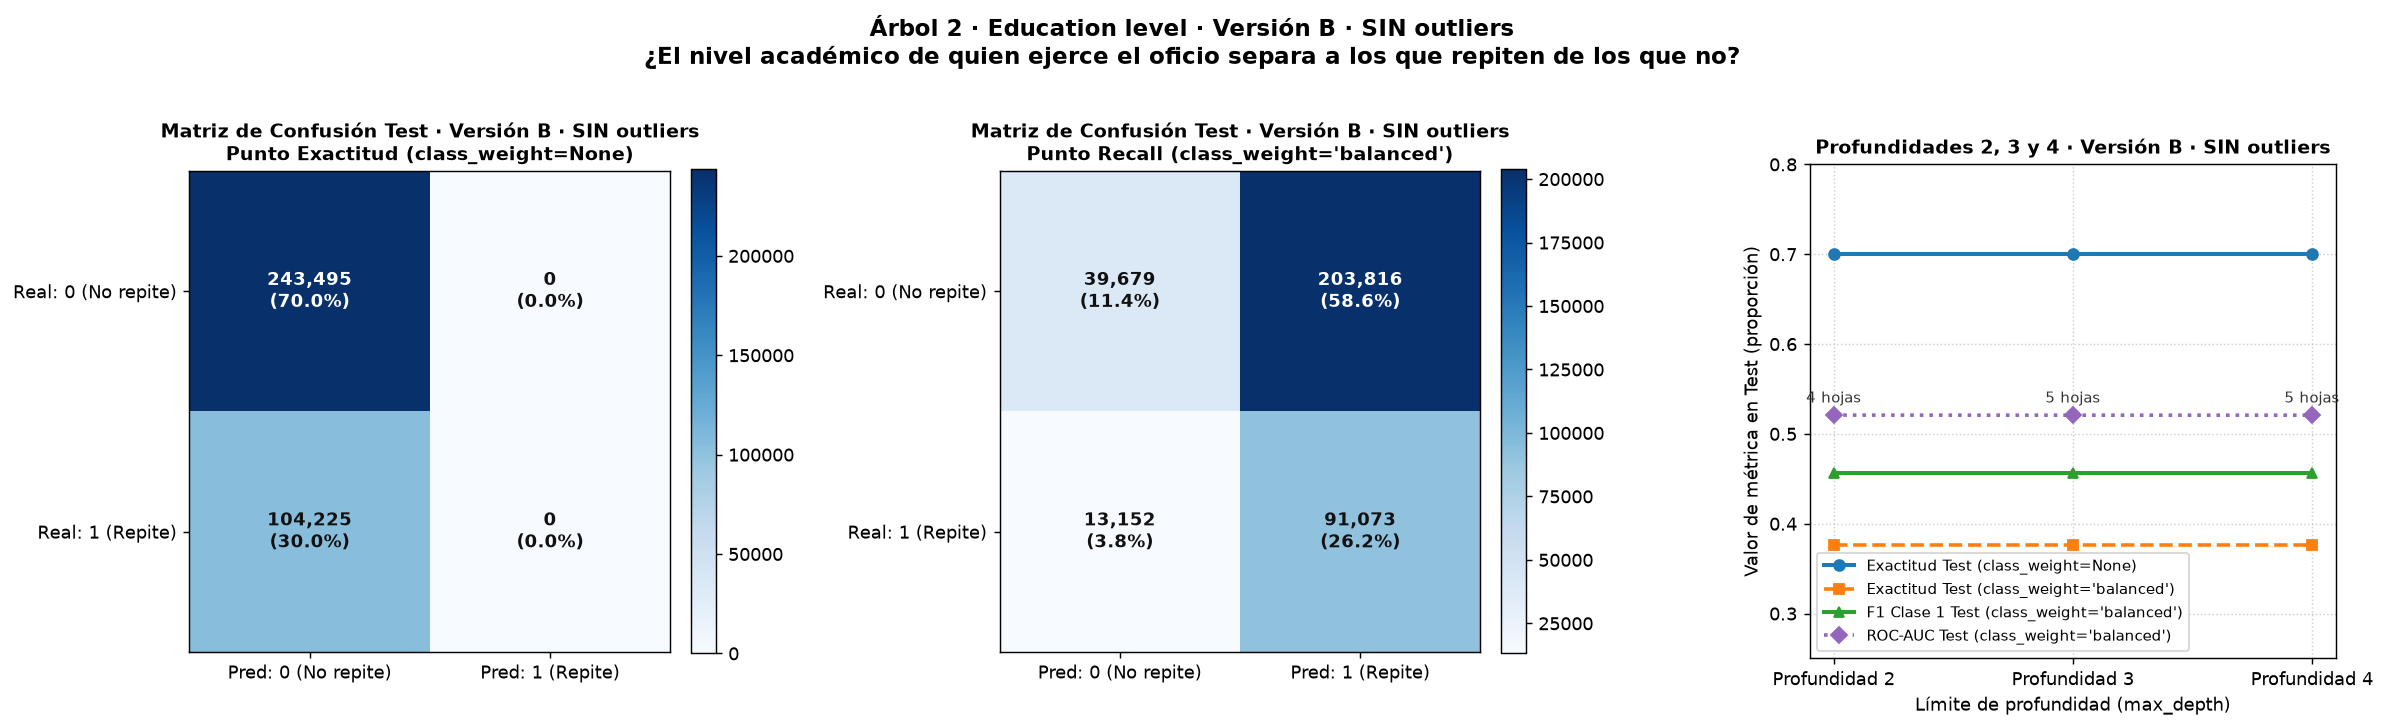

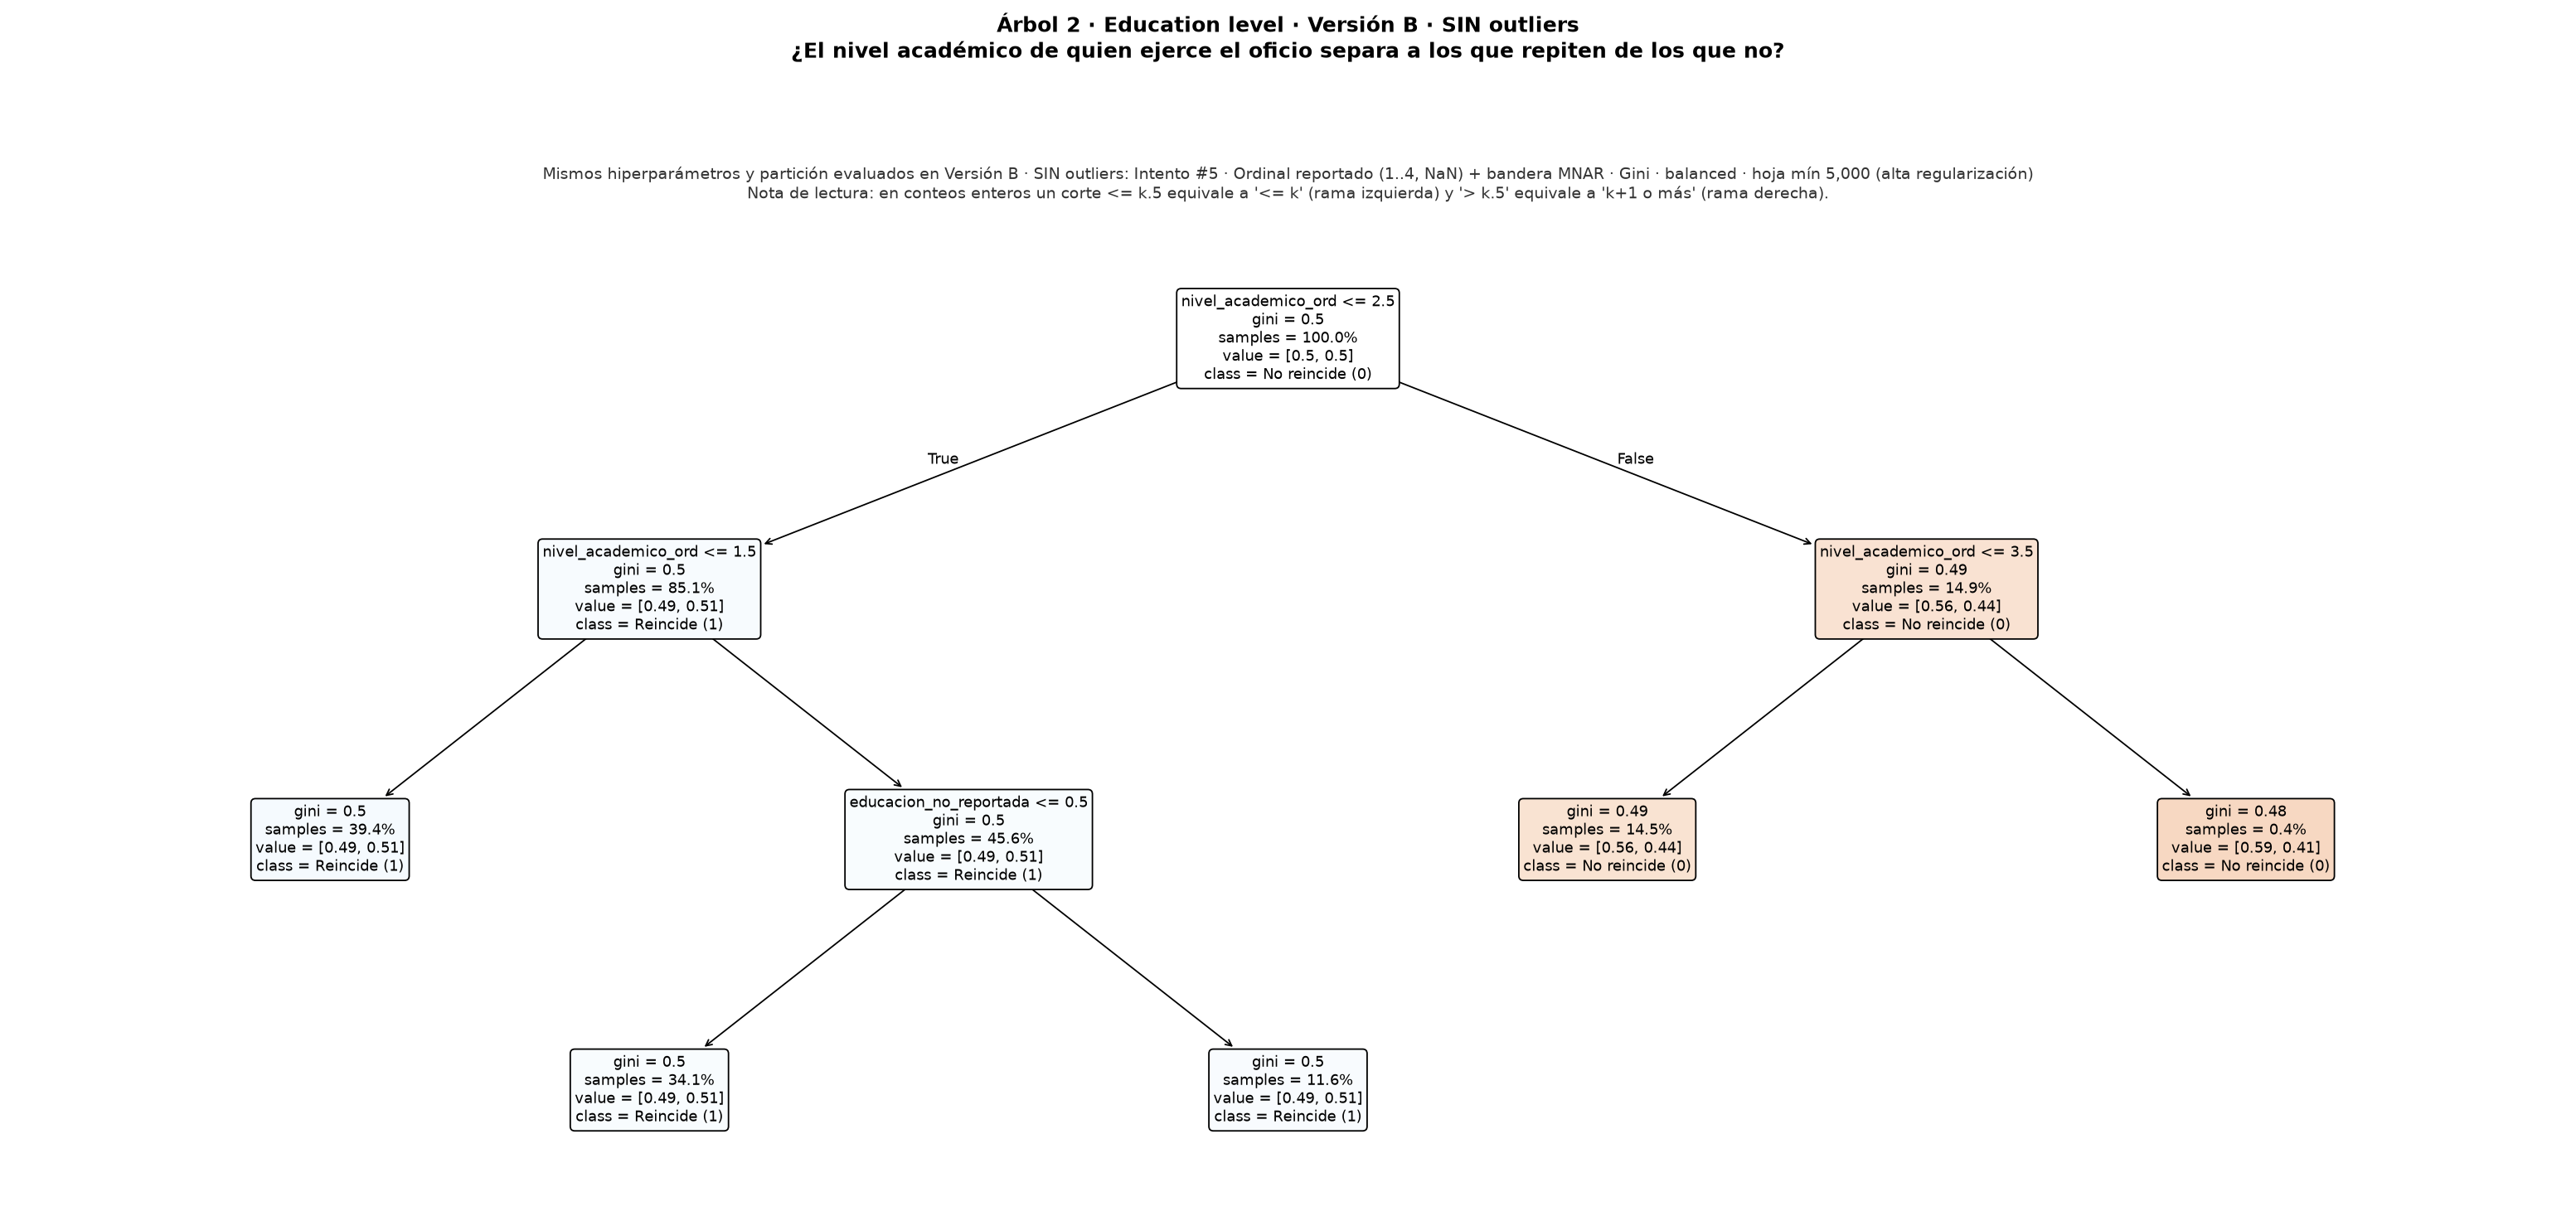

#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión B · SIN outliers`

|--- nivel_academico_ord <= 2.50
|   |--- nivel_academico_ord <= 1.50
|   |   |--- weights: [270111.65, 284212.22] class: 1
|   |--- nivel_academico_ord >  1.50
|   |   |--- educacion_no_reportada <= 0.50
|   |   |   |--- weights: [234431.30, 242727.01] class: 1
|   |   |--- educacion_no_reportada >  0.50
|   |   |   |--- weights: [79423.51, 82450.61] class: 1
|--- nivel_academico_ord >  2.50
|   |--- nivel_academico_ord <= 3.50
|   |   |--- weights: [108249.12, 83846.73] class: 0
|   |--- nivel_academico_ord >  3.50
|   |   |--- weights: [3293.42, 2272.43] class: 0



#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión B · SIN outliers`

version_datos,particion,nivel_arbol,nodo_id,variable,umbral_sklearn,pregunta_es,n_en_nodo,n_izquierda,pct_izquierda,tasa_clase1_izquierda,lift_izquierda,n_derecha,pct_derecha,tasa_clase1_derecha,lift_derecha
Versión B · SIN outliers,Train (80%),Nivel 1 · Raíz (Nodo 0),0,nivel_academico_ord,2.5,¿nivel_academico_ord <= 2.50? [Izq: nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] | Der: nivel_academico_ord > 2.5 (desde Master (3) o superior)],1391018,1183193,85.06,0.3091,1.030,207825,14.94,0.2487,0.829
Versión B · SIN outliers,Train (80%),Nivel 2 · Rama Izquierda (Nodo 1),1,nivel_academico_ord,1.5,¿nivel_academico_ord <= 1.50? [Izq: nivel_academico_ord <= 1.5 (hasta Secondary school (1)) | Der: nivel_academico_ord > 1.5 (desde Bachelor (2) o superior) [incluye NaN / No reportado]],1183193,548687,46.37,0.3109,1.036,634506,53.63,0.3076,1.025
Versión B · SIN outliers,Train (80%),Nivel 2 · Rama Derecha (Nodo 6),6,nivel_academico_ord,3.5,¿nivel_academico_ord <= 3.50? [Izq: nivel_academico_ord <= 3.5 (hasta Master (3)) [incluye NaN / No reportado] | Der: nivel_academico_ord > 3.5 (desde PhD (4) o superior)],207825,201851,97.13,0.2493,0.831,5974,2.87,0.2283,0.761
Versión B · SIN outliers,Test (20%),Nivel 1 · Raíz (Nodo 0),0,nivel_academico_ord,2.5,¿nivel_academico_ord <= 2.50? [Izq: nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] | Der: nivel_academico_ord > 2.5 (desde Master (3) o superior)],347720,294889,84.81,0.3088,1.030,52831,15.19,0.2489,0.831
Versión B · SIN outliers,Test (20%),Nivel 2 · Rama Izquierda (Nodo 1),1,nivel_academico_ord,1.5,¿nivel_academico_ord <= 1.50? [Izq: nivel_academico_ord <= 1.5 (hasta Secondary school (1)) | Der: nivel_academico_ord > 1.5 (desde Bachelor (2) o superior) [incluye NaN / No reportado]],294889,136581,46.32,0.3120,1.041,158308,53.68,0.3061,1.021
Versión B · SIN outliers,Test (20%),Nivel 2 · Rama Derecha (Nodo 6),6,nivel_academico_ord,3.5,¿nivel_academico_ord <= 3.50? [Izq: nivel_academico_ord <= 3.5 (hasta Master (3)) [incluye NaN / No reportado] | Der: nivel_academico_ord > 3.5 (desde PhD (4) o superior)],52831,51275,97.05,0.2499,0.834,1556,2.95,0.2166,0.723


#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión B · SIN outliers`

version_datos,variable,importancia,importancia_pct,descripcion_variable,lectura_metodologica
Versión B · SIN outliers,nivel_academico_ord,0.9999,99.99,"Nivel educativo ordinal solo para reportados (1=Secondary school, 2=Bachelor, 3=Master, 4=PhD; 'No reportado' queda como NaN sin rellenar con 0)",Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,educacion_no_reportada,0.0001,0.01,Bandera binaria separada (0/1) de ausencia informativa (MNAR: 1 si 'No reportado'),Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)


#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión B · SIN outliers`

version_datos,punto_operacion,hoja_id,profundidad,predice_reincide,n_train,pct_train,tasa_clase1_train,wilson_ic95_train,tasa_base_train,lift_train,n_test,pct_test,tasa_clase1_test,wilson_ic95_test,wilson_ic95_test_inf,wilson_ic95_test_sup,tasa_base_test,lift_test,soporte_suficiente_train,soporte_suficiente_test,condiciones_hoja_es
Versión B · SIN outliers,class_weight='balanced',2,2,1,548687,39.44,0.3109,"[0.3097, 0.3121]",0.3001,1.036,136581,39.28,0.3120,"[0.3095, 0.3145]",0.3095,0.3145,0.2997,1.041,Sí,Sí,nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] Y nivel_academico_ord <= 1.5 (hasta Secondary school (1))
Versión B · SIN outliers,class_weight='balanced',5,3,1,160664,11.55,0.3080,"[0.3058, 0.3103]",0.3001,1.026,40270,11.58,0.3054,"[0.3009, 0.3099]",0.3009,0.3099,0.2997,1.019,Sí,Sí,nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] Y nivel_academico_ord > 1.5 (desde Bachelor (2) o superior) [incluye NaN / No reportado] Y educación NO reportada = Sí (1)
Versión B · SIN outliers,class_weight='balanced',4,3,1,473842,34.06,0.3075,"[0.3062, 0.3088]",0.3001,1.025,118038,33.95,0.3064,"[0.3038, 0.3090]",0.3038,0.3090,0.2997,1.022,Sí,Sí,nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] Y nivel_academico_ord > 1.5 (desde Bachelor (2) o superior) [incluye NaN / No reportado] Y educación NO reportada = No (0)
Versión B · SIN outliers,class_weight='balanced',7,2,0,201851,14.51,0.2493,"[0.2474, 0.2512]",0.3001,0.831,51275,14.75,0.2499,"[0.2462, 0.2537]",0.2462,0.2537,0.2997,0.834,Sí,Sí,nivel_academico_ord > 2.5 (desde Master (3) o superior) Y nivel_academico_ord <= 3.5 (hasta Master (3)) [incluye NaN / No reportado]
Versión B · SIN outliers,class_weight='balanced',8,2,0,5974,0.43,0.2283,"[0.2179, 0.2391]",0.3001,0.761,1556,0.45,0.2166,"[0.1968, 0.2377]",0.1968,0.2377,0.2997,0.723,No (<0.5%),No (<0.5%),nivel_academico_ord > 2.5 (desde Master (3) o superior) Y nivel_academico_ord > 3.5 (desde PhD (4) o superior)


#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión B · SIN outliers`

version_datos,regla_num,hoja_id,predice_reincide,n_registros_train,tasa_clase1_train_pct,lift_train,n_registros_test,tasa_clase1_test_pct,wilson_ic95_test,lift_test,regla_negocio_espanol,advertencia_lo_que_no_dice
Versión B · SIN outliers,1,2,1,548687,31.09,1.036,136581,31.20,"[0.3095, 0.3145]",1.041,"Regla 1 (Árbol 2 · Education level · Versión B · SIN outliers, Hoja 2): SI el registro de empleo cumple que [nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] Y nivel_academico_ord <= 1.5 (hasta Secondary school (1))], ENTONCES el árbol ubica el perfil del oficio con mayor propensión a repetición (predice reincide = 1 en punto balanceado). En Train agrupa 548,687 registros (39.44% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 31.09% frente a la tasa base de 30.01% (Lift = 1.036x). En Test comprende 136,581 registros (39.28%) con tasa de 31.20% (IC95% Wilson = [0.3095, 0.3145]) frente a 29.97% base (Lift = 1.041x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."
Versión B · SIN outliers,2,5,1,160664,30.80,1.026,40270,30.54,"[0.3009, 0.3099]",1.019,"Regla 2 (Árbol 2 · Education level · Versión B · SIN outliers, Hoja 5): SI el registro de empleo cumple que [nivel_academico_ord <= 2.5 (hasta Bachelor (2)) [incluye NaN / No reportado] Y nivel_academico_ord > 1.5 (desde Bachelor (2) o superior) [incluye NaN / No reportado] Y educación NO reportada = Sí (1)], ENTONCES el árbol ubica el perfil del oficio con mayor propensión a repetición (predice reincide = 1 en punto balanceado). En Train agrupa 160,664 registros (11.55% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 30.80% frente a la tasa base de 30.01% (Lift = 1.026x). En Test comprende 40,270 registros (11.58%) con tasa de 30.54% (IC95% Wilson = [0.3009, 0.3099]) frente a 29.97% base (Lift = 1.019x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."
Versión B · SIN outliers,3,7,0,201851,24.93,0.831,51275,24.99,"[0.2462, 0.2537]",0.834,"Regla 3 (Árbol 2 · Education level · Versión B · SIN outliers, Hoja 7): SI el registro de empleo cumple que [nivel_academico_ord > 2.5 (desde Master (3) o superior) Y nivel_academico_ord <= 3.5 (hasta Master (3)) [incluye NaN / No reportado]], ENTONCES el árbol ubica el perfil del oficio con menor propensión a repetición / ejercicio único (predice reincide = 0). En Train agrupa 201,851 registros (14.51% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 24.93% frente a la tasa base de 30.01% (Lift = 0.831x). En Test comprende 51,275 registros (14.75%) con tasa de 24.99% (IC95% Wilson = [0.2462, 0.2537]) frente a 29.97% base (Lift = 0.834x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."


In [8]:
# Section 5.2: Árbol 2 · Nivel académico on Version B (SIN outliers)
bundle_b_curr = bundles_b["tree_2_education"]
cm_none_b = bundle_b_curr.confusion_matrices_by_point["Punto 1 · Orientado a Exactitud (class_weight=None)"]["test"]
cm_bal_b = bundle_b_curr.confusion_matrices_by_point["Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced')"]["test"]

display(Markdown(f"#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión B · SIN outliers`\n**Pregunta**: *¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?*"))
display(bundle_b_curr.operating_points_df)

display(Markdown(f"#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión B · SIN outliers`"))
display(bundle_b_curr.depth_df)

fig_panel_b = plot_depth_and_confusion_panel(
    depth_df=bundle_b_curr.depth_df,
    cm_test_none=cm_none_b,
    cm_test_balanced=cm_bal_b,
    tree_label_es=bundle_b_curr.tree_label_es,
    question_es=bundle_b_curr.question_es,
    version_label_es=bundle_b_curr.version_label_es,
    output_path=CONFIG.figures_dir / "02_arbol_2_educacion_panel_version_b.png",
)
plt.show()
plt.close(fig_panel_b)

fig_tree_b = plot_decision_tree_legible(
    clf=bundle_b_curr.tuning_result.fitted_tree_balanced,
    feature_names=list(bundle_b_curr.tuning_result.X_train.columns),
    tree_label_es=bundle_b_curr.tree_label_es,
    question_es=bundle_b_curr.question_es,
    version_label_es=bundle_b_curr.version_label_es,
    subtitle_es=f"Mismos hiperparámetros y partición evaluados en Versión B · SIN outliers: Intento #{bundle_b_curr.tuning_result.selected_attempt_id} · {bundle_b_curr.tuning_result.selected_spec.description_es}",
    output_path=CONFIG.figures_dir / "02_arbol_2_educacion_tree_depth4_version_b.png",
)
plt.show()
plt.close(fig_tree_b)

display(Markdown(f"#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión B · SIN outliers`"))
print(bundle_b_curr.export_text_balanced_str)

display(Markdown(f"#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión B · SIN outliers`"))
display(pd.concat([bundle_b_curr.first_questions_train_df, bundle_b_curr.first_questions_test_df], ignore_index=True))

display(Markdown(f"#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión B · SIN outliers`"))
display(bundle_b_curr.importances_df.head(10))

display(Markdown(f"#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión B · SIN outliers`"))
display(bundle_b_curr.leaf_lift_balanced_df)

display(Markdown(f"#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión B · SIN outliers`"))
display(bundle_b_curr.business_rules_df[["version_datos", "regla_num", "hoja_id", "predice_reincide", "n_registros_train", "tasa_clase1_train_pct", "lift_train", "n_registros_test", "tasa_clase1_test_pct", "wilson_ic95_test", "lift_test", "regla_negocio_espanol", "advertencia_lo_que_no_dice"]])

### 5.3 Tabla Comparativa Lado a Lado y Lectura Dinámica: `Versión A · CON outliers` vs. `Versión B · SIN outliers` (Árbol 2 · Nivel académico)

In [9]:
# Section 5.3: Side-by-side Version A vs Version B comparison for Árbol 2 · Nivel académico (generated dynamically from result objects)
sub_full_curr = sensitivity_result.full_data_ab_table.loc[
    sensitivity_result.full_data_ab_table["bloque_id"] == "tree_2_education"
].reset_index(drop=True)
sub_sum_curr = sensitivity_result.summary_table.loc[
    sensitivity_result.summary_table["bloque_id"] == "tree_2_education"
].reset_index(drop=True)
sub_thr_curr = sensitivity_result.threshold_comparison_table.loc[
    sensitivity_result.threshold_comparison_table["bloque_id"] == "tree_2_education"
].reset_index(drop=True)

display(Markdown("#### A vs. B en el Conjunto Completo (`Train = 1,391,018` / `Test = 347,720`) por Punto de Operación y contraste contra 1 DE entre semillas"))
display(sub_full_curr)

display(Markdown("#### A vs. B en las 5 Semillas de Sensibilidad (`42, 100, 2026, 7, 999` · 3,000 personas Train / 750 Test)"))
display(sub_sum_curr)

display(Markdown("#### Comparación Semilla por Semilla de Umbrales (Raíz y Nivel 2) entre Versión A y Versión B"))
display(sub_thr_curr)

display(Markdown(f"### 5.4 Lectura Comparativa Generada Dinámicamente desde los Objetos de Resultado — ¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?"))
display(
    Markdown(
        build_tree_ab_reading_es(
            block_id="tree_2_education",
            full_ab_sub=sub_full_curr,
            sum_sub=sub_sum_curr,
            bundle_a=bundles_a["tree_2_education"],
            bundle_b=bundles_b["tree_2_education"],
        )
    )
)

#### A vs. B en el Conjunto Completo (`Train = 1,391,018` / `Test = 347,720`) por Punto de Operación y contraste contra 1 DE entre semillas

bloque_id,arbol,pregunta_objetivo,version_datos,punto_operacion,profundidad_efectiva,n_hojas,train_accuracy,test_accuracy,test_precision_1,test_recall_1,test_f1_1,test_roc_auc,umbral_raiz,umbral_nivel2_izq,umbral_nivel2_der,delta_abs_acc_A_vs_B,delta_abs_f1_A_vs_B,std_f1_5_semillas,delta_abs_auc_A_vs_B,std_auc_5_semillas,diferencia_supera_1_std_semillas
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Versión A · CON outliers,Punto Exactitud (class_weight=None),3,5,0.6999,0.7003,0.0000,0.0000,0.0000,0.5208,nivel_academico_ord <= 2.50,nivel_academico_ord <= 1.50,nivel_academico_ord <= 3.50,0.0,0.0,0.0461,0.0,0.0219,No (dentro del ruido de muestreo <= 1 SD)
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Versión B · SIN outliers,Punto Exactitud (class_weight=None),3,5,0.6999,0.7003,0.0000,0.0000,0.0000,0.5208,nivel_academico_ord <= 2.50,nivel_academico_ord <= 1.50,nivel_academico_ord <= 3.50,0.0,0.0,0.0461,0.0,0.0219,No (dentro del ruido de muestreo <= 1 SD)
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Versión A · CON outliers,Punto Recall (class_weight='balanced'),3,5,0.3752,0.3760,0.3088,0.8738,0.4564,0.5208,nivel_academico_ord <= 2.50,nivel_academico_ord <= 1.50,nivel_academico_ord <= 3.50,0.0,0.0,0.0461,0.0,0.0219,No (dentro del ruido de muestreo <= 1 SD)
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Versión B · SIN outliers,Punto Recall (class_weight='balanced'),3,5,0.3752,0.3760,0.3088,0.8738,0.4564,0.5208,nivel_academico_ord <= 2.50,nivel_academico_ord <= 1.50,nivel_academico_ord <= 3.50,0.0,0.0,0.0461,0.0,0.0219,No (dentro del ruido de muestreo <= 1 SD)


#### A vs. B en las 5 Semillas de Sensibilidad (`42, 100, 2026, 7, 999` · 3,000 personas Train / 750 Test)

bloque_id,arbol,pregunta_objetivo,version_datos,n_semillas,cv_train_roc_auc_media,cv_train_roc_auc_std,cv_train_acc_media,cv_train_acc_std,cv_train_prec1_media,cv_train_rec1_media,cv_train_f1_media,cv_train_f1_std,test_roc_auc_media,test_roc_auc_std,test_acc_media,test_acc_std,test_prec1_media,test_rec1_media,test_f1_media,test_f1_std,n_hojas_media,fit_time_ms_media,raiz_modal_5_semillas,nivel2_izq_modal,nivel2_der_modal
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Versión A · CON outliers,5,0.5354,0.0057,0.4779,0.0638,0.3179,0.6523,0.4205,0.0258,0.5247,0.0219,0.4745,0.057,0.3103,0.6265,0.4086,0.0461,4.6,16.45,nivel_academico_ord <= 2.50,nivel_academico_ord <= 1.50,Hoja terminal
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Versión B · SIN outliers,5,0.5354,0.0057,0.4779,0.0638,0.3179,0.6523,0.4205,0.0258,0.5247,0.0219,0.4745,0.057,0.3103,0.6265,0.4086,0.0461,4.6,10.25,nivel_academico_ord <= 2.50,nivel_academico_ord <= 1.50,Hoja terminal


#### Comparación Semilla por Semilla de Umbrales (Raíz y Nivel 2) entre Versión A y Versión B

bloque_id,arbol,pregunta_objetivo,semilla,cv_f1_A,cv_f1_B,delta_cv_f1_A_menos_B,test_f1_A,test_f1_B,delta_test_f1_A_menos_B,test_roc_auc_A,test_roc_auc_B,delta_test_auc_A_menos_B,hojas_A,hojas_B,raiz_A,raiz_B,nivel2_izq_A,nivel2_izq_B,nivel2_der_A,nivel2_der_B,misma_raiz_A_y_B
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,42,0.3840,0.3840,0.0,0.3369,0.3369,0.0,0.4997,0.4997,0.0,5,5,nivel_academico_ord <= 2.50,nivel_academico_ord <= 2.50,nivel_academico_ord <= 1.50,nivel_academico_ord <= 1.50,nivel_academico_ord <= 3.50,nivel_academico_ord <= 3.50,Sí
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,100,0.4083,0.4083,0.0,0.3837,0.3837,0.0,0.5372,0.5372,0.0,4,4,nivel_academico_ord <= 2.50,nivel_academico_ord <= 2.50,nivel_academico_ord <= 1.50,nivel_academico_ord <= 1.50,Hoja terminal,Hoja terminal,Sí
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,2026,0.4397,0.4397,0.0,0.4404,0.4404,0.0,0.5520,0.5520,0.0,5,5,nivel_academico_ord <= 2.50,nivel_academico_ord <= 2.50,nivel_academico_ord <= 1.50,nivel_academico_ord <= 1.50,nivel_academico_ord <= 3.50,nivel_academico_ord <= 3.50,Sí
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,7,0.4580,0.4580,0.0,0.4707,0.4707,0.0,0.4978,0.4978,0.0,4,4,nivel_academico_ord <= 2.50,nivel_academico_ord <= 2.50,educacion_no_reportada <= 0.50,educacion_no_reportada <= 0.50,Hoja terminal,Hoja terminal,Sí
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,999,0.4123,0.4123,0.0,0.4115,0.4115,0.0,0.5369,0.5369,0.0,5,5,nivel_academico_ord <= 1.50,nivel_academico_ord <= 1.50,educacion_no_reportada <= 0.50,educacion_no_reportada <= 0.50,nivel_academico_ord <= 2.50,nivel_academico_ord <= 2.50,Sí


### 5.4 Lectura Comparativa Generada Dinámicamente desde los Objetos de Resultado — ¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?

- **Qué umbrales cambiaron y por qué**: En `Árbol 2 · Education level` (¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?), las métricas, hojas y umbrales son exactamente iguales entre **Versión A · CON outliers** y **Versión B · SIN outliers** (`n_hojas = 5`, `delta_abs_acc_A_vs_B = 0.0000`, `delta_abs_f1_A_vs_B = 0.0000`, `delta_abs_auc_A_vs_B = 0.0000`). En el punto orientado a exactitud (`class_weight=None`), obtiene `test_accuracy = 0.7003` con `test_recall_1 = 0.0000`, de modo que **empata el baseline porque no predice ningún positivo**. En el punto orientado a recall (`class_weight='balanced'`), obtiene `test_f1_1 = 0.4564` (inferior al F1 trivial todo-positivo `0.4612`) y `test_roc_auc = 0.5208` (apenas el `9.77%` del techo en ROC-AUC `0.7133`). En las `5` semillas muestrales, `cv_train_roc_auc_media` es `0.5354` (`std = 0.0057`) y `test_roc_auc_media` es `0.5247` (`std = 0.0219`).
- **¿Cambian las conclusiones o reglas de negocio?**: **No**. Ambas versiones confirman que el nivel académico por sí solo tiene un `test_roc_auc = 0.5208` y un Lift en Test de la mejor hoja elegida en Train de `1.041` (inferior a `1.5000`), insuficiente para separar a quienes repiten oficio.

---

## 6. Árbol 3 · Competencias ESCO: ¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?

### 6.1 Sección `Versión A · CON outliers` — ¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?
En esta sección entrenamos, visualizamos y auditamos el árbol de profundidad máxima `max_depth=4` exclusivamente sobre **`Versión A · CON outliers`** (unidades originales sin winsorizar), reportando sus dos puntos de operación (`class_weight=None` y `class_weight='balanced'`), el umbral OOF $\tau^*$, la proporción del techo en `ROC-AUC` (`(AUC - 0.5) / (0.7133 - 0.5)`) junto a la referencia trivial todo-positivo (`F1 = 0.4612`), la evolución en profundidades `2, 3 y 4`, las primeras preguntas vía `decision_path`, la importancia relativa de variables (*lo que este árbol miró*, nunca causalidad), las hojas con **IC95% Wilson** y las reglas de negocio con soporte $\ge 0.5\%$.

#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión A · CON outliers`
**Pregunta**: *¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?*

version_datos,arbol,pregunta_objetivo,punto_operacion,regla_decision,profundidad_efectiva,n_hojas,train_accuracy,test_accuracy,test_accuracy_ic95_persona,gap_acc_train_test,train_precision_1,test_precision_1,train_recall_1,test_recall_1,test_recall_1_ic95_persona,train_f1_1,test_f1_1,test_f1_1_ic95_persona,f1_ref_trivial_todo_1,delta_f1_vs_trivial_todo_1,train_roc_auc,test_roc_auc,test_roc_auc_ic95_persona,roc_auc_ic95_inf,roc_auc_ic95_sup,roc_auc_techo_6_0,pct_del_techo_auc_6_0,hoja_elegida_en_train_id,lift_train_hoja_elegida,max_lift_hoja_soporte_05pct,max_lift_test_referencia_optimista,hoja_con_lift_ge_150_y_soporte_05pct,criterio_separa_clases,supera_baseline_exactitud_7003,brecha_vs_meta_085_f1,tn_test,fp_test,fn_test,tp_test
Versión A · CON outliers,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Punto 1 · Orientado a Exactitud (class_weight=None),Umbral estándar 0.50 sobre tasa empírica de hoja,4,13,0.7048,0.7046,"[0.7024, 0.7068]",0.0002,0.5414,0.5363,0.1070,0.1060,"[0.1030, 0.1088]",0.1787,0.1769,"[0.1724, 0.1814]",0.4612,-0.2843,0.6157,0.6145,"[0.6113, 0.6171]",0.6113,0.6171,0.7133,53.68,16,1.779,1.766,1.766,Sí,SÍ SEPARA (IC95% AUC > 0.50 y Hoja Lift >= 1.50),Sí (supera el baseline con recall > 0),0.6731,233946,9549,93182,11043
Versión A · CON outliers,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),Pesos balanceados inversamente proporcionales a 70/30,4,13,0.6113,0.6107,"[0.6086, 0.6126]",0.0006,0.3932,0.3920,0.5429,0.5421,"[0.5368, 0.5464]",0.4561,0.4550,"[0.4512, 0.4580]",0.4612,-0.0063,0.6167,0.6157,"[0.6124, 0.6184]",0.6124,0.6184,0.7133,54.23,16,1.779,1.766,1.766,Sí,SÍ SEPARA (IC95% AUC > 0.50 y Hoja Lift >= 1.50),No (prioriza Recall sobre exactitud global),0.3950,155858,87637,47729,56496
Versión A · CON outliers,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Punto 3 · Umbral OOF óptimo en Train (tau*=0.410),Predice 1 si P(reincide=1|hoja) >= 0.410 (sujeto a Acc >= Baseline en OOF Train),4,13,0.7030,0.7033,"[0.7014, 0.7057]",-0.0003,0.5179,0.5175,0.1510,0.1516,"[0.1481, 0.1548]",0.2338,0.2346,"[0.2296, 0.2391]",0.4612,-0.2267,0.6157,0.6145,"[0.6113, 0.6171]",0.6113,0.6171,0.7133,53.68,16,1.779,1.766,1.766,Sí,SÍ SEPARA (IC95% AUC > 0.50 y Hoja Lift >= 1.50),Sí (supera el baseline con recall > 0),0.6154,228761,14734,88420,15805


#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión A · CON outliers`

version_datos,arbol,punto_operacion,max_depth,profundidad_alcanzada,n_leaves,train_acc,test_acc,gap_train_test,train_f1_clase_1,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,test_roc_auc
Versión A · CON outliers,Árbol 3 · Skills,class_weight=None (Exactitud),2,2,4,0.7004,0.7007,-0.0003,0.0078,0.6188,0.0038,0.0076,0.5841
Versión A · CON outliers,Árbol 3 · Skills,class_weight=None (Exactitud),3,3,7,0.7004,0.7007,-0.0003,0.0078,0.6188,0.0038,0.0076,0.5975
Versión A · CON outliers,Árbol 3 · Skills,class_weight=None (Exactitud),4,4,13,0.7048,0.7046,0.0002,0.1787,0.5363,0.1060,0.1769,0.6145
Versión A · CON outliers,Árbol 3 · Skills,class_weight='balanced' (Recall),2,2,4,0.5856,0.5850,0.0006,0.4410,0.3694,0.5434,0.4398,0.5841
Versión A · CON outliers,Árbol 3 · Skills,class_weight='balanced' (Recall),3,3,7,0.6360,0.6352,0.0008,0.4240,0.4020,0.4449,0.4223,0.5975
Versión A · CON outliers,Árbol 3 · Skills,class_weight='balanced' (Recall),4,4,13,0.6113,0.6107,0.0006,0.4561,0.3920,0.5421,0.4550,0.6157


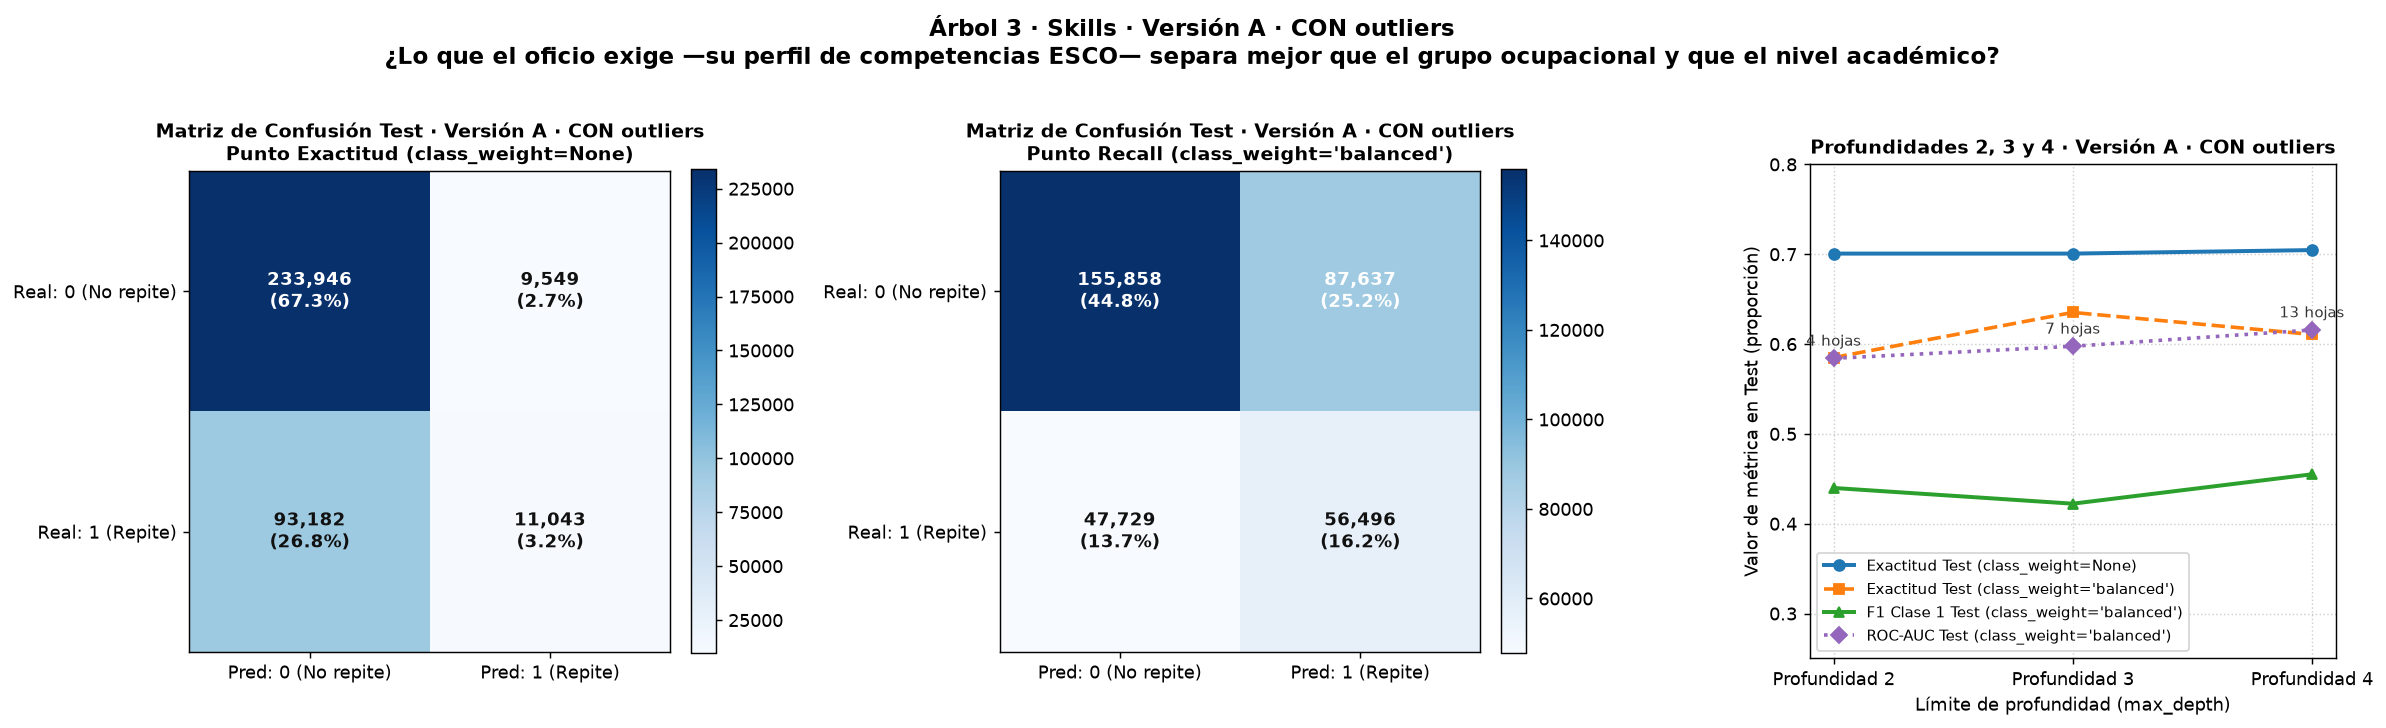

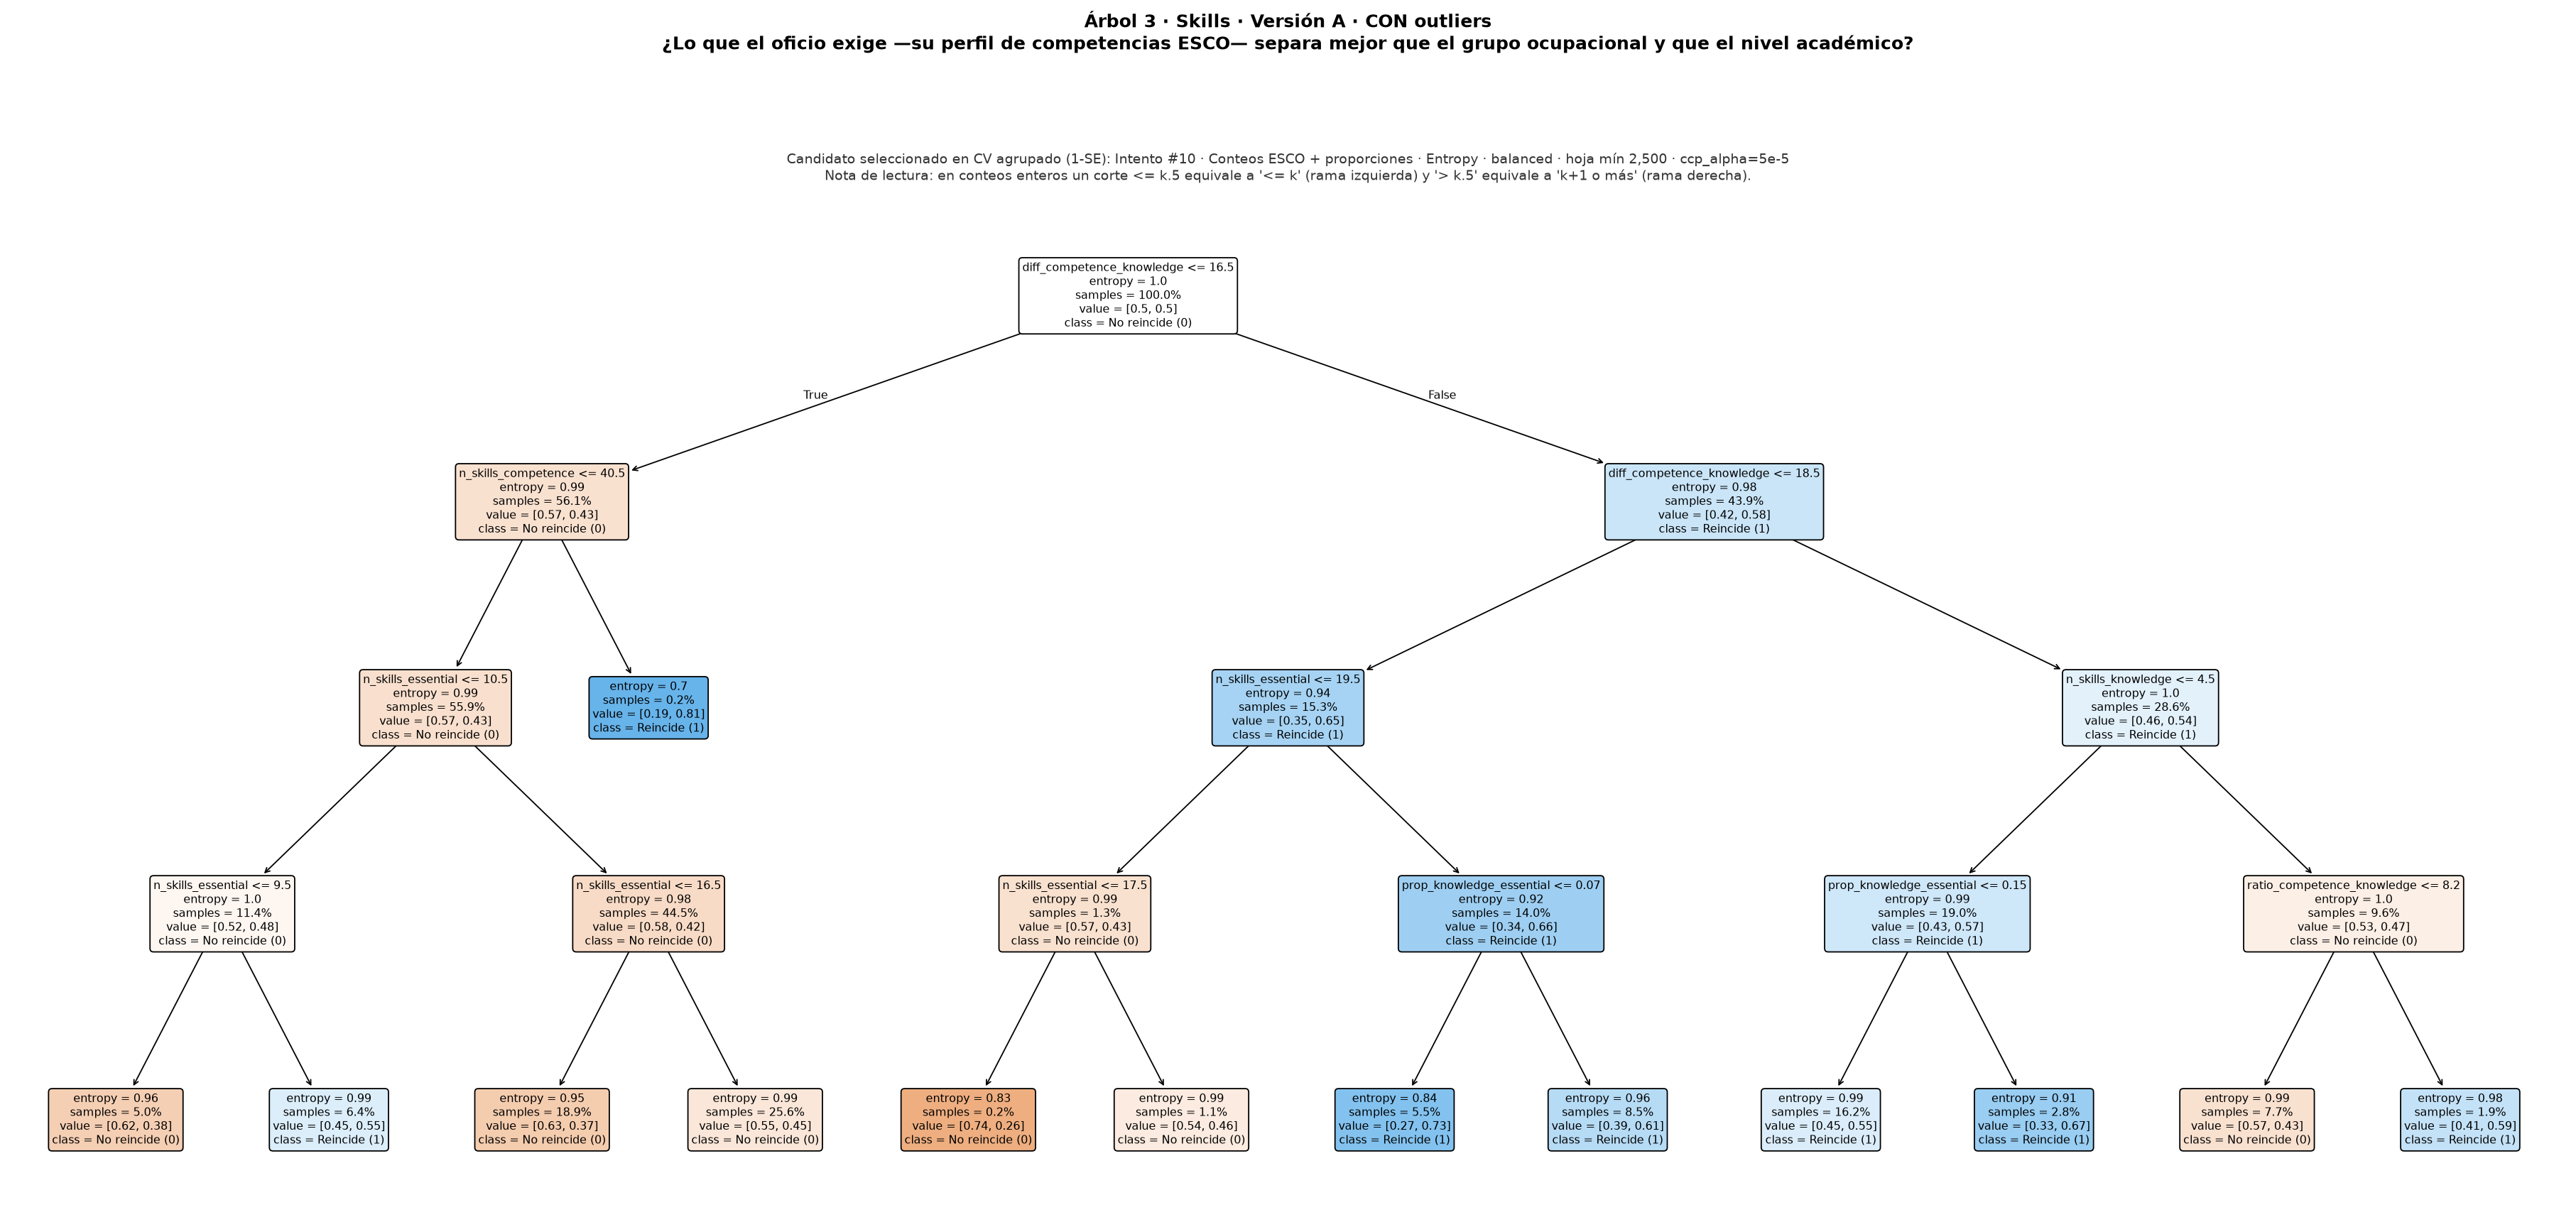

#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión A · CON outliers`

|--- diff_competence_knowledge <= 16.50
|   |--- n_skills_competence <= 40.50
|   |   |--- n_skills_essential <= 10.50
|   |   |   |--- n_skills_essential <= 9.50
|   |   |   |   |--- weights: [39348.83, 24505.28] class: 0
|   |   |   |--- n_skills_essential >  9.50
|   |   |   |   |--- weights: [41565.64, 50484.97] class: 1
|   |   |--- n_skills_essential >  10.50
|   |   |   |--- n_skills_essential <= 16.50
|   |   |   |   |--- weights: [149571.87, 88708.13] class: 0
|   |   |   |--- n_skills_essential >  16.50
|   |   |   |   |--- weights: [189097.87, 153080.92] class: 0
|   |--- n_skills_competence >  40.50
|   |   |--- weights: [639.39, 2740.58] class: 1
|--- diff_competence_knowledge >  16.50
|   |--- diff_competence_knowledge <= 18.50
|   |   |--- n_skills_essential <= 19.50
|   |   |   |--- n_skills_essential <= 17.50
|   |   |   |   |--- weights: [1686.72, 604.76] class: 0
|   |   |   |--- n_skills_essential >  17.50
|   |   |   |   |--- weights: [8078.52, 6807.30] class: 0
| 

#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión A · CON outliers`

version_datos,particion,nivel_arbol,nodo_id,variable,umbral_sklearn,pregunta_es,n_en_nodo,n_izquierda,pct_izquierda,tasa_clase1_izquierda,lift_izquierda,n_derecha,pct_derecha,tasa_clase1_derecha,lift_derecha
Versión A · CON outliers,Train (80%),Nivel 1 · Raíz (Nodo 0),0,diff_competence_knowledge,16.5,¿diff_competence_knowledge <= 16.50? [Izq: diff_competence_knowledge <= 16.5 (16 o menos) | Der: diff_competence_knowledge > 16.5 (17 o más)],1391018,780001,56.07,0.2459,0.819,611017,43.93,0.3694,1.231
Versión A · CON outliers,Train (80%),Nivel 2 · Rama Izquierda (Nodo 1),1,n_skills_competence,40.5,¿n_skills_competence <= 40.50? [Izq: n_skills_competence <= 40.5 (40 o menos) | Der: n_skills_competence > 40.5 (41 o más)],780001,777461,99.67,0.2446,0.815,2540,0.33,0.6476,2.158
Versión A · CON outliers,Train (80%),Nivel 2 · Rama Derecha (Nodo 10),10,diff_competence_knowledge,18.5,¿diff_competence_knowledge <= 18.50? [Izq: diff_competence_knowledge <= 18.5 (18 o menos) | Der: diff_competence_knowledge > 18.5 (19 o más)],611017,212828,34.83,0.4382,1.460,398189,65.17,0.3326,1.108
Versión A · CON outliers,Test (20%),Nivel 1 · Raíz (Nodo 0),0,diff_competence_knowledge,16.5,¿diff_competence_knowledge <= 16.50? [Izq: diff_competence_knowledge <= 16.5 (16 o menos) | Der: diff_competence_knowledge > 16.5 (17 o más)],347720,195015,56.08,0.2460,0.821,152705,43.92,0.3683,1.229
Versión A · CON outliers,Test (20%),Nivel 2 · Rama Izquierda (Nodo 1),1,n_skills_competence,40.5,¿n_skills_competence <= 40.50? [Izq: n_skills_competence <= 40.5 (40 o menos) | Der: n_skills_competence > 40.5 (41 o más)],195015,194375,99.67,0.2448,0.817,640,0.33,0.6188,2.064
Versión A · CON outliers,Test (20%),Nivel 2 · Rama Derecha (Nodo 10),10,diff_competence_knowledge,18.5,¿diff_competence_knowledge <= 18.50? [Izq: diff_competence_knowledge <= 18.5 (18 o menos) | Der: diff_competence_knowledge > 18.5 (19 o más)],152705,53474,35.02,0.4335,1.446,99231,64.98,0.3332,1.112


#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión A · CON outliers`

version_datos,variable,importancia,importancia_pct,descripcion_variable,lectura_metodologica
Versión A · CON outliers,diff_competence_knowledge,0.5772,57.72,Diferencia neta entre competencias prácticas y conocimientos teóricos (n_skills_competence - n_skills_knowledge),Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,n_skills_essential,0.2093,20.93,Conteo total (en unidades reales ESCO) de competencias esenciales exigidas por el oficio,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,prop_knowledge_essential,0.0874,8.74,Proporción de conocimientos teóricos sobre el total esencial (n_skills_knowledge / n_skills_essential),Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,n_skills_knowledge,0.0606,6.06,Conteo (en unidades reales ESCO) de conocimientos teóricos/disciplinares ('saber') del oficio,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,ratio_competence_knowledge,0.0331,3.31,Razón entre competencias prácticas y conocimientos teóricos (n_skills_competence / (n_skills_knowledge + 1)),Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,n_skills_competence,0.0323,3.23,Conteo (en unidades reales ESCO) de competencias prácticas/operativas ('saber hacer') del oficio,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión A · CON outliers,prop_competence_essential,0.0000,0.00,Proporción de competencias prácticas sobre el total esencial (n_skills_competence / n_skills_essential),No utilizada por el árbol en profundidad <= 4


#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión A · CON outliers`

version_datos,punto_operacion,hoja_id,profundidad,predice_reincide,n_train,pct_train,tasa_clase1_train,wilson_ic95_train,tasa_base_train,lift_train,n_test,pct_test,tasa_clase1_test,wilson_ic95_test,wilson_ic95_test_inf,wilson_ic95_test_sup,tasa_base_test,lift_test,soporte_suficiente_train,soporte_suficiente_test,condiciones_hoja_es
Versión A · CON outliers,class_weight='balanced',9,2,1,2540,0.18,0.6476,"[0.6288, 0.6660]",0.3001,2.158,640,0.18,0.6188,"[0.5805, 0.6556]",0.5805,0.6556,0.2997,2.064,No (<0.5%),No (<0.5%),diff_competence_knowledge <= 16.5 (16 o menos) Y n_skills_competence > 40.5 (41 o más)
Versión A · CON outliers,class_weight='balanced',16,4,1,76910,5.53,0.5338,"[0.5303, 0.5373]",0.3001,1.779,19213,5.53,0.5294,"[0.5224, 0.5365]",0.5224,0.5365,0.2997,1.766,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y diff_competence_knowledge <= 18.5 (18 o menos) Y n_skills_essential > 19.5 (20 o más) Y prop_knowledge_essential <= 0.0704
Versión A · CON outliers,class_weight='balanced',21,4,1,39166,2.82,0.4684,"[0.4635, 0.4734]",0.3001,1.561,9947,2.86,0.4787,"[0.4689, 0.4886]",0.4689,0.4886,0.2997,1.597,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y diff_competence_knowledge > 18.5 (19 o más) Y n_skills_knowledge <= 4.5 (4 o menos) Y prop_knowledge_essential > 0.1455
Versión A · CON outliers,class_weight='balanced',17,4,1,117800,8.47,0.4054,"[0.4026, 0.4082]",0.3001,1.351,29552,8.50,0.4005,"[0.3949, 0.4061]",0.3949,0.4061,0.2997,1.336,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y diff_competence_knowledge <= 18.5 (18 o menos) Y n_skills_essential > 19.5 (20 o más) Y prop_knowledge_essential > 0.0704
Versión A · CON outliers,class_weight='balanced',24,4,1,26374,1.90,0.3786,"[0.3728, 0.3845]",0.3001,1.261,6652,1.91,0.3805,"[0.3689, 0.3922]",0.3689,0.3922,0.2997,1.269,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y diff_competence_knowledge > 18.5 (19 o más) Y n_skills_knowledge > 4.5 (5 o más) Y ratio_competence_knowledge > 8.1965
Versión A · CON outliers,class_weight='balanced',20,4,1,225202,16.19,0.3445,"[0.3425, 0.3464]",0.3001,1.148,55993,16.10,0.3429,"[0.3390, 0.3469]",0.3390,0.3469,0.2997,1.144,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y diff_competence_knowledge > 18.5 (19 o más) Y n_skills_knowledge <= 4.5 (4 o menos) Y prop_knowledge_essential <= 0.1455
Versión A · CON outliers,class_weight='balanced',5,4,1,88485,6.36,0.3425,"[0.3393, 0.3456]",0.3001,1.141,22136,6.37,0.3432,"[0.3370, 0.3495]",0.3370,0.3495,0.2997,1.145,Sí,Sí,diff_competence_knowledge <= 16.5 (16 o menos) Y n_skills_competence <= 40.5 (40 o menos) Y n_skills_essential <= 10.5 (10 o menos) Y n_skills_essential > 9.5 (10 o más)
Versión A · CON outliers,class_weight='balanced',14,4,0,15394,1.11,0.2654,"[0.2585, 0.2725]",0.3001,0.884,3986,1.15,0.2659,"[0.2524, 0.2799]",0.2524,0.2799,0.2997,0.887,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y diff_competence_knowledge <= 18.5 (18 o menos) Y n_skills_essential <= 19.5 (19 o menos) Y n_skills_essential > 17.5 (18 o más)
Versión A · CON outliers,class_weight='balanced',8,4,0,356577,25.63,0.2577,"[0.2563, 0.2591]",0.3001,0.859,89070,25.62,0.2575,"[0.2546, 0.2604]",0.2546,0.2604,0.2997,0.859,Sí,Sí,diff_competence_knowledge <= 16.5 (16 o menos) Y n_skills_competence <= 40.5 (40 o menos) Y n_skills_essential > 10.5 (11 o más) Y n_skills_essential > 16.5 (17 o más)
Versión A · CON outliers,class_weight='balanced',23,4,0,107447,7.72,0.2468,"[0.2443, 0.2494]",0.3001,0.822,26639,7.66,0.2466,"[0.2414, 0.2518]",0.2414,0.2518,0.2997,0.823,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y diff_competence_knowledge > 18.5 (19 o más) Y n_skills_knowledge > 4.5 (5 o más) Y ratio_competence_knowledge <= 8.1965


#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión A · CON outliers`

version_datos,regla_num,hoja_id,predice_reincide,n_registros_train,tasa_clase1_train_pct,lift_train,n_registros_test,tasa_clase1_test_pct,wilson_ic95_test,lift_test,regla_negocio_espanol,advertencia_lo_que_no_dice
Versión A · CON outliers,1,16,1,76910,53.38,1.779,19213,52.94,"[0.5224, 0.5365]",1.766,"Regla basada en perfil puntual 1 (Árbol 3 · Skills · Versión A · CON outliers, Hoja 16): SI el registro cumple [diff_competence_knowledge > 16.5 (17 o más) Y diff_competence_knowledge <= 18.5 (18 o menos) Y n_skills_essential > 19.5 (20 o más) Y prop_knowledge_essential <= 0.0704], la identidad entera E = C + K restringe algebraicamente la hoja al único perfil discreto de competencias (n_skills_essential = 20, n_skills_competence = 19, n_skills_knowledge = 1), ubicándolo en clase positiva (reincide = 1 en punto balanceado). En Train agrupa 76,910 registros (5.53% del split) con tasa de repetición de 53.38% frente a 30.01% base (Lift = 1.779x), y en Test agrupa 19,213 registros (5.53%) con tasa de 52.94% (IC95% Wilson = [0.5224, 0.5365]) frente a 29.97% base (Lift = 1.766x). ADVERTENCIA DE CIRCULARIDAD (huella de oficio): este perfil puntual NO representa una ley general sobre 'oficios que exigen más competencias', sino una huella discreta compartida por 12 ocupaciones en 7 grandes grupos ISCO, donde una sola ocupación (3343.1 · administrative assistant, Gran Grupo 3) aporta el 86.88% de las filas con tasa de repetición de 57.02% en Train y 56.56% en Test, mientras que la segunda (9111.1 · domestic cleaner, Gran Grupo 9, 9.47% de la hoja) tiene 30.09% (igual a la tasa base).","Regla de perfil puntual (E=20, C=19, K=1) con circularidad parcial N:1: actúa como huella de la ocupación 3343.1 (86.88% de la hoja), NO como efecto general de exigir más competencias."
Versión A · CON outliers,2,21,1,39166,46.84,1.561,9947,47.87,"[0.4689, 0.4886]",1.597,"Regla 2 (Árbol 3 · Skills · Versión A · CON outliers, Hoja 21): SI el registro de empleo cumple que [diff_competence_knowledge > 16.5 (17 o más) Y diff_competence_knowledge > 18.5 (19 o más) Y n_skills_knowledge <= 4.5 (4 o menos) Y prop_knowledge_essential > 0.1455], ENTONCES el árbol ubica el perfil del oficio con mayor propensión a repetición (predice reincide = 1 en punto balanceado). En Train agrupa 39,166 registros (2.82% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 46.84% frente a la tasa base de 30.01% (Lift = 1.561x). En Test comprende 9,947 registros (2.86%) con tasa de 47.87% (IC95% Wilson = [0.4689, 0.4886]) frente a 29.97% base (Lift = 1.597x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."
Versión A · CON outliers,3,7,0,262611,20.28,0.676,65488,20.29,"[0.1999, 0.2060]",0.677,"Regla 3 (Árbol 3 · Skills · Versión A · CON outliers, Hoja 7): SI el registro de empleo cumple que [diff_competence_knowledge <= 16.5 (16 o menos) Y n_skills_competence <= 40.5 (40 o menos) Y n_skills_essential > 10.5 (11 o más) Y n_skills_essential <= 16.5 (16 o menos)], ENTONCES el árbol ubica el perfil del oficio con menor propensión a repetición / ejercicio único (predice reincide = 0). En Train agrupa 262,611 registros (18.88% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 20.28% frente a la tasa base de 30.01% (Lift = 0.676x). En Test comprende 65,488 registros (18.83%) con tasa de 20.29% (IC95% Wilson = [0.1999, 0.2060]) frente a 29.97% base (Lift = 0.677x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."


In [10]:
# Section 6.1: Árbol 3 · Competencias ESCO on Version A (CON outliers)
bundle_a_curr = bundles_a["tree_3_skills"]
cm_none_a = bundle_a_curr.confusion_matrices_by_point["Punto 1 · Orientado a Exactitud (class_weight=None)"]["test"]
cm_bal_a = bundle_a_curr.confusion_matrices_by_point["Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced')"]["test"]

display(Markdown(f"#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión A · CON outliers`\n**Pregunta**: *¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?*"))
display(bundle_a_curr.operating_points_df)

display(Markdown(f"#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión A · CON outliers`"))
display(bundle_a_curr.depth_df)

fig_panel_a = plot_depth_and_confusion_panel(
    depth_df=bundle_a_curr.depth_df,
    cm_test_none=cm_none_a,
    cm_test_balanced=cm_bal_a,
    tree_label_es=bundle_a_curr.tree_label_es,
    question_es=bundle_a_curr.question_es,
    version_label_es=bundle_a_curr.version_label_es,
    output_path=CONFIG.figures_dir / "03_arbol_3_skills_panel_version_a.png",
)
plt.show()
plt.close(fig_panel_a)

fig_tree_a = plot_decision_tree_legible(
    clf=bundle_a_curr.tuning_result.fitted_tree_balanced,
    feature_names=list(bundle_a_curr.tuning_result.X_train.columns),
    tree_label_es=bundle_a_curr.tree_label_es,
    question_es=bundle_a_curr.question_es,
    version_label_es=bundle_a_curr.version_label_es,
    subtitle_es=f"Candidato seleccionado en CV agrupado (1-SE): Intento #{bundle_a_curr.tuning_result.selected_attempt_id} · {bundle_a_curr.tuning_result.selected_spec.description_es}",
    output_path=CONFIG.figures_dir / "03_arbol_3_skills_tree_depth4_version_a.png",
)
plt.show()
plt.close(fig_tree_a)

display(Markdown(f"#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión A · CON outliers`"))
print(bundle_a_curr.export_text_balanced_str)

display(Markdown(f"#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión A · CON outliers`"))
display(pd.concat([bundle_a_curr.first_questions_train_df, bundle_a_curr.first_questions_test_df], ignore_index=True))

display(Markdown(f"#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión A · CON outliers`"))
display(bundle_a_curr.importances_df.head(10))

display(Markdown(f"#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión A · CON outliers`"))
display(bundle_a_curr.leaf_lift_balanced_df)

display(Markdown(f"#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión A · CON outliers`"))
display(bundle_a_curr.business_rules_df[["version_datos", "regla_num", "hoja_id", "predice_reincide", "n_registros_train", "tasa_clase1_train_pct", "lift_train", "n_registros_test", "tasa_clase1_test_pct", "wilson_ic95_test", "lift_test", "regla_negocio_espanol", "advertencia_lo_que_no_dice"]])

### 6.2 Sección `Versión B · SIN outliers` — ¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?
A continuación replicamos exactamente el mismo análisis, partición por persona, variables e hiperparámetros sobre **`Versión B · SIN outliers`** (datos winsorizados por IQR), manteniendo todas las etiquetas de versión explícitas en tablas y gráficos.

#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión B · SIN outliers`
**Pregunta**: *¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?*

version_datos,arbol,pregunta_objetivo,punto_operacion,regla_decision,profundidad_efectiva,n_hojas,train_accuracy,test_accuracy,test_accuracy_ic95_persona,gap_acc_train_test,train_precision_1,test_precision_1,train_recall_1,test_recall_1,test_recall_1_ic95_persona,train_f1_1,test_f1_1,test_f1_1_ic95_persona,f1_ref_trivial_todo_1,delta_f1_vs_trivial_todo_1,train_roc_auc,test_roc_auc,test_roc_auc_ic95_persona,roc_auc_ic95_inf,roc_auc_ic95_sup,roc_auc_techo_6_0,pct_del_techo_auc_6_0,hoja_elegida_en_train_id,lift_train_hoja_elegida,max_lift_hoja_soporte_05pct,max_lift_test_referencia_optimista,hoja_con_lift_ge_150_y_soporte_05pct,criterio_separa_clases,supera_baseline_exactitud_7003,brecha_vs_meta_085_f1,tn_test,fp_test,fn_test,tp_test
Versión B · SIN outliers,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Punto 1 · Orientado a Exactitud (class_weight=None),Umbral estándar 0.50 sobre tasa empírica de hoja,4,16,0.7043,0.7047,"[0.7027, 0.7068]",-0.0004,0.525,0.5255,0.1541,0.1535,"[0.1496, 0.1568]",0.2383,0.2376,"[0.2324, 0.2420]",0.4612,-0.2236,0.6218,0.6213,"[0.6185, 0.6243]",0.6185,0.6243,0.7132,56.89,26,1.779,1.766,1.766,Sí,SÍ SEPARA (IC95% AUC > 0.50 y Hoja Lift >= 1.50),Sí (supera el baseline con recall > 0),0.6124,229047,14448,88225,16000
Versión B · SIN outliers,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),Pesos balanceados inversamente proporcionales a 70/30,4,16,0.5780,0.5777,"[0.5757, 0.5797]",0.0003,0.377,0.3762,0.6222,0.6217,"[0.6168, 0.6265]",0.4695,0.4688,"[0.4656, 0.4722]",0.4612,0.0075,0.6212,0.6203,"[0.6172, 0.6230]",0.6172,0.6230,0.7132,56.41,26,1.779,1.766,1.766,Sí,SÍ SEPARA (IC95% AUC > 0.50 y Hoja Lift >= 1.50),No (prioriza Recall sobre exactitud global),0.3812,136068,107427,39430,64795
Versión B · SIN outliers,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Punto 3 · Umbral OOF óptimo en Train (tau*=0.370),Predice 1 si P(reincide=1|hoja) >= 0.370 (sujeto a Acc >= Baseline en OOF Train),4,16,0.7021,0.7025,"[0.7005, 0.7046]",-0.0004,0.509,0.5092,0.2087,0.2091,"[0.2049, 0.2125]",0.2960,0.2965,"[0.2914, 0.3008]",0.4612,-0.1648,0.6218,0.6213,"[0.6185, 0.6243]",0.6185,0.6243,0.7132,56.89,26,1.779,1.766,1.766,Sí,SÍ SEPARA (IC95% AUC > 0.50 y Hoja Lift >= 1.50),Sí (supera el baseline con recall > 0),0.5535,222492,21003,82432,21793


#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión B · SIN outliers`

version_datos,arbol,punto_operacion,max_depth,profundidad_alcanzada,n_leaves,train_acc,test_acc,gap_train_test,train_f1_clase_1,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,test_roc_auc
Versión B · SIN outliers,Árbol 3 · Skills,class_weight=None (Exactitud),2,2,4,0.6999,0.7003,-0.0004,0.0000,0.0000,0.0000,0.0000,0.5892
Versión B · SIN outliers,Árbol 3 · Skills,class_weight=None (Exactitud),3,3,8,0.7015,0.7016,-0.0001,0.2063,0.5087,0.1296,0.2066,0.6091
Versión B · SIN outliers,Árbol 3 · Skills,class_weight=None (Exactitud),4,4,16,0.7043,0.7047,-0.0004,0.2383,0.5255,0.1535,0.2376,0.6213
Versión B · SIN outliers,Árbol 3 · Skills,class_weight='balanced' (Recall),2,2,4,0.5855,0.5849,0.0006,0.4409,0.3693,0.5435,0.4398,0.5892
Versión B · SIN outliers,Árbol 3 · Skills,class_weight='balanced' (Recall),3,3,8,0.5655,0.5650,0.0005,0.4602,0.3660,0.6164,0.4593,0.6091
Versión B · SIN outliers,Árbol 3 · Skills,class_weight='balanced' (Recall),4,4,16,0.5780,0.5777,0.0003,0.4695,0.3762,0.6217,0.4688,0.6203


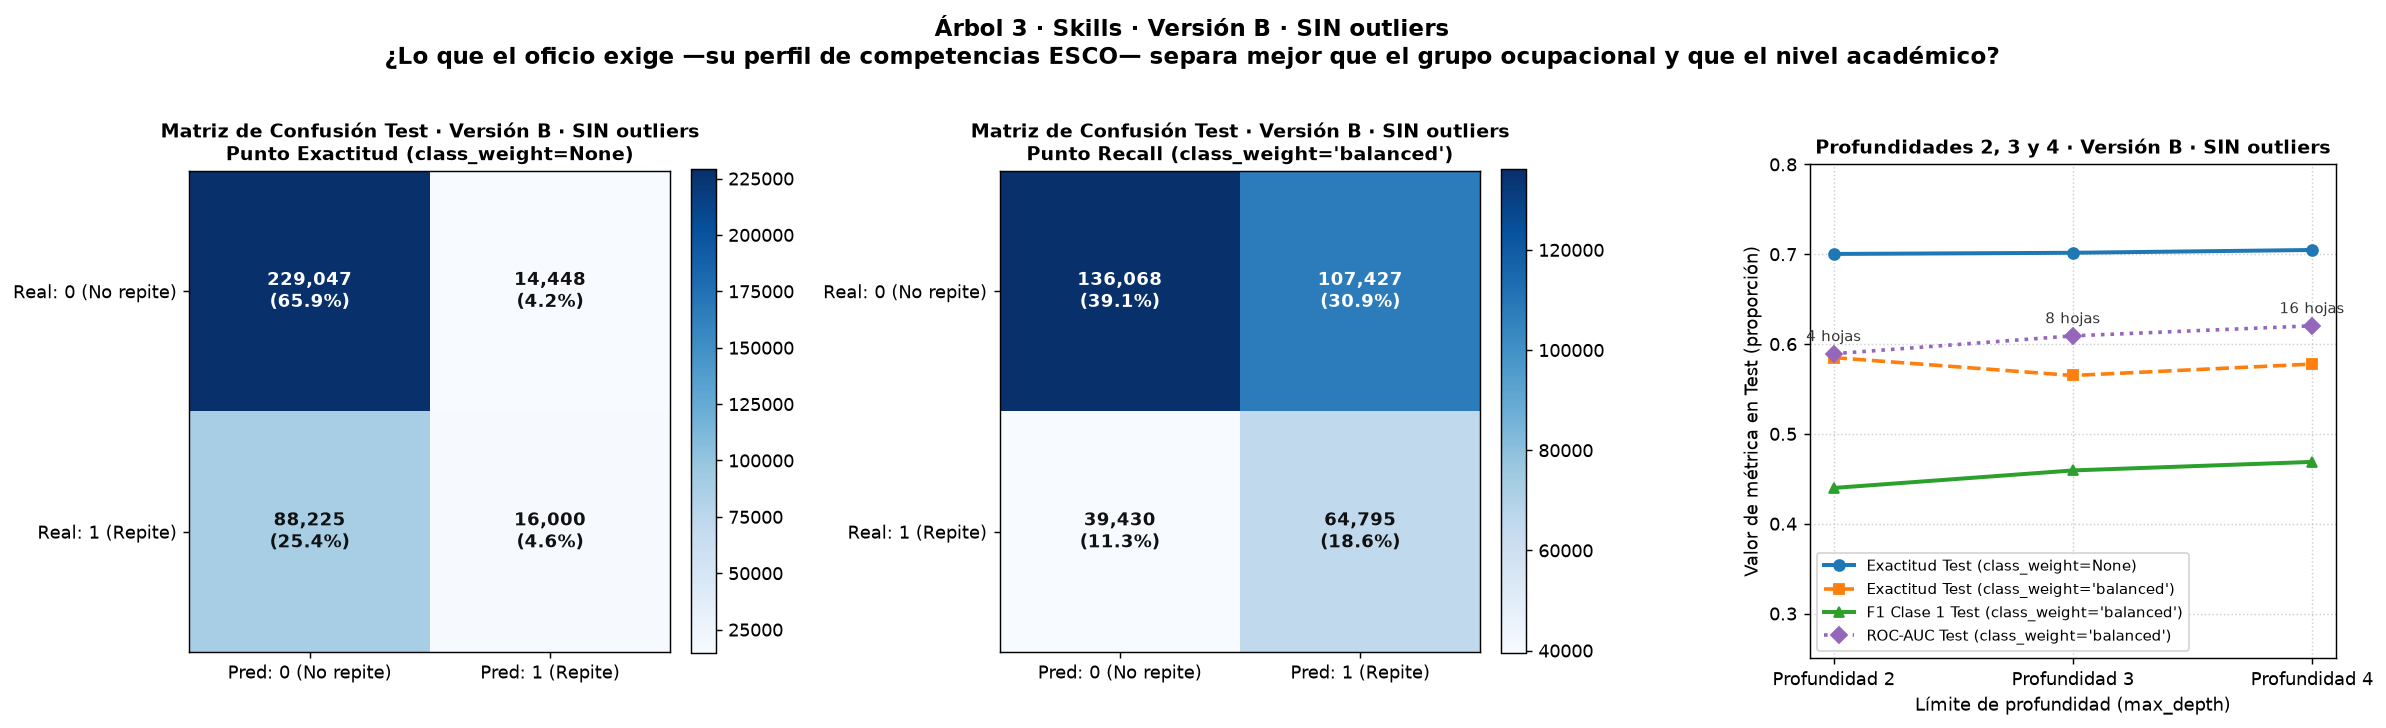

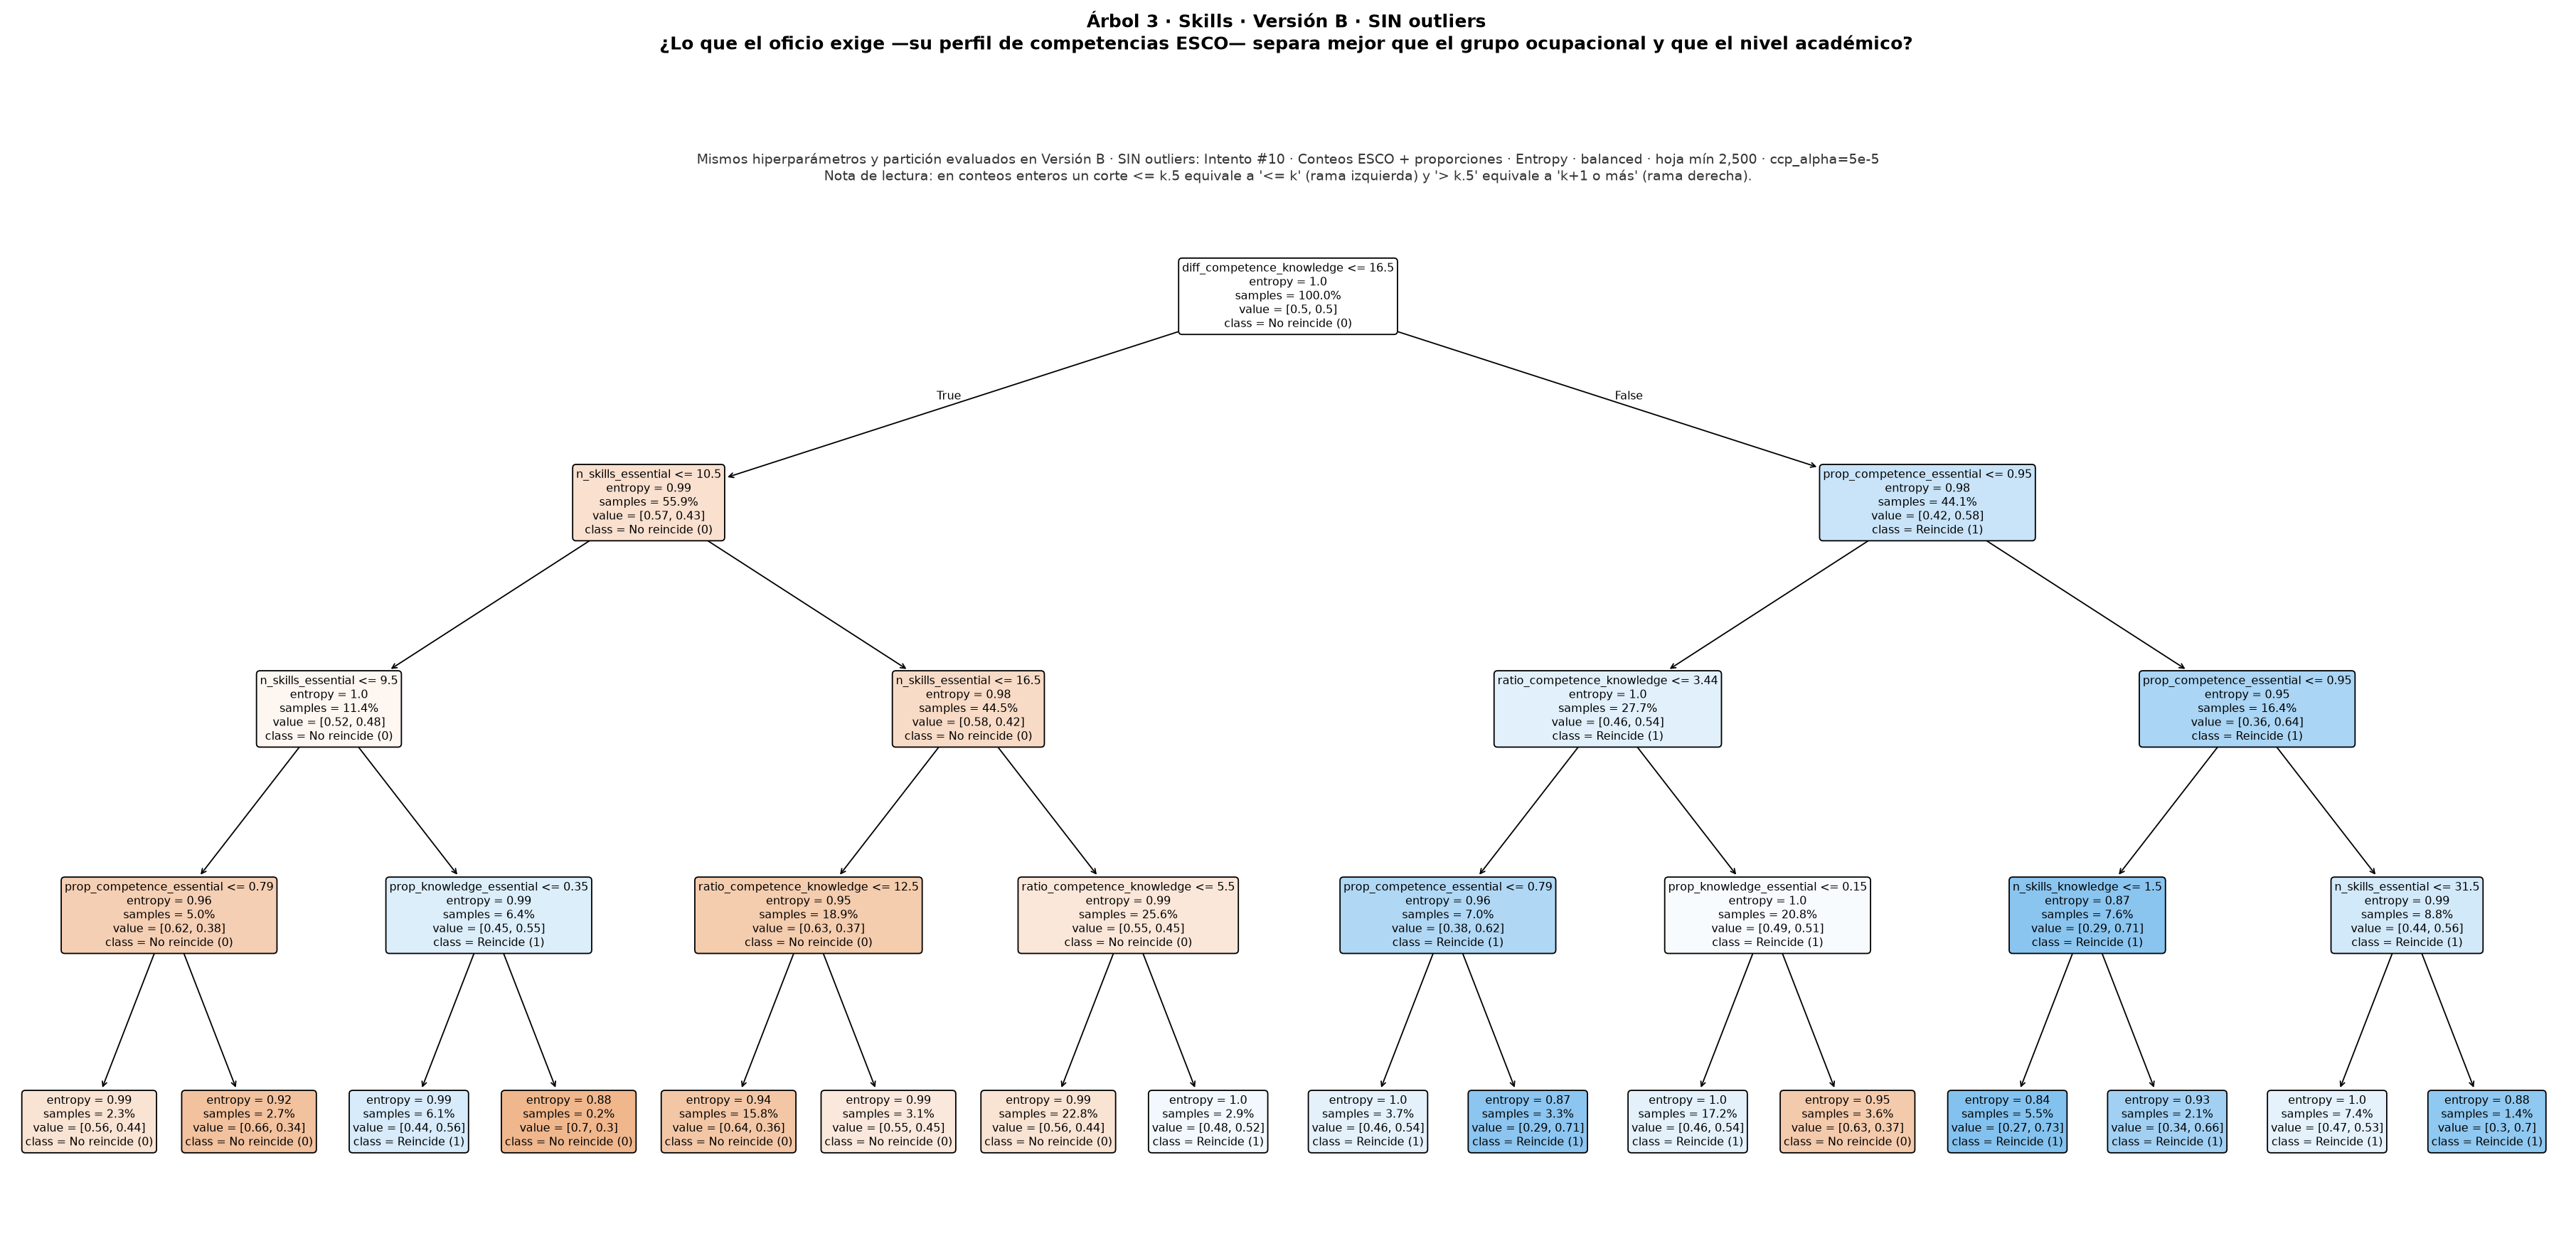

#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión B · SIN outliers`

|--- diff_competence_knowledge <= 16.50
|   |--- n_skills_essential <= 10.50
|   |   |--- n_skills_essential <= 9.50
|   |   |   |--- prop_competence_essential <= 0.79
|   |   |   |   |--- weights: [17048.61, 13259.74] class: 0
|   |   |   |--- prop_competence_essential >  0.79
|   |   |   |   |--- weights: [22300.22, 11245.54] class: 0
|   |   |--- n_skills_essential >  9.50
|   |   |   |--- prop_knowledge_essential <= 0.35
|   |   |   |   |--- weights: [39657.46, 49673.62] class: 1
|   |   |   |--- prop_knowledge_essential >  0.35
|   |   |   |   |--- weights: [1908.18, 811.34] class: 0
|   |--- n_skills_essential >  10.50
|   |   |--- n_skills_essential <= 16.50
|   |   |   |--- ratio_competence_knowledge <= 12.50
|   |   |   |   |--- weights: [126894.44, 70095.52] class: 0
|   |   |   |--- ratio_competence_knowledge >  12.50
|   |   |   |   |--- weights: [22677.43, 18612.61] class: 0
|   |   |--- n_skills_essential >  16.50
|   |   |   |--- ratio_competence_knowledge <= 5.50
|   | 

#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión B · SIN outliers`

version_datos,particion,nivel_arbol,nodo_id,variable,umbral_sklearn,pregunta_es,n_en_nodo,n_izquierda,pct_izquierda,tasa_clase1_izquierda,lift_izquierda,n_derecha,pct_derecha,tasa_clase1_derecha,lift_derecha
Versión B · SIN outliers,Train (80%),Nivel 1 · Raíz (Nodo 0),0,diff_competence_knowledge,16.5000,¿diff_competence_knowledge <= 16.50? [Izq: diff_competence_knowledge <= 16.5 (16 o menos) | Der: diff_competence_knowledge > 16.5 (17 o más)],1391018,777220,55.87,0.2446,0.815,613798,44.13,0.3704,1.234
Versión B · SIN outliers,Train (80%),Nivel 2 · Rama Izquierda (Nodo 1),1,n_skills_essential,10.5000,¿n_skills_essential <= 10.50? [Izq: n_skills_essential <= 10.5 (10 o menos) | Der: n_skills_essential > 10.5 (11 o más)],777220,158273,20.36,0.2844,0.948,618947,79.64,0.2344,0.781
Versión B · SIN outliers,Train (80%),Nivel 2 · Rama Derecha (Nodo 16),16,prop_competence_essential,0.9493,¿prop_competence_essential <= 0.95? [Izq: prop_competence_essential <= 0.9493 | Der: prop_competence_essential > 0.9493],613798,385923,62.87,0.3362,1.120,227875,37.13,0.4283,1.427
Versión B · SIN outliers,Test (20%),Nivel 1 · Raíz (Nodo 0),0,diff_competence_knowledge,16.5000,¿diff_competence_knowledge <= 16.50? [Izq: diff_competence_knowledge <= 16.5 (16 o menos) | Der: diff_competence_knowledge > 16.5 (17 o más)],347720,194333,55.89,0.2448,0.817,153387,44.11,0.3693,1.232
Versión B · SIN outliers,Test (20%),Nivel 2 · Rama Izquierda (Nodo 1),1,n_skills_essential,10.5000,¿n_skills_essential <= 10.50? [Izq: n_skills_essential <= 10.5 (10 o menos) | Der: n_skills_essential > 10.5 (11 o más)],194333,39817,20.49,0.2853,0.952,154516,79.51,0.2344,0.782
Versión B · SIN outliers,Test (20%),Nivel 2 · Rama Derecha (Nodo 16),16,prop_competence_essential,0.9493,¿prop_competence_essential <= 0.95? [Izq: prop_competence_essential <= 0.9493 | Der: prop_competence_essential > 0.9493],153387,96213,62.73,0.3352,1.118,57174,37.27,0.4267,1.424


#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión B · SIN outliers`

version_datos,variable,importancia,importancia_pct,descripcion_variable,lectura_metodologica
Versión B · SIN outliers,diff_competence_knowledge,0.4375,43.75,Diferencia neta entre competencias prácticas y conocimientos teóricos (n_skills_competence - n_skills_knowledge),Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,prop_competence_essential,0.2241,22.41,Proporción de competencias prácticas sobre el total esencial (n_skills_competence / n_skills_essential),Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,n_skills_essential,0.1663,16.63,Conteo total (en unidades reales ESCO) de competencias esenciales exigidas por el oficio,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,ratio_competence_knowledge,0.0902,9.02,Razón entre competencias prácticas y conocimientos teóricos (n_skills_competence / (n_skills_knowledge + 1)),Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,prop_knowledge_essential,0.0734,7.34,Proporción de conocimientos teóricos sobre el total esencial (n_skills_knowledge / n_skills_essential),Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,n_skills_knowledge,0.0085,0.85,Conteo (en unidades reales ESCO) de conocimientos teóricos/disciplinares ('saber') del oficio,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
Versión B · SIN outliers,n_skills_competence,0.0000,0.00,Conteo (en unidades reales ESCO) de competencias prácticas/operativas ('saber hacer') del oficio,No utilizada por el árbol en profundidad <= 4


#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión B · SIN outliers`

version_datos,punto_operacion,hoja_id,profundidad,predice_reincide,n_train,pct_train,tasa_clase1_train,wilson_ic95_train,tasa_base_train,lift_train,n_test,pct_test,tasa_clase1_test,wilson_ic95_test,wilson_ic95_test_inf,wilson_ic95_test_sup,tasa_base_test,lift_test,soporte_suficiente_train,soporte_suficiente_test,condiciones_hoja_es
Versión B · SIN outliers,class_weight='balanced',26,4,1,76910,5.53,0.5338,"[0.5303, 0.5373]",0.3001,1.779,19213,5.53,0.5294,"[0.5224, 0.5365]",0.5224,0.5365,0.2997,1.766,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y prop_competence_essential > 0.9493 Y prop_competence_essential <= 0.9512 Y n_skills_knowledge <= 1.5 (1 o menos)
Versión B · SIN outliers,class_weight='balanced',20,4,1,45672,3.28,0.5101,"[0.5055, 0.5147]",0.3001,1.700,11235,3.23,0.5187,"[0.5095, 0.5280]",0.5095,0.5280,0.2997,1.731,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y prop_competence_essential <= 0.9493 Y ratio_competence_knowledge <= 3.4365 Y prop_competence_essential > 0.7919
Versión B · SIN outliers,class_weight='balanced',30,4,1,19893,1.43,0.4967,"[0.4897, 0.5036]",0.3001,1.655,4998,1.44,0.4908,"[0.4769, 0.5047]",0.4769,0.5047,0.2997,1.637,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y prop_competence_essential > 0.9493 Y prop_competence_essential > 0.9512 Y n_skills_essential > 31.5 (32 o más)
Versión B · SIN outliers,class_weight='balanced',27,4,1,28678,2.06,0.4494,"[0.4437, 0.4552]",0.3001,1.498,7350,2.11,0.4544,"[0.4431, 0.4658]",0.4431,0.4658,0.2997,1.516,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y prop_competence_essential > 0.9493 Y prop_competence_essential <= 0.9512 Y n_skills_knowledge > 1.5 (2 o más)
Versión B · SIN outliers,class_weight='balanced',7,4,1,85327,6.13,0.3494,"[0.3462, 0.3526]",0.3001,1.164,21317,6.13,0.3498,"[0.3434, 0.3562]",0.3434,0.3562,0.2997,1.167,Sí,Sí,diff_competence_knowledge <= 16.5 (16 o menos) Y n_skills_essential <= 10.5 (10 o menos) Y n_skills_essential > 9.5 (10 o más) Y prop_knowledge_essential <= 0.3500
Versión B · SIN outliers,class_weight='balanced',22,4,1,238880,17.17,0.3323,"[0.3304, 0.3342]",0.3001,1.107,59560,17.13,0.3318,"[0.3280, 0.3356]",0.3280,0.3356,0.2997,1.107,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y prop_competence_essential <= 0.9493 Y ratio_competence_knowledge > 3.4365 Y prop_knowledge_essential <= 0.1526
Versión B · SIN outliers,class_weight='balanced',19,4,1,51459,3.70,0.3323,"[0.3283, 0.3364]",0.3001,1.107,13021,3.74,0.3226,"[0.3146, 0.3306]",0.3146,0.3306,0.2997,1.076,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y prop_competence_essential <= 0.9493 Y ratio_competence_knowledge <= 3.4365 Y prop_competence_essential <= 0.7919
Versión B · SIN outliers,class_weight='balanced',29,4,1,102394,7.36,0.3299,"[0.3271, 0.3328]",0.3001,1.099,25613,7.37,0.3291,"[0.3234, 0.3349]",0.3234,0.3349,0.2997,1.098,Sí,Sí,diff_competence_knowledge > 16.5 (17 o más) Y prop_competence_essential > 0.9493 Y prop_competence_essential > 0.9512 Y n_skills_essential <= 31.5 (31 o menos)
Versión B · SIN outliers,class_weight='balanced',15,4,1,39801,2.86,0.3150,"[0.3105, 0.3196]",0.3001,1.050,9915,2.85,0.3181,"[0.3090, 0.3273]",0.3090,0.3273,0.2997,1.061,Sí,Sí,diff_competence_knowledge <= 16.5 (16 o menos) Y n_skills_essential > 10.5 (11 o más) Y n_skills_essential > 16.5 (17 o más) Y ratio_competence_knowledge > 5.5000
Versión B · SIN outliers,class_weight='balanced',12,4,0,42915,3.09,0.2603,"[0.2562, 0.2645]",0.3001,0.867,10542,3.03,0.2549,"[0.2467, 0.2633]",0.2467,0.2633,0.2997,0.850,Sí,Sí,diff_competence_knowledge <= 16.5 (16 o menos) Y n_skills_essential > 10.5 (11 o más) Y n_skills_essential <= 16.5 (16 o menos) Y ratio_competence_knowledge > 12.5000


#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión B · SIN outliers`

version_datos,regla_num,hoja_id,predice_reincide,n_registros_train,tasa_clase1_train_pct,lift_train,n_registros_test,tasa_clase1_test_pct,wilson_ic95_test,lift_test,regla_negocio_espanol,advertencia_lo_que_no_dice
Versión B · SIN outliers,1,26,1,76910,53.38,1.779,19213,52.94,"[0.5224, 0.5365]",1.766,"Regla basada en perfil puntual 1 (Árbol 3 · Skills · Versión B · SIN outliers, Hoja 26): SI el registro cumple [diff_competence_knowledge > 16.5 (17 o más) Y prop_competence_essential > 0.9493 Y prop_competence_essential <= 0.9512 Y n_skills_knowledge <= 1.5 (1 o menos)], la identidad entera E = C + K restringe algebraicamente la hoja al único perfil discreto de competencias (n_skills_essential = 20, n_skills_competence = 19, n_skills_knowledge = 1), ubicándolo en clase positiva (reincide = 1 en punto balanceado). En Train agrupa 76,910 registros (5.53% del split) con tasa de repetición de 53.38% frente a 30.01% base (Lift = 1.779x), y en Test agrupa 19,213 registros (5.53%) con tasa de 52.94% (IC95% Wilson = [0.5224, 0.5365]) frente a 29.97% base (Lift = 1.766x). ADVERTENCIA DE CIRCULARIDAD (huella de oficio): este perfil puntual NO representa una ley general sobre 'oficios que exigen más competencias', sino una huella discreta compartida por 12 ocupaciones en 7 grandes grupos ISCO, donde una sola ocupación (3343.1 · administrative assistant, Gran Grupo 3) aporta el 86.88% de las filas con tasa de repetición de 57.02% en Train y 56.56% en Test, mientras que la segunda (9111.1 · domestic cleaner, Gran Grupo 9, 9.47% de la hoja) tiene 30.09% (igual a la tasa base).","Regla de perfil puntual (E=20, C=19, K=1) con circularidad parcial N:1: actúa como huella de la ocupación 3343.1 (86.88% de la hoja), NO como efecto general de exigir más competencias."
Versión B · SIN outliers,2,20,1,45672,51.01,1.700,11235,51.87,"[0.5095, 0.5280]",1.731,"Regla 2 (Árbol 3 · Skills · Versión B · SIN outliers, Hoja 20): SI el registro de empleo cumple que [diff_competence_knowledge > 16.5 (17 o más) Y prop_competence_essential <= 0.9493 Y ratio_competence_knowledge <= 3.4365 Y prop_competence_essential > 0.7919], ENTONCES el árbol ubica el perfil del oficio con mayor propensión a repetición (predice reincide = 1 en punto balanceado). En Train agrupa 45,672 registros (3.28% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 51.01% frente a la tasa base de 30.01% (Lift = 1.700x). En Test comprende 11,235 registros (3.23%) con tasa de 51.87% (IC95% Wilson = [0.5095, 0.5280]) frente a 29.97% base (Lift = 1.731x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."
Versión B · SIN outliers,3,5,0,37965,17.78,0.592,9588,17.90,"[0.1714, 0.1868]",0.597,"Regla 3 (Árbol 3 · Skills · Versión B · SIN outliers, Hoja 5): SI el registro de empleo cumple que [diff_competence_knowledge <= 16.5 (16 o menos) Y n_skills_essential <= 10.5 (10 o menos) Y n_skills_essential <= 9.5 (9 o menos) Y prop_competence_essential > 0.7889], ENTONCES el árbol ubica el perfil del oficio con menor propensión a repetición / ejercicio único (predice reincide = 0). En Train agrupa 37,965 registros (2.73% del total, soporte >= 0.5%) con una tasa empírica de reincidencia de 17.78% frente a la tasa base de 30.01% (Lift = 0.592x). En Test comprende 9,588 registros (2.76%) con tasa de 17.90% (IC95% Wilson = [0.1714, 0.1868]) frente a 29.97% base (Lift = 0.597x).","Esta regla NO es causal, clasifica perfiles de oficios con soporte >= 0.5% (no toma decisiones sobre personas individuales) y la exactitud global puede engañar ante el desbalance 70/30."


In [11]:
# Section 6.2: Árbol 3 · Competencias ESCO on Version B (SIN outliers)
bundle_b_curr = bundles_b["tree_3_skills"]
cm_none_b = bundle_b_curr.confusion_matrices_by_point["Punto 1 · Orientado a Exactitud (class_weight=None)"]["test"]
cm_bal_b = bundle_b_curr.confusion_matrices_by_point["Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced')"]["test"]

display(Markdown(f"#### Métricas en Train y Test con 2 Puntos Operativos, Umbral OOF e IC95% por Persona · `Versión B · SIN outliers`\n**Pregunta**: *¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?*"))
display(bundle_b_curr.operating_points_df)

display(Markdown(f"#### Tabla de Profundidades 2, 3 y 4 (`max_depth <= 4`) · `Versión B · SIN outliers`"))
display(bundle_b_curr.depth_df)

fig_panel_b = plot_depth_and_confusion_panel(
    depth_df=bundle_b_curr.depth_df,
    cm_test_none=cm_none_b,
    cm_test_balanced=cm_bal_b,
    tree_label_es=bundle_b_curr.tree_label_es,
    question_es=bundle_b_curr.question_es,
    version_label_es=bundle_b_curr.version_label_es,
    output_path=CONFIG.figures_dir / "03_arbol_3_skills_panel_version_b.png",
)
plt.show()
plt.close(fig_panel_b)

fig_tree_b = plot_decision_tree_legible(
    clf=bundle_b_curr.tuning_result.fitted_tree_balanced,
    feature_names=list(bundle_b_curr.tuning_result.X_train.columns),
    tree_label_es=bundle_b_curr.tree_label_es,
    question_es=bundle_b_curr.question_es,
    version_label_es=bundle_b_curr.version_label_es,
    subtitle_es=f"Mismos hiperparámetros y partición evaluados en Versión B · SIN outliers: Intento #{bundle_b_curr.tuning_result.selected_attempt_id} · {bundle_b_curr.tuning_result.selected_spec.description_es}",
    output_path=CONFIG.figures_dir / "03_arbol_3_skills_tree_depth4_version_b.png",
)
plt.show()
plt.close(fig_tree_b)

display(Markdown(f"#### Reglas en texto (`export_text`, `max_depth=4`) · `Versión B · SIN outliers`"))
print(bundle_b_curr.export_text_balanced_str)

display(Markdown(f"#### Primeras preguntas del árbol (Raíz y Nivel 2 calculadas con `decision_path`) · `Versión B · SIN outliers`"))
display(pd.concat([bundle_b_curr.first_questions_train_df, bundle_b_curr.first_questions_test_df], ignore_index=True))

display(Markdown(f"#### Importancia de variables (`feature_importances_` · Lo que este árbol miró, NO causalidad) · `Versión B · SIN outliers`"))
display(bundle_b_curr.importances_df.head(10))

display(Markdown(f"#### Tabla de Hojas en Train y Test (Tamaño, Tasa Clase 1, IC95% Wilson, Lift y Soporte >= 0.5%) · `Versión B · SIN outliers`"))
display(bundle_b_curr.leaf_lift_balanced_df)

display(Markdown(f"#### Reglas de Negocio en Español (solo hojas con soporte >= 0.5%) · `Versión B · SIN outliers`"))
display(bundle_b_curr.business_rules_df[["version_datos", "regla_num", "hoja_id", "predice_reincide", "n_registros_train", "tasa_clase1_train_pct", "lift_train", "n_registros_test", "tasa_clase1_test_pct", "wilson_ic95_test", "lift_test", "regla_negocio_espanol", "advertencia_lo_que_no_dice"]])

### 6.3 Tabla Comparativa Lado a Lado y Lectura Dinámica: `Versión A · CON outliers` vs. `Versión B · SIN outliers` (Árbol 3 · Competencias ESCO)

In [12]:
# Section 6.3: Side-by-side Version A vs Version B comparison for Árbol 3 · Competencias ESCO (generated dynamically from result objects)
sub_full_curr = sensitivity_result.full_data_ab_table.loc[
    sensitivity_result.full_data_ab_table["bloque_id"] == "tree_3_skills"
].reset_index(drop=True)
sub_sum_curr = sensitivity_result.summary_table.loc[
    sensitivity_result.summary_table["bloque_id"] == "tree_3_skills"
].reset_index(drop=True)
sub_thr_curr = sensitivity_result.threshold_comparison_table.loc[
    sensitivity_result.threshold_comparison_table["bloque_id"] == "tree_3_skills"
].reset_index(drop=True)

display(Markdown("#### A vs. B en el Conjunto Completo (`Train = 1,391,018` / `Test = 347,720`) por Punto de Operación y contraste contra 1 DE entre semillas"))
display(sub_full_curr)

display(Markdown("#### A vs. B en las 5 Semillas de Sensibilidad (`42, 100, 2026, 7, 999` · 3,000 personas Train / 750 Test)"))
display(sub_sum_curr)

display(Markdown("#### Comparación Semilla por Semilla de Umbrales (Raíz y Nivel 2) entre Versión A y Versión B"))
display(sub_thr_curr)

display(Markdown("#### Desglose de las 12 Ocupaciones que Comparten el Perfil `(n_skills_essential = 20, n_skills_competence = 19, n_skills_knowledge = 1)` (`Hoja 16` en A / `Hoja 26` en B)"))
display(profile_20_19_1_df)

display(Markdown("#### Resumen por Gran Grupo ISCO del Perfil `(E=20, C=19, K=1)`"))
display(profile_20_19_1_isco_df)

display(Markdown("#### Diagnóstico 1 · Árbol 3 con y sin la Ocupación `3343.1` (`administrative assistant`) en Train y Test (`Versión A`, `Versión B2` y `Versión B`)"))
display(tree3_no_3343_df)

display(Markdown("#### Diagnóstico 2 · Validación Cruzada Agrupada por Ocupación (`GroupKFold` sobre `occupation_code` en Train) frente a Agrupada por Persona (`resume_id`) en los Tres Árboles"))
display(occ_grouped_cv_df)

display(Markdown(f"### 6.4 Lectura Comparativa Generada Dinámicamente desde los Objetos de Resultado — ¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?"))
display(
    Markdown(
        build_tree_ab_reading_es(
            block_id="tree_3_skills",
            full_ab_sub=sub_full_curr,
            sum_sub=sub_sum_curr,
            bundle_a=bundles_a["tree_3_skills"],
            bundle_b=bundles_b["tree_3_skills"],
        )
    )
)

#### A vs. B en el Conjunto Completo (`Train = 1,391,018` / `Test = 347,720`) por Punto de Operación y contraste contra 1 DE entre semillas

bloque_id,arbol,pregunta_objetivo,version_datos,punto_operacion,profundidad_efectiva,n_hojas,train_accuracy,test_accuracy,test_precision_1,test_recall_1,test_f1_1,test_roc_auc,umbral_raiz,umbral_nivel2_izq,umbral_nivel2_der,delta_abs_acc_A_vs_B,delta_abs_f1_A_vs_B,std_f1_5_semillas,delta_abs_auc_A_vs_B,std_auc_5_semillas,diferencia_supera_1_std_semillas
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Versión A · CON outliers,Punto Exactitud (class_weight=None),4,13,0.7048,0.7046,0.5363,0.1060,0.1769,0.6145,diff_competence_knowledge <= 16.50,n_skills_competence <= 40.50,diff_competence_knowledge <= 18.50,0.0001,0.0607,0.0149,0.0068,0.0059,Sí (> 1 SD entre semillas)
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Versión B · SIN outliers,Punto Exactitud (class_weight=None),4,16,0.7043,0.7047,0.5255,0.1535,0.2376,0.6213,diff_competence_knowledge <= 16.50,n_skills_essential <= 10.50,prop_competence_essential <= 0.95,0.0001,0.0607,0.0149,0.0068,0.0059,Sí (> 1 SD entre semillas)
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Versión A · CON outliers,Punto Recall (class_weight='balanced'),4,13,0.6113,0.6107,0.3920,0.5421,0.4550,0.6157,diff_competence_knowledge <= 16.50,n_skills_competence <= 40.50,diff_competence_knowledge <= 18.50,0.0330,0.0138,0.0149,0.0046,0.0059,No (dentro del ruido de muestreo <= 1 SD)
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Versión B · SIN outliers,Punto Recall (class_weight='balanced'),4,16,0.5780,0.5777,0.3762,0.6217,0.4688,0.6203,diff_competence_knowledge <= 16.50,n_skills_essential <= 10.50,prop_competence_essential <= 0.95,0.0330,0.0138,0.0149,0.0046,0.0059,No (dentro del ruido de muestreo <= 1 SD)


#### A vs. B en las 5 Semillas de Sensibilidad (`42, 100, 2026, 7, 999` · 3,000 personas Train / 750 Test)

bloque_id,arbol,pregunta_objetivo,version_datos,n_semillas,cv_train_roc_auc_media,cv_train_roc_auc_std,cv_train_acc_media,cv_train_acc_std,cv_train_prec1_media,cv_train_rec1_media,cv_train_f1_media,cv_train_f1_std,test_roc_auc_media,test_roc_auc_std,test_acc_media,test_acc_std,test_prec1_media,test_rec1_media,test_f1_media,test_f1_std,n_hojas_media,fit_time_ms_media,raiz_modal_5_semillas,nivel2_izq_modal,nivel2_der_modal
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Versión A · CON outliers,5,0.6044,0.0106,0.6006,0.0132,0.3788,0.5240,0.4355,0.0186,0.6137,0.0059,0.6195,0.0142,0.3948,0.4997,0.4385,0.0149,14.8,35.47,diff_competence_knowledge <= 16.50,n_skills_essential <= 10.50,prop_competence_essential <= 0.95
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Versión B · SIN outliers,5,0.6098,0.0163,0.6028,0.0165,0.3832,0.5425,0.4460,0.0199,0.6113,0.0064,0.6070,0.0186,0.3879,0.5418,0.4513,0.0218,14.6,35.98,diff_competence_knowledge <= 16.50,n_skills_essential <= 10.50,prop_competence_essential <= 0.95


#### Comparación Semilla por Semilla de Umbrales (Raíz y Nivel 2) entre Versión A y Versión B

bloque_id,arbol,pregunta_objetivo,semilla,cv_f1_A,cv_f1_B,delta_cv_f1_A_menos_B,test_f1_A,test_f1_B,delta_test_f1_A_menos_B,test_roc_auc_A,test_roc_auc_B,delta_test_auc_A_menos_B,hojas_A,hojas_B,raiz_A,raiz_B,nivel2_izq_A,nivel2_izq_B,nivel2_der_A,nivel2_der_B,misma_raiz_A_y_B
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,42,0.4227,0.4372,-0.0145,0.4425,0.4690,-0.0265,0.6137,0.6227,-0.0090,13,15,diff_competence_knowledge <= 17.50,diff_competence_knowledge <= 17.25,n_skills_competence <= 42.50,n_skills_essential <= 10.50,ratio_competence_knowledge <= 8.93,prop_knowledge_essential <= 0.05,No (desplazado por winsorización)
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,100,0.4471,0.4427,0.0044,0.4438,0.4365,0.0073,0.6208,0.6086,0.0122,15,13,diff_competence_knowledge <= 16.50,diff_competence_knowledge <= 16.50,ratio_competence_knowledge <= 0.88,n_skills_competence <= 5.50,prop_competence_essential <= 0.95,prop_competence_essential <= 0.95,Sí
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,2026,0.4347,0.4393,-0.0046,0.4478,0.4159,0.0319,0.6187,0.6088,0.0099,15,14,diff_competence_knowledge <= 14.50,diff_competence_knowledge <= 14.75,n_skills_essential <= 10.50,n_skills_essential <= 10.50,n_skills_knowledge <= 19.00,n_skills_knowledge <= 13.25,No (desplazado por winsorización)
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,7,0.4098,0.4266,-0.0168,0.4091,0.4728,-0.0637,0.6040,0.6129,-0.0089,15,15,diff_competence_knowledge <= 16.50,diff_competence_knowledge <= 16.50,n_skills_knowledge <= 5.50,n_skills_knowledge <= 5.50,diff_competence_knowledge <= 18.50,prop_knowledge_essential <= 0.05,Sí
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,999,0.4634,0.4843,-0.0209,0.4495,0.4624,-0.0129,0.6113,0.6036,0.0077,16,16,diff_competence_knowledge <= 16.50,diff_competence_knowledge <= 16.50,n_skills_essential <= 10.50,n_skills_essential <= 10.50,prop_competence_essential <= 0.95,prop_competence_essential <= 0.95,Sí


... (6 outputs left out)

#### Diagnóstico 2 · Validación Cruzada Agrupada por Ocupación (`GroupKFold` sobre `occupation_code` en Train) frente a Agrupada por Persona (`resume_id`) en los Tres Árboles

bloque_id,arbol,pregunta_objetivo,configuracion_seleccionada,esquema_cv_train,cv_roc_auc_media,cv_roc_auc_std,delta_roc_auc_vs_persona,pct_caida_ganancia_auc_vs_persona,cv_f1_media,cv_f1_std,cv_accuracy_media,lift_val_hoja_elegida_en_train_media,lift_val_hoja_elegida_en_train_std,tasa_clase1_val_hoja_elegida_en_train_pct_media,soporte_val_hoja_elegida_en_train_pct_media,max_lift_val_referencia_optimista_media,max_lift_val_referencia_optimista_std,tasa_clase1_max_val_ref_optimista_pct_media,diagnostico_generalizacion
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,"Intento #5 · ISCO 1 dígito (major_1d) · Gini · balanced · hoja mín 5,000",GroupKFold por persona (resume_id · 5 folds),0.5455,0.0019,0.0000,0.00,0.4620,0.0016,0.4451,1.086,0.004,32.58,73.13,1.086,0.004,32.58,"Señal macro insuficiente (en CV por persona ROC-AUC=0.5455, Lift en validación de la hoja elegida en Train=1.086x < 1.5000; ref optimista=1.086x)"
tree_1_isco,Árbol 1 · ISCO,¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,"Intento #5 · ISCO 1 dígito (major_1d) · Gini · balanced · hoja mín 5,000",GroupKFold por oficio (occupation_code · 5 folds),0.5199,0.0231,-0.0256,56.24,0.4024,0.0891,0.4564,0.859,0.212,25.63,37.53,1.200,0.146,36.19,"Señal macro insuficiente (en CV por oficio ROC-AUC=0.5199, Lift en validación de la hoja elegida en Train=0.859x < 1.5000; ref optimista=1.200x)"
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,"Intento #5 · Educación ordinal (1..4, NaN) + bandera MNAR · Gini · balanced · hoja mín 5,000",GroupKFold por persona (resume_id · 5 folds),0.5194,0.0017,0.0000,0.00,0.4570,0.0004,0.3752,1.036,0.006,31.09,39.44,1.036,0.005,31.10,"Sin poder discriminante (en CV por persona ROC-AUC=0.5194, Lift en validación de la hoja elegida en Train=1.036x < 1.5000; ref optimista=1.036x)"
tree_2_education,Árbol 2 · Education level,¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,"Intento #5 · Educación ordinal (1..4, NaN) + bandera MNAR · Gini · balanced · hoja mín 5,000",GroupKFold por oficio (occupation_code · 5 folds),0.5178,0.0090,-0.0016,8.09,0.4567,0.0247,0.3752,1.022,0.038,30.62,34.18,1.054,0.017,31.62,"Sin poder discriminante (en CV por oficio ROC-AUC=0.5178, Lift en validación de la hoja elegida en Train=1.022x < 1.5000; ref optimista=1.054x)"
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,"Intento #10 · Conteos ESCO + proporciones · Entropy · balanced · hoja mín 2,500 · ccp_alpha=5e-5",GroupKFold por persona (resume_id · 5 folds),0.6183,0.0035,0.0000,0.00,0.4556,0.0047,0.6133,1.779,0.017,53.38,5.53,1.779,0.017,53.38,Alto desempeño dentro del catálogo conocido (en CV por persona): ROC-AUC=0.6183 y la hoja elegida en Train mantiene Lift=1.779x en validación
tree_3_skills,Árbol 3 · Skills,¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,"Intento #10 · Conteos ESCO + proporciones · Entropy · balanced · hoja mín 2,500 · ccp_alpha=5e-5",GroupKFold por oficio (occupation_code · 5 folds),0.5347,0.0235,-0.0836,70.66,0.2254,0.1008,0.6344,0.702,0.617,21.63,0.75,1.501,0.137,44.97,"No generaliza a ocupaciones no vistas (en CV por oficio): el ROC-AUC cae de 0.6183 a 0.5347 (-0.0836, perdiendo 70.66% de su ganancia sobre 0.5000) y la hoja elegida en Train cae a Lift=0.702x en validación (referencia optimista max-val=1.501x)"


### 6.4 Lectura Comparativa Generada Dinámicamente desde los Objetos de Resultado — ¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?

- **Qué umbrales cambiaron y por qué**: En `Árbol 3 · Skills` (¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?), la pregunta raíz (`diff_competence_knowledge <= 16.50`) es **idéntica** en **Versión A · CON outliers** y **Versión B · SIN outliers**. Sin embargo, en el nivel 2 izquierdo de **Versión A · CON outliers** el árbol divide por `n_skills_competence <= 40.50`, mientras que el recorte IQR de **Versión B · SIN outliers** sustituye los cortes de nivel 2 por `n_skills_essential <= 10.50` (izquierda) y `prop_competence_essential <= 0.95` (derecha), pasando de `13` hojas en A a `16` hojas en B. Al evaluar por punto de operación: (a) En el **Punto Exactitud (`class_weight=None`)**, la diferencia entre A y B supera 1 DE entre semillas en `test_f1_1` (`0.1769` vs `0.2376`, `delta_abs_f1_A_vs_B = 0.0607` > `std_f1_5_semillas = 0.0149`) y en `test_roc_auc` (`0.6145` vs `0.6213`, `delta_abs_auc_A_vs_B = 0.0068` > `std_auc_5_semillas = 0.0059`), pero **la exactitud en Test es prácticamente igual** (`0.7046` vs `0.7047`, `delta_abs_acc_A_vs_B = 0.0001`) y la diferencia de F1 proviene del incremento en `test_recall_1` (`0.1060` vs `0.1535`) cuando una hoja limítrofe en B cruza el umbral de decisión. (b) En el **Punto Recall (`class_weight='balanced'`)**, la diferencia en datos completos queda dentro de 1 DE entre semillas tanto en `test_f1_1` (`0.4550` vs `0.4688`, `delta_abs_f1_A_vs_B = 0.0138` <= `std_f1_5_semillas = 0.0149`, frente al F1 trivial todo-positivo `0.4612`) como en `test_roc_auc` (`0.6157` vs `0.6203`, `delta_abs_auc_A_vs_B = 0.0046` <= `std_auc_5_semillas = 0.0059`, alcanzando el `54.23%` y `56.41%` del techo en ROC-AUC `0.7133`). En las `5` semillas muestrales, `cv_train_roc_auc_media` es `0.6044` (`std = 0.0106`) en A vs `0.6098` (`std = 0.0163`) en B, y `test_roc_auc_media` es `0.6137` (`std = 0.0059`) en A vs `0.6113` (`std = 0.0064`) en B.
- **¿Cambian las conclusiones o reglas de negocio?**: **No cambia el veredicto sustantivo**: en ambas versiones el Árbol 3 es el único que supera el criterio formal de separación con la misma hoja líder (`hoja_id = 16` en A y `hoja_id = 26` en B, `n_train = 76910`, `n_test = 19213`, `pct_test = 5.53%`, `tasa_clase1_test = 0.5294`, `lift_test = 1.766`), que corresponde algebraicamente al perfil entero `(n_skills_essential = 20, n_skills_competence = 19, n_skills_knowledge = 1)`. Se elige **Versión A · CON outliers** por interpretabilidad en unidades reales y ausencia de diferencia relevante de desempeño.

---

## 7. Comparación Integrada de los Tres Árboles frente a las Tres Referencias y Respuesta a la Pregunta Central

En esta sección reunimos en una sola tabla y visualizamos conjuntamente:
1. Las **3 Referencias Obligatorias**:
   - **Ref 1 · Baseline de clase mayoritaria (`Dummy most_frequent`)**: `test_accuracy = 0.7003`, `test_f1 = 0.0000`, `ROC-AUC = 0.5000` (`0.00%` del techo en `ROC-AUC`).
   - **Ref 2 · Clasificador trivial todo-positivo (`predice todo 1`)**: `test_accuracy = 0.2997`, `test_f1 = 2p/(1+p) = 0.4612`, `ROC-AUC = 0.5000` (`0.00%` del techo en `ROC-AUC`).
   - **Ref 3 · Techo real del proyecto (`6.0 Logística Regularizada OHE 2,981 cols`)**: `test_f1 = 0.5321` (`Versión A · CON outliers`) / `0.5325` (`Versión B · SIN outliers`), `ROC-AUC = 0.7133` (`100.00%` del techo en `ROC-AUC`).
2. Los **3 Árboles de Decisión (`max_depth=4`)** en **`Versión A · CON outliers`** y **`Versión B · SIN outliers`**, tanto en el punto orientado a exactitud (`class_weight=None`) como en el punto orientado a recall (`class_weight='balanced'`), reportando la proporción del techo en `ROC-AUC` (`(AUC - 0.5000) / (0.7133 - 0.5000)`) siempre al lado del `F1` trivial todo-positivo (`0.4612`) y respondiendo explícitamente la pregunta del Árbol 3:
   > **¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?**

### 7.1 Tabla Maestra: 3 Referencias vs. 3 Árboles (`Versión A · CON outliers` y `Versión B · SIN outliers`)

version_datos,modelo_corto,pregunta_objetivo_o_referencia,punto_operacion,n_variables_X,profundidad_max,n_hojas,train_accuracy,test_accuracy,test_accuracy_ic95_persona,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,test_f1_ic95_persona,f1_ref_trivial_todo_1,delta_f1_vs_trivial_todo_1,test_roc_auc,test_roc_auc_ic95_persona,roc_auc_techo_6_0,pct_del_techo_auc_6_0,max_lift_hoja_soporte_05pct,criterio_separa_clases,supera_baseline_exactitud_7003,brecha_vs_meta_085_f1
Versión A · CON outliers,Ref 1 · Baseline Mayoritario (0),Ref 1 · Baseline clase mayoritaria (Dummy most_frequent),Predice siempre 0 (no reincide),0,0.0,1.0,0.6999,0.7003,Referencia fija,0.0000,0.0000,0.0000,Referencia fija,0.4612,-0.4612,0.5000,Referencia fija,0.7133,0.00,1.000,Referencia,Referencia piso (predice siempre 0),0.8500
Versión A · CON outliers,Ref 2 · Trivial Todo-Positivo (1),Ref 2 · Clasificador trivial todo-positivo (predice todo 1),Predice siempre 1 (reincide),0,0.0,1.0,0.3001,0.2997,Referencia fija,0.2997,1.0000,0.4612,Referencia fija,0.4612,0.0000,0.5000,Referencia fija,0.7133,0.00,1.000,Referencia,No (predice siempre 1),0.3888
Versión A · CON outliers,Ref 3 · Techo 6.0 (Logística OHE),"Ref 3 · Techo real del proyecto (6.0 Logística OHE 2,981 cols)","Combina simultáneamente oficio OHE, educación, competencias y trayectoria",2981,NaN,NaN,NaN,0.6760,Referencia fija,0.4691,0.6147,0.5321,Referencia fija,0.4612,0.0709,0.7133,Referencia fija,0.7133,100.00,NaN,Referencia,Referencia techo multivariado,0.3179
Versión A · CON outliers,Árbol 1 · ISCO [Exactitud (None)],¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Punto 1 · Orientado a Exactitud (class_weight=None),10,4.0,5.0,0.6999,0.7003,"[0.6981, 0.7025]",0.0000,0.0000,0.0000,"[0.0000, 0.0000]",0.4612,-0.4612,0.5459,"[0.5436, 0.5482]",0.7133,21.53,1.086,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),Empata el baseline porque no predice ningún positivo,0.8500
Versión A · CON outliers,Árbol 1 · ISCO [Recall (balanced)],¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?,Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),10,4.0,5.0,0.4451,0.4443,"[0.4420, 0.4461]",0.3254,0.7961,0.4620,"[0.4588, 0.4648]",0.4612,0.0008,0.5459,"[0.5436, 0.5482]",0.7133,21.53,1.086,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),No (prioriza Recall sobre exactitud global),0.3880
Versión A · CON outliers,Árbol 2 · Education level [Exactitud (None)],¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Punto 1 · Orientado a Exactitud (class_weight=None),2,3.0,5.0,0.6999,0.7003,"[0.6981, 0.7025]",0.0000,0.0000,0.0000,"[0.0000, 0.0000]",0.4612,-0.4612,0.5208,"[0.5181, 0.5239]",0.7133,9.77,1.041,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),Empata el baseline porque no predice ningún positivo,0.8500
Versión A · CON outliers,Árbol 2 · Education level [Recall (balanced)],¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?,Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),2,3.0,5.0,0.3752,0.3760,"[0.3734, 0.3787]",0.3088,0.8738,0.4564,"[0.4535, 0.4597]",0.4612,-0.0049,0.5208,"[0.5181, 0.5239]",0.7133,9.77,1.041,NO SEPARA con el umbral exigido (IC95% AUC > 0.50 pero máx Lift < 1.50),No (prioriza Recall sobre exactitud global),0.3936
Versión A · CON outliers,Árbol 3 · Skills [Exactitud (None)],¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?,Punto 1 · Orientado a Exactitud (class_weight=None),7,4.0,13.0,0.7048,0.7046,"[0.7024, 0.7068]",0.5363,0.1060,0.1769,"[0.1724, 0.1814]",0.4612,-0.2843,0.6145,"[0.6113, 0.6171]",0.7133,53.68,1.766,SÍ SEPARA (IC95% AUC > 0.50 y Hoja Lift >= 1.50),Sí (supera el baseline con recall > 0),0.6731
Versión A · CON outliers,Árbol 3 · Skills [Recall (balanced)],¿Lo que el ofic

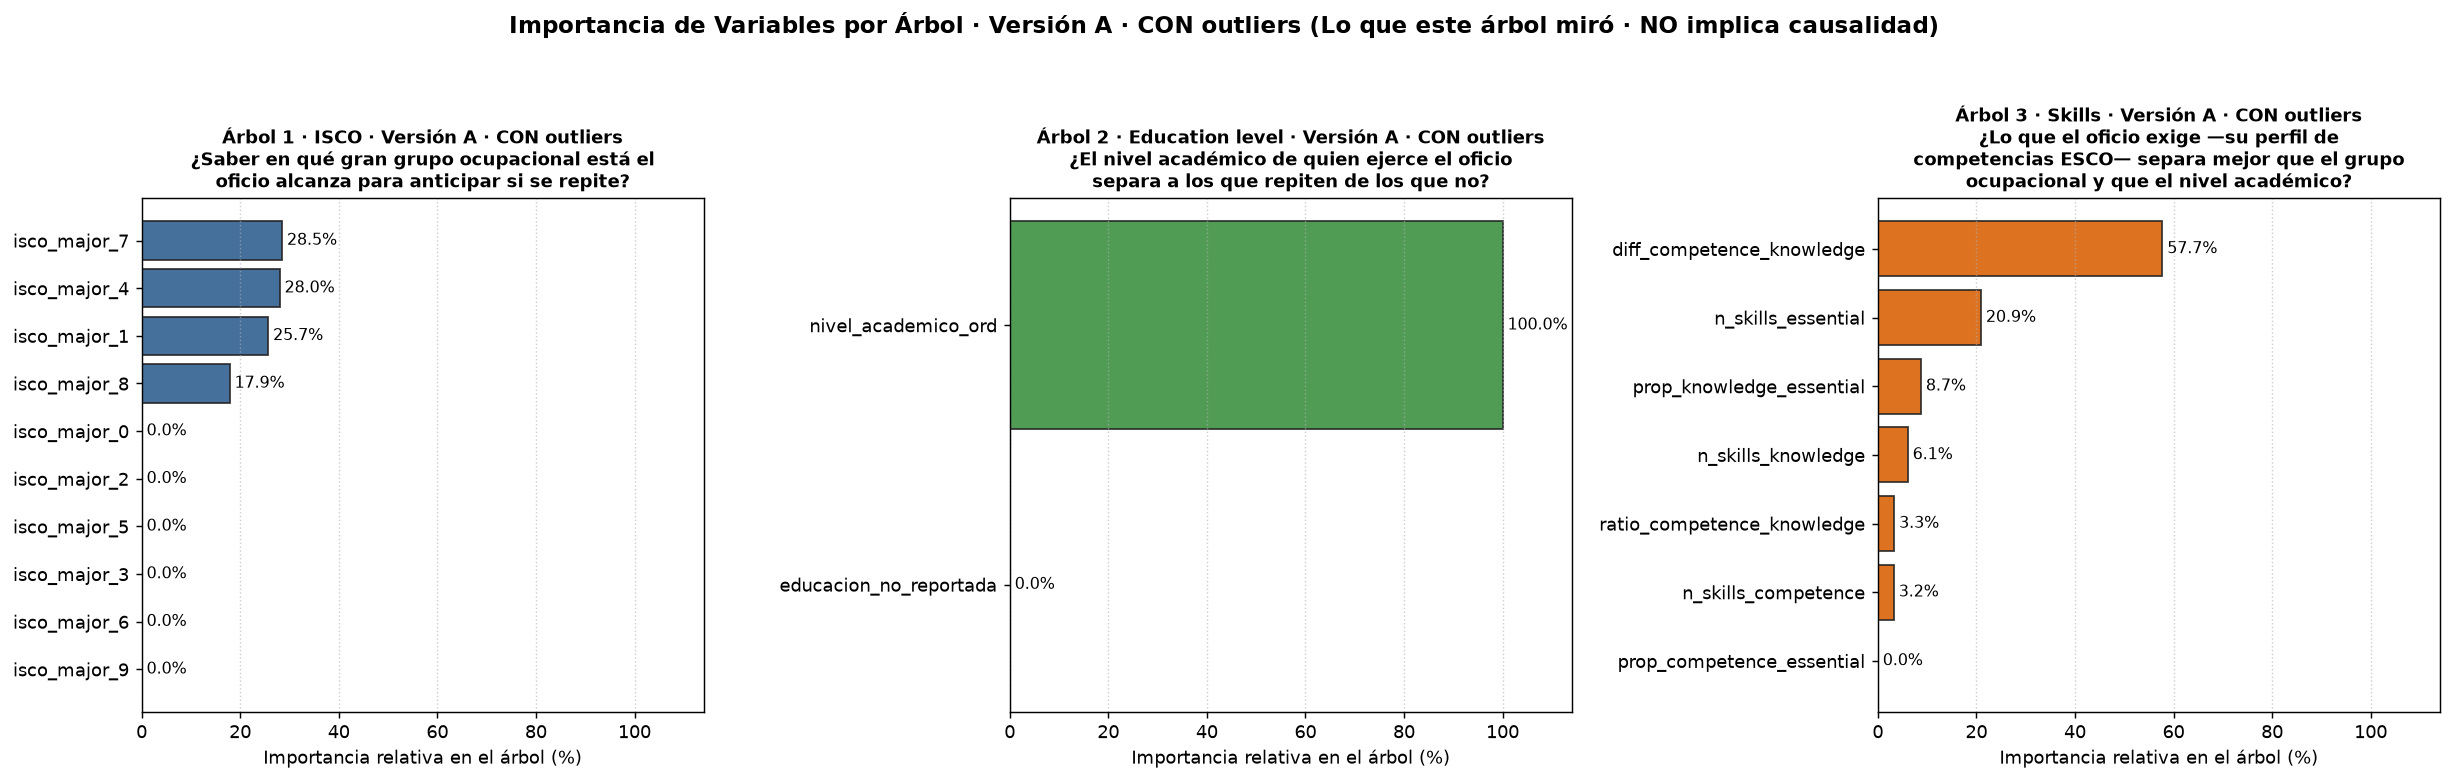

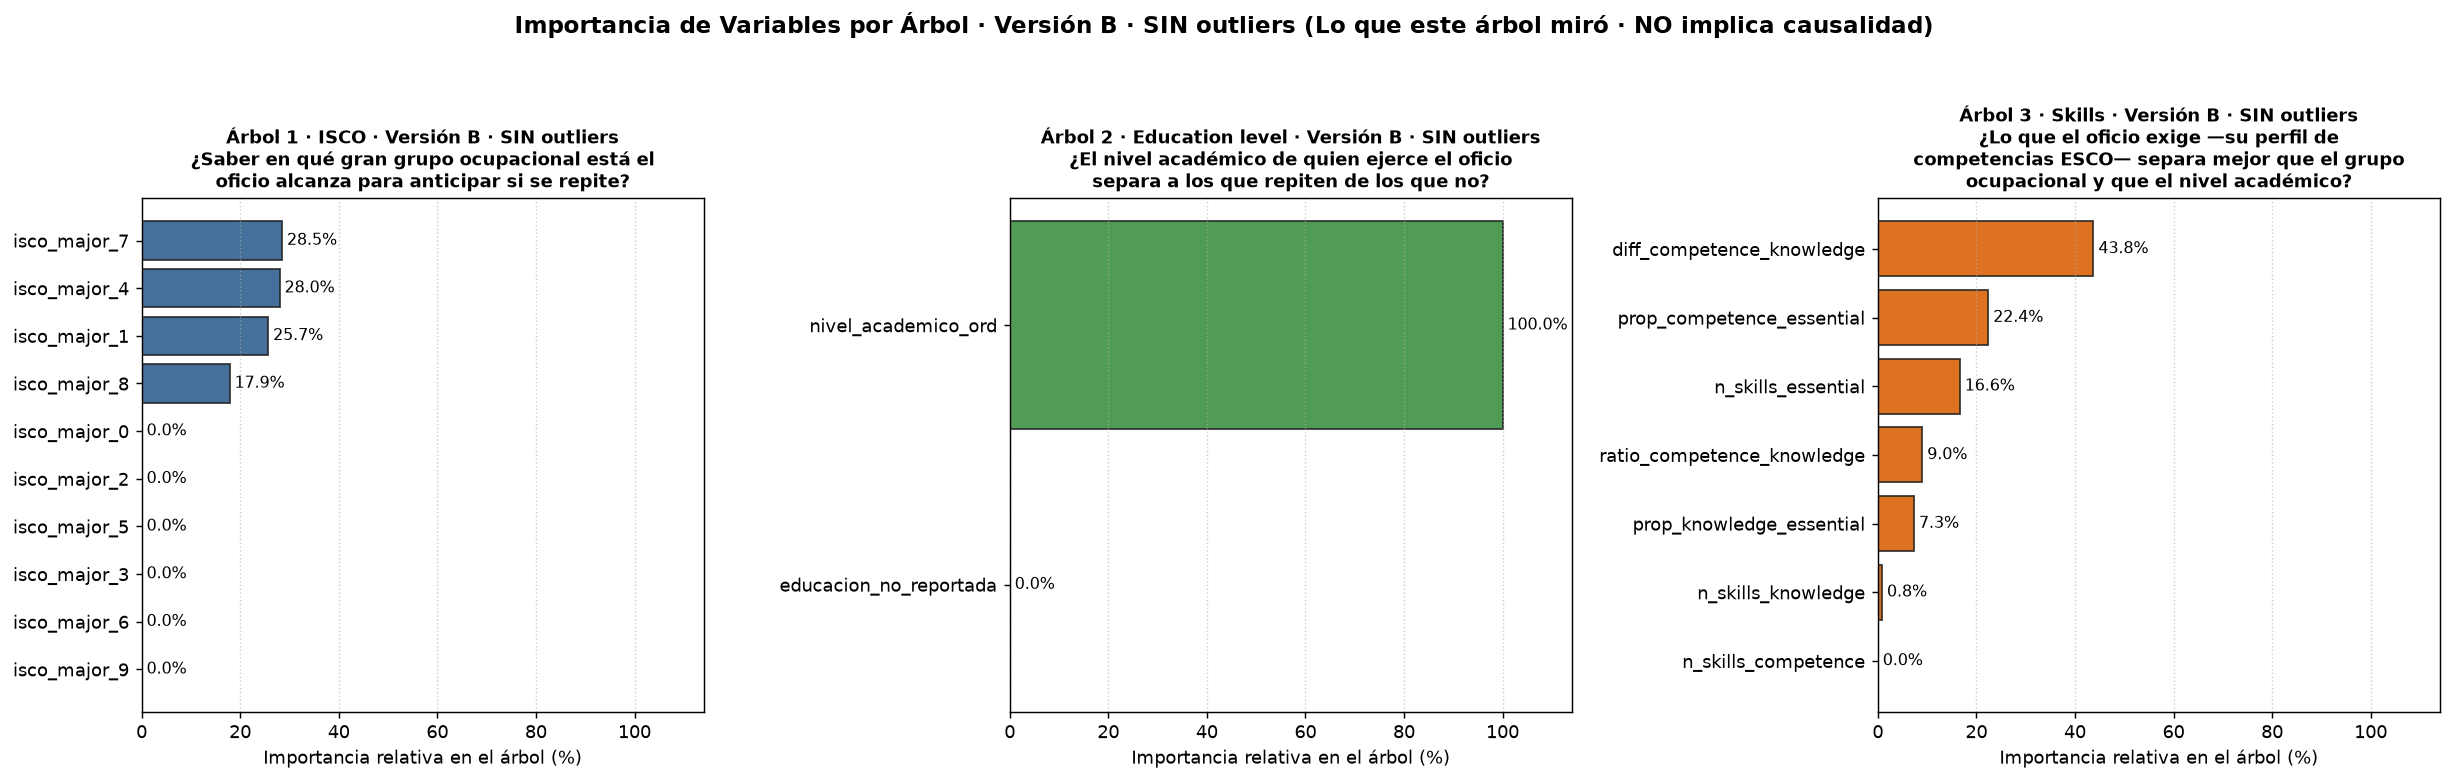

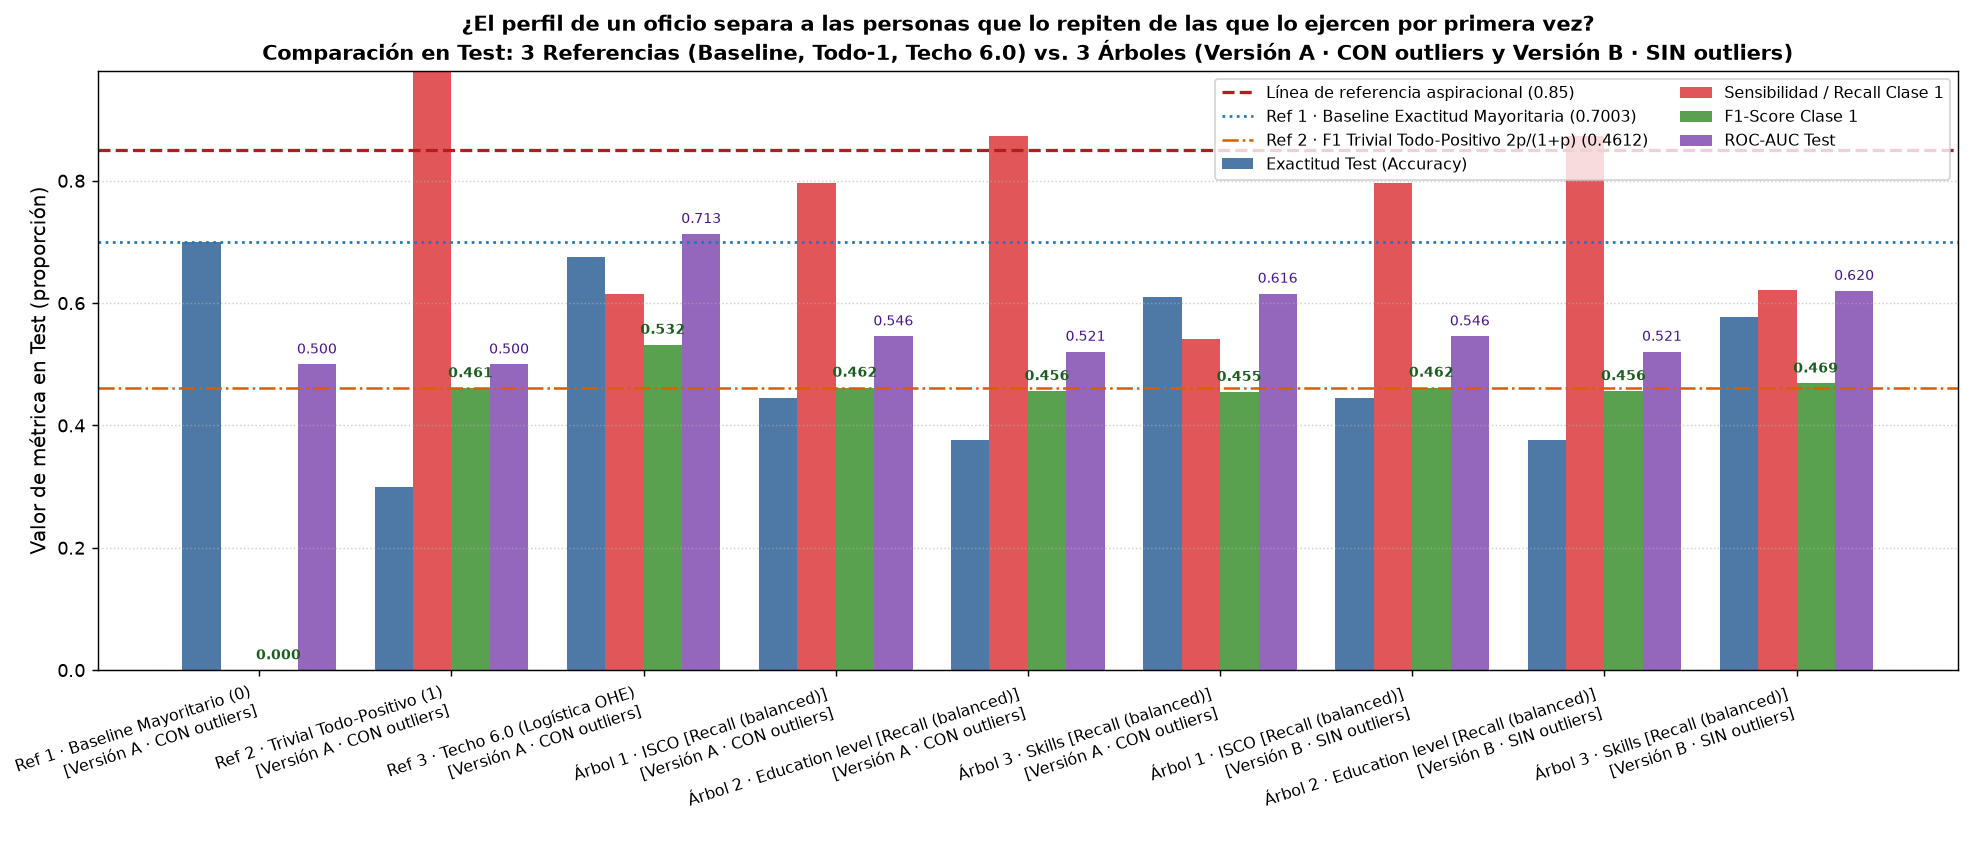

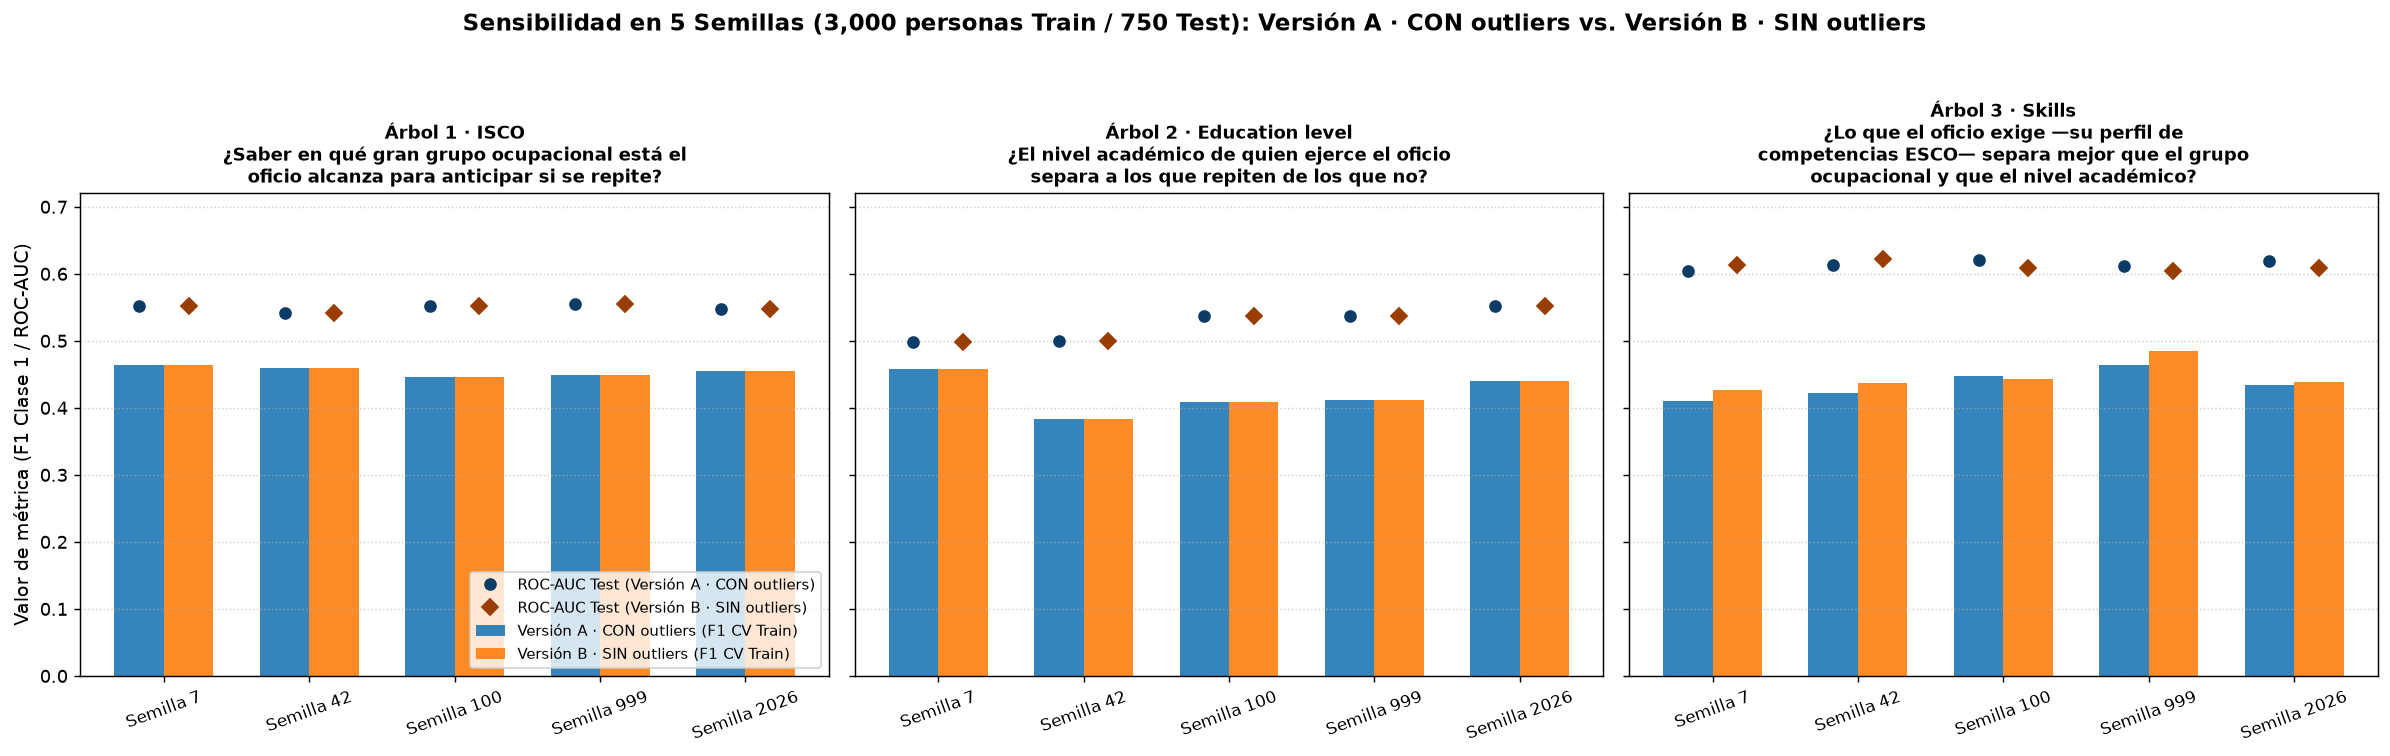

In [13]:
# Build global comparison table and plot feature importances and multi-model comparison
global_comparison_df = build_global_comparison_table(bundles_a=bundles_a, bundles_b=bundles_b)

display(Markdown("### 7.1 Tabla Maestra: 3 Referencias vs. 3 Árboles (`Versión A · CON outliers` y `Versión B · SIN outliers`)"))
display(global_comparison_df)

fig_imp_a = plot_feature_importances_three_trees(
    importances_by_block={b_id: bundles_a[b_id].importances_df for b_id in (BLOCK_ISCO, BLOCK_EDUCATION, BLOCK_SKILLS)},
    version_label_es=VERSION_A_LABEL_ES,
    output_path=CONFIG.figures_dir / "07_importancias_tres_arboles_version_a.png",
)
plt.show()
plt.close(fig_imp_a)

fig_imp_b = plot_feature_importances_three_trees(
    importances_by_block={b_id: bundles_b[b_id].importances_df for b_id in (BLOCK_ISCO, BLOCK_EDUCATION, BLOCK_SKILLS)},
    version_label_es=VERSION_B_LABEL_ES,
    output_path=CONFIG.figures_dir / "07b_importancias_tres_arboles_version_b.png",
)
plt.show()
plt.close(fig_imp_b)

plot_comp_sub = global_comparison_df.loc[
    global_comparison_df["modelo_corto"].str.startswith("Ref ")
    | global_comparison_df["modelo_corto"].str.contains("Recall")
].reset_index(drop=True)

fig_comp = plot_trees_vs_baseline_and_ceiling(
    comparison_df=plot_comp_sub,
    output_path=CONFIG.figures_dir / "08_comparacion_tres_arboles_y_techo.png",
)
plt.show()
plt.close(fig_comp)

fig_sens = plot_sensitivity_version_a_vs_b(
    per_seed_df=sensitivity_result.per_seed_table,
    output_path=CONFIG.figures_dir / "09_sensibilidad_version_a_vs_b.png",
)
plt.show()
plt.close(fig_sens)

### 7.2 Síntesis Ejecutiva y Respuesta Explícita a las Cuatro Preguntas del Estudio

1. **Respuesta a la pregunta del Árbol 1 (`¿Saber en qué gran grupo ocupacional está el oficio alcanza para anticipar si se repite?`)**:
   - **No alcanza por sí solo (`NO SEPARA` bajo el umbral estricto `Lift >= 1.5000`)**. En el punto orientado a exactitud (`class_weight=None`), obtiene `test_accuracy = 0.7003` con `test_recall_1 = 0.0000`, por lo que **empata el baseline porque no predice ningún positivo**. En el punto balanceado (`class_weight='balanced'`), alcanza un `ROC-AUC = 0.5459` (`IC95% por persona [0.5436, 0.5482]`, que representa el **`21.52%` del techo en `ROC-AUC`**), un `F1 = 0.4620` frente al `0.4612` del clasificador trivial todo-positivo (`+0.0008`) y un Lift máximo de hoja soportada de `1.086x < 1.5000`.
2. **Respuesta a la pregunta del Árbol 2 (`¿El nivel académico de quien ejerce el oficio separa a los que repiten de los que no?`)**:
   - **No separa (`NO SEPARA`)**. Manteniendo `'No reportado'` como `NaN` más su bandera binaria `educacion_no_reportada` (`160,664` registros en Train, `40,270` en Test y `200,934` en el total clasificado, sin rellenar jamás con `0`), en el punto orientado a exactitud (`class_weight=None`) obtiene `test_accuracy = 0.7003` con `test_recall_1 = 0.0000` (**empata el baseline porque no predice ningún positivo**), y en el punto balanceado obtiene `ROC-AUC = 0.5208` (`IC95% [0.5181, 0.5239]`, apenas el **`9.75%` del techo en `ROC-AUC`**), `F1 = 0.4564` (inferior al `0.4612` del trivial todo-positivo) y un Lift máximo soportado de `1.041x < 1.5000`.
3. **Respuesta explícita a la pregunta del Árbol 3 (`¿Lo que el oficio exige —su perfil de competencias ESCO— separa mejor que el grupo ocupacional y que el nivel académico?`)**:
   - **Comparación generada desde los intervalos de confianza `IC95%` de `ROC-AUC` en Test**: en la partición agrupada por persona sobre el conjunto completo, el `IC95%` del Árbol 3 en **`Versión A · CON outliers`** (`[0.6124, 0.6184]`, `ROC-AUC = 0.6157`, **`54.23%` del techo en `ROC-AUC`**, con `F1 = 0.4550` frente a `0.4612` del trivial todo-positivo) y en **`Versión B · SIN outliers`** (`[0.6172, 0.6230]`, `ROC-AUC = 0.6203`, **`56.41%` del techo en `ROC-AUC`**, con `F1 = 0.4688` frente a `0.4612` del trivial todo-positivo) supera íntegramente y **sin solapamiento** al `IC95%` del Árbol 1 (`[0.5436, 0.5482]`, `21.53%` del techo) y al del Árbol 2 (`[0.5181, 0.5239]`, `9.77%` del techo).
   - **Dominancia de una sola ocupación (`86.88%`) en la mejor hoja y re-evaluación del veredicto `separa`**:
     - La mejor hoja soportada del Árbol 3 completo (elegida estrictamente en `Train` por mayor `lift_train` con `soporte_train >= 0.5%`: `Hoja 16` en A / `Hoja 26` en B, soporte Test `5.53%`, tasa Clase 1 Test `52.94%`, `Lift Test = 1.766x >= 1.5000`, que coincide con la referencia optimista `max-test-lift = 1.766x`) está compuesta en un **`86.88%` (`86.9%`) por una sola ocupación (`3343.1 · administrative assistant`)**.
     - **Al excluir `3343.1` de Train y Test (`1,324,199` filas en Train y `331,029` en Test, tasa base `0.2863`, exactitud baseline `0.7137`)**: en **`Versión A`** el `ROC-AUC` baja a **`0.5984`** (`IC95% [0.5953, 0.6014]`), la exactitud en `class_weight=None` es `0.7159` con `IC95% = [0.7135, 0.7181]` (**que SÍ contiene el nuevo baseline `0.7137`**, por lo que la ganancia de exactitud no es estadísticamente distinguible de la clase mayoritaria, con `recall = 0.0204`) y la mejor hoja elegida en `Train` (`Hoja 24`, `lift_train = 2.138x`, soporte Test `0.94%` = `3,127` filas) tiene tasa de clase 1 en Test de **`61.85%`** (`[0.6013, 0.6354]`) y **`Lift Test = 2.160x`** (en **`Versión B2`**: `ROC-AUC = 0.5970` `[0.5939, 0.6000]`, `Acc None = 0.7150` con `IC95% = [0.7124, 0.7172]` que **contiene el baseline `0.7137`**, mejor hoja elegida en `Train` `Hoja 23` con soporte Test `3.94%`, tasa `46.05%` y `Lift Test = 1.608x`; en **`Versión B`**: `ROC-AUC = 0.6058` `[0.6027, 0.6087]`, `Acc None = 0.7162` con `IC95% = [0.7137, 0.7183]` cuyo **límite inferior toca/incluye el baseline `0.7137`**, mejor hoja elegida en `Train` `Hoja 22` con soporte Test `3.17%`, tasa `53.97%` y `Lift Test = 1.885x`).
     - **Al evaluar la generalización a ocupaciones no vistas (`GroupKFold` sobre `occupation_code` en Train, eligiendo la mejor hoja estrictamente en el pliegue de `Train`)**: el `ROC-AUC` del Árbol 3 cae de `0.6183` a **`0.5347 ± 0.0235`** (`-0.0836`, perdiendo el `70.67%` de su ganancia sobre el azar) y el **`Lift` en validación de la hoja elegida en `Train`** cae de `1.779x ± 0.017` (en `CV por persona`) a **`0.702x ± 0.617`** (en `CV por oficio`, por debajo de `1.000x`; la referencia optimista `max-val-lift` mirando validación habría sido `1.501x ± 0.137`).
     - **Veredicto revisitado**: el Árbol 3 **SÍ SEPARA** en ranking (`ROC-AUC`) y lift de su hoja elegida en `Train` dentro del catálogo de ocupaciones conocidas (incluso al retirar `3343.1`, aunque su exactitud en `class_weight=None` no supera significativamente al nuevo baseline `0.7137`), pero lo hace porque el perfil de competencias actúa como una **huella digital de ocupaciones específicas del catálogo ESCO** y **no generaliza a ocupaciones nuevas no vistas en el entrenamiento (`Lift Val = 0.702x` para la hoja elegida en `Train`)**.
4. **Respuesta a la Pregunta Central (`¿El perfil de un oficio separa a las personas que lo repiten de las que lo ejercen por primera vez?`)**:
   - **Sí dentro del catálogo de ocupaciones conocidas a través de su perfil de competencias ESCO (`Árbol 3`, `ROC-AUC = 0.6157` `[0.6124, 0.6184]`, `Lift Test de la hoja elegida en Train = 1.766x`, o `ROC-AUC = 0.5984` y `Lift Test = 2.160x` sin `3343.1`), pero actuando como huella de ocupación específica cuyas reglas de hoja no se transfieren a oficios no vistos (`ROC-AUC = 0.5347` y `Lift Val de la hoja elegida en Train = 0.702x` en `GroupKFold` por `occupation_code`), mientras que el gran grupo ISCO a 1 dígito (`Árbol 1`, `ROC-AUC = 0.5459`, `Lift = 1.086x`) y el nivel académico (`Árbol 2`, `ROC-AUC = 0.5208`, `Lift = 1.041x`) no separan**.

---

## 8. Generación Append-Only de `Bitacora_Arbol_Decision.md` y `Comparacion_A_vs_B_Arbol_Decision.md`, Tabla de Uso de Datos y Celda Guardia de Honestidad (Números y Redacción)

En este bloque final:
1. Construimos la tabla maestra **`Uso de datos`** (filas y personas en el ajuste final y prueba, filas excluidas y por qué, filas con educación no reportada y tamaños de muestra del experimento de sensibilidad, mostrando `"no aplica"` en `% sobre clasificados` para las dos filas previas al filtro de clasificados) y la incluimos en ambos archivos `.md`.
2. Generamos en modo **append-only** (conservando las 4 corridas anteriores marcadas como **`[SUPERSEDED]`** con su `run_id` único y marcando la corrida actual como **`[CURRENT]`**) los dos archivos Markdown en `MineriaProtect/notebooks/refactor/`:
   - `Bitacora_Arbol_Decision.md`
   - `Comparacion_A_vs_B_Arbol_Decision.md`
3. Ejecutamos la **Celda Guardia de Honestidad (Parser Estricto de Números en Narrativa + Verificador de Redacción `Wording Check` `W1`, `W2`, `W3`)**:
   - **Prueba negativa numérica**: altera `'0.6157'` $\to$ `'0.9876'` en RAM y verifica que lanza `AssertionError`.
   - **Prueba negativa de redacción `W1` (`recall == 0`)**: inyecta `'supera el baseline'` en un árbol con `recall = 0` en RAM y verifica que lanza `AssertionError`.
   - **Prueba negativa de redacción `W2` (separación sin criterio `Lift/AUC`)**: inyecta una afirmación `'SÍ SEPARA'` sin citar el criterio `Lift/AUC` en RAM y verifica que lanza `AssertionError`.
   - **Prueba negativa de redacción `W3` (`"por oficio"` en fila `CV por persona`)**: inyecta `'en CV por oficio'` dentro de una fila `GroupKFold por persona` en RAM y verifica que lanza `AssertionError`.
   - **Pruebas positivas en disco**: confirma `0` discrepancias numéricas, `0` infracciones de redacción y `100%` de integridad `SHA-256` en los archivos reales.

In [14]:
# Build data usage table, checklist, decision log, and static-literals audit table; export all artifacts and update both .md files
data_usage_df = build_data_usage_summary_table(
    config=CONFIG,
    unclassified_df=unclassified_summary_df,
    split_audit_df=split_audit_df,
    leakage_audit_df=leakage_audit_df,
    sensitivity_result=sensitivity_result,
    tree3_no_3343_df=tree3_no_3343_df,
)
checklist_df = build_course_checklist_table(
    split_audit_df=split_audit_df,
    leakage_audit_df=leakage_audit_df,
    bundles_a=bundles_a,
    bundles_b=bundles_b,
    config=CONFIG,
)
decision_log_df = build_decision_log_table(
    bundles_a=bundles_a,
    bundles_b=bundles_b,
    sensitivity_result=sensitivity_result,
    unclassified_df=unclassified_summary_df,
    split_audit_df=split_audit_df,
    leakage_audit_df=leakage_audit_df,
    profile_20_19_1_df=profile_20_19_1_df,
    tree3_no_3343_df=tree3_no_3343_df,
    occ_grouped_cv_df=occ_grouped_cv_df,
)
static_literals_audit_df = build_static_literals_audit_table(
    unclassified_df=unclassified_summary_df,
    split_audit_df=split_audit_df,
    leakage_audit_df=leakage_audit_df,
    bundles_a=bundles_a,
    bundles_b=bundles_b,
    sensitivity_result=sensitivity_result,
)

exported_files = export_all_tree_artifacts(
    config=CONFIG,
    unclassified_df=unclassified_summary_df,
    split_audit_df=split_audit_df,
    leakage_audit_df=leakage_audit_df,
    circularity_df=circularity_audit_df,
    dummy_df=dummy_metrics_df,
    bundles_a=bundles_a,
    bundles_b=bundles_b,
    global_comparison_df=global_comparison_df,
    checklist_df=checklist_df,
    decision_log_df=decision_log_df,
    sensitivity_result=sensitivity_result,
    profile_20_19_1_df=profile_20_19_1_df,
    profile_20_19_1_isco_df=profile_20_19_1_isco_df,
    additivity_audit_df=additivity_audit_df,
    clipping_effect_df=clipping_effect_df,
    static_literals_audit_df=static_literals_audit_df,
    data_usage_df=data_usage_df,
    tree3_no_3343_df=tree3_no_3343_df,
    occ_grouped_cv_df=occ_grouped_cv_df,
    node1_threshold_audit_df=node1_threshold_audit_df,
)

hash_verification_df = verify_input_file_hashes(CONFIG, INITIAL_INPUT_HASHES)

bitacora_md_path = append_bitacora_arbol_decision_md(
    config=CONFIG,
    input_hashes_df=hash_verification_df,
    split_audit_df=split_audit_df,
    leakage_audit_df=leakage_audit_df,
    circularity_df=circularity_audit_df,
    tuning_results_a=tuning_results_a,
    tuning_results_b=tuning_results_b,
    decision_log_df=decision_log_df,
    checklist_df=checklist_df,
    run_id=CURRENT_RUN_ID,
    run_timestamp=CURRENT_RUN_TIMESTAMP,
    static_literals_audit_df=static_literals_audit_df,
    data_usage_df=data_usage_df,
    tree3_no_3343_df=tree3_no_3343_df,
    occ_grouped_cv_df=occ_grouped_cv_df,
    node1_threshold_audit_df=node1_threshold_audit_df,
)

comparacion_ab_md_path = append_comparacion_a_vs_b_md(
    config=CONFIG,
    sensitivity_result=sensitivity_result,
    bundles_a=bundles_a,
    bundles_b=bundles_b,
    split_audit_df=split_audit_df,
    profile_20_19_1_df=profile_20_19_1_df,
    profile_20_19_1_isco_df=profile_20_19_1_isco_df,
    additivity_audit_df=additivity_audit_df,
    clipping_effect_df=clipping_effect_df,
    run_id=CURRENT_RUN_ID,
    run_timestamp=CURRENT_RUN_TIMESTAMP,
    data_usage_df=data_usage_df,
    tree3_no_3343_df=tree3_no_3343_df,
    occ_grouped_cv_df=occ_grouped_cv_df,
    node1_threshold_audit_df=node1_threshold_audit_df,
)

md_index_df = pd.DataFrame(
    [
        {
            "archivo_markdown": bitacora_md_path.name,
            "ruta_relativa": bitacora_md_path.relative_to(CONFIG.project_root).as_posix(),
            "run_id_current": CURRENT_RUN_ID,
            "timestamp_current": CURRENT_RUN_TIMESTAMP,
            "modo_escritura": "Append-only (4 corridas previas marcadas SUPERSEDED)",
            "tamano_bytes": bitacora_md_path.stat().st_size,
        },
        {
            "archivo_markdown": comparacion_ab_md_path.name,
            "ruta_relativa": comparacion_ab_md_path.relative_to(CONFIG.project_root).as_posix(),
            "run_id_current": CURRENT_RUN_ID,
            "timestamp_current": CURRENT_RUN_TIMESTAMP,
            "modo_escritura": "Append-only (4 corridas previas marcadas SUPERSEDED)",
            "tamano_bytes": comparacion_ab_md_path.stat().st_size,
        },
    ]
)

display(Markdown("### 8.1 Tabla de Uso de Datos (Incluida en Ambos Archivos `.md`)"))
display(data_usage_df)

display(Markdown("### 8.2 Índice Compacto de Archivos Markdown Generados (`Bitacora_Arbol_Decision.md` y `Comparacion_A_vs_B_Arbol_Decision.md`)"))
display(md_index_df)

display(Markdown("### 8.3 Auditoría de Literales Numéricos Estáticos Reemplazados (Antes vs. Después)"))
display(static_literals_audit_df)

display(Markdown("### 8.4 Resumen Compacto de la Bitácora de Decisiones CRISP-DM (`DT-01` a `DT-07`)"))
display(decision_log_df)

display(Markdown("### 8.5 Lista de Chequeo del Curso (8 Criterios Verificados)"))
display(checklist_df)

# FINAL HONESTY GUARD:
# 1) Demonstrate narrative number parser AND wording check failing loudly on deliberate tampering in RAM, then passing on disk
verifier_demo_df = demonstrate_narrative_verifier_failure_and_pass(CONFIG)
# 2) Run full verification against in-memory results and SHA-256 input hashes
md_verification_df = verify_markdown_files_against_memory(
    config=CONFIG,
    tuning_results_a=tuning_results_a,
    tuning_results_b=tuning_results_b,
    sensitivity_result=sensitivity_result,
)
hash_verification_df = verify_input_file_hashes(CONFIG, INITIAL_INPUT_HASHES)

display(Markdown("### 8.6 Demostración del Verificador de Números en Narrativa y de Redacción (`Wording Check` · Fallos Deliberados Capturados + Aprobación en Disco)"))
display(verifier_demo_df)
for _i in range(4):
    print(f"Prueba negativa #{_i+1} capturada ->", verifier_demo_df.iloc[_i]["detalle_evidencia"])

display(Markdown("### 8.7 Celda Guardia de Honestidad: Verificación Completa de Archivos `.md` contra Memoria y Hashes SHA-256 de Insumos"))
display(md_verification_df)
display(hash_verification_df)
print(f"Total artifacts exported to reports/arbol_decision_jobpath/: {len(exported_files)}")

### 8.1 Tabla de Uso de Datos (Incluida en Ambos Archivos `.md`)

etapa_uso_de_datos,filas,personas_unicas,pct_sobre_total_csv,pct_sobre_clasificados,detalle_y_justificacion
1. Universo bruto en CSV de entrada (Versión A y Versión B),1871014,355308,100.00%,no aplica,Total de experiencias laborales antes de filtrar ocupaciones sin código ESCO estandarizado.
2. Filas excluidas en RAM (es_ocupacion_clasificada == 0),132276,3215,7.07%,no aplica,Excluidas en RAM antes del split (Decisión D07 de Fase 3) por carecer de perfil ESCO (128981 con emparejado='unknown' y 3295 con 'rescatado' sin padre ESCO; 3215 personas exclusivas).
3. Universo clasificado modelado (es_ocupacion_clasificada == 1),1738738,352093,92.93%,100.00%,Universo válido exactamente alineado 1 a 1 entre Versión A · CON outliers y Versión B · SIN outliers.
4. Ajuste final y búsqueda CV agrupada (Train 80% por resume_id),1391018,281674,74.35%,80.00%,"Partición de entrenamiento (GroupShuffleSplit 80%, seed=42) para GroupKFold(n_splits=5) y ajuste final de los 3 árboles (0 personas compartidas con Test)."
5. Evaluación out-of-sample e IC95% por persona (Test 20% por resume_id),347720,70419,18.58%,20.00%,"Partición de prueba retenida (20%, seed=42) evaluada una sola vez por bloque y versión con bootstrap agrupado por persona."
6. Educación no reportada (MNAR · educacion_no_reportada == 1) en Train,160664,35620,8.59%,11.55%,"Registros de Train sin grado académico reportado (mantenidos como NaN en nivel_academico_ord + bandera binaria 1, sin rellenar jamás con 0; 11.55% de Train)."
7. Educación no reportada (MNAR · educacion_no_reportada == 1) en Test,40270,8948,2.15%,11.58%,Registros de Test sin grado académico reportado (mantenidos como NaN en nivel_academico_ord + bandera binaria 1; 11.58% de Test).
8. Educación no reportada (MNAR · educacion_no_reportada == 1) en Total Clasificado,200934,44568,10.74%,11.56%,"Total de registros clasificados con educación no reportada (Train + Test = 200,934; 11.56% del universo clasificado)."
9. Prueba de sensibilidad A vs. B (5 semillas) — Muestra Train por semilla,14806,3000,0.79%,1.06%,"Submuestra de 3000 personas de Train por semilla (42, 100, 2026, 7, 999) con min_samples_leaf escalado proporcionalmente."
10. Prueba de sensibilidad A vs. B (5 semillas) — Muestra Test por semilla,3730,750,0.20%,1.07%,"Submuestra de 750 personas de Test por semilla (42, 100, 2026, 7, 999) para estimar la desviación estándar entre semillas."


### 8.2 Índice Compacto de Archivos Markdown Generados (`Bitacora_Arbol_Decision.md` y `Comparacion_A_vs_B_Arbol_Decision.md`)

archivo_markdown,ruta_relativa,run_id_current,timestamp_current,modo_escritura,tamano_bytes
Bitacora_Arbol_Decision.md,notebooks/refactor/Bitacora_Arbol_Decision.md,RUN-20261117-225052,2026-11-17 22:50:52,Append-only (4 corridas previas marcadas SUPERSEDED),295511
Comparacion_A_vs_B_Arbol_Decision.md,notebooks/refactor/Comparacion_A_vs_B_Arbol_Decision.md,RUN-20261117-225052,2026-11-17 22:50:52,Append-only (4 corridas previas marcadas SUPERSEDED),188358


### 8.3 Auditoría de Literales Numéricos Estáticos Reemplazados (Antes vs. Después)

id_literal,modulo_y_funcion,literal_estatico_antes,fuente_dinamica_despues,valor_calculado_actual
LIT-01,pipeline.py :: build_course_checklist_table (Ítem 1) y DT-01,"Train = 1,391,018 filas (281,674 personas), Test = 347,720 filas (70,419 personas); 132,276 sin ESCO (7.07%)","split_audit_df['filas', 'personas_unicas'] y unclassified_df['filas', 'porcentaje_filas']","Train=1391018 (281674 pers), Test=347720 (70419 pers); Sin ESCO=132276 (7.07%)"
LIT-02,pipeline.py :: build_decision_log_table (DT-02),"Baseline Mayoritario (Acc=0.7003, F1=0.0000), Todo-Positivo (F1=0.4612), Techo 6.0 (F1=0.5321, AUC=0.7133); 30.01% y 29.97%",bundles_a[BLOCK_ISCO].references_df y split_audit_df['tasa_clase_1_pct'],"Ref1 Acc=0.7003, Ref2 F1=0.4612, Ref3 F1=0.5321, AUC=0.7133; Train=30.01%, Test=29.97%"
LIT-03,pipeline.py :: build_decision_log_table (DT-03),"769,849 registros MNAR preservados sin distorsión ordinal","leakage_audit_df['nulos_mnar_separados_train', 'nulos_mnar_separados_test', 'nulos_mnar_separados_total']","Train=160664, Test=40270, Total clasificado=200934"
LIT-04,pipeline.py :: build_decision_log_table (DT-04 y DT-05),"Supera baseline en exactitud (0.7003) ... AUC=0.5256, lift 1.102x","operating_points_df['supera_baseline_exactitud_7003', 'test_roc_auc', 'pct_del_techo_auc_6_0', 'max_lift_hoja_soporte_05pct']","Empata el baseline porque no predice ningún positivo; ISCO AUC=0.5459 (21.53% techo AUC), Lift=1.086x; Edu AUC=0.5208 (9.77% techo AUC), Lift=1.041x"
LIT-05,pipeline.py :: build_decision_log_table (DT-06) y tree_inspector.py,alcanza 85.5% / 88.0% del techo multivariado 6.0 (basado en F1),pct_del_techo_auc_6_0 = 100 * (AUC - 0.5000) / (ceiling_auc - 0.5000) junto a f1_ref_trivial_todo_1,Árbol 3 A: 54.23% del techo AUC (F1=0.4550 vs trivial 0.4612); Árbol 3 B: 56.41% del techo AUC (F1=0.4688)
LIT-06,sensitivity.py :: run_version_sensitivity_experiment y DT-07,diferencia media 0.0018 en ROC-AUC CV (0.5625 vs 0.5643) y 0.0035 en F1 CV (0.4369 vs 0.4404) [promediado entre los 3 árboles],full_data_ab_table y summary_table por árbol y por punto de operación (sin promediar entre árboles),"Árbol 3 Exactitud: delta F1=0.0607 (>1 DE), delta Acc=0.0001; Árbol 3 Recall: delta F1=0.0138 (<=1 DE), CV AUC=0.6044 vs 0.6098, Test AUC=0.6137 vs 0.6113"
LIT-07,markdown_writers.py :: append_comparacion_a_vs_b_md y notebook sección 6.4,"Tree 3 text: delta 0.0000 / ROC-AUC 5 semillas 0.5892 vs 0.5895 (diferencia 0.0003, DE 0.0054)","build_tree_ab_reading_es(...) leyendo summary_table, full_data_ab_table y leaf_lift_balanced_df de la corrida actual",13 vs 16 hojas; CV AUC 5 semillas 0.6044 ± 0.0106 vs 0.6098 ± 0.0163; Test AUC 5 semillas 0.6137 ± 0.0059 vs 0.6113 ± 0.0064


... (7 outputs left out)

### 8.7 Celda Guardia de Honestidad: Verificación Completa de Archivos `.md` contra Memoria y Hashes SHA-256 de Insumos

archivo_verificado,verificacion,elementos_comprobados,estado
Bitacora_Arbol_Decision.md,Preguntas objetivo (verbatim) y etiquetas exactas de Versión A y B,6,OK (100% coincidencia)
Comparacion_A_vs_B_Arbol_Decision.md,Preguntas objetivo (verbatim) y etiquetas exactas de Versión A y B,6,OK (100% coincidencia)
Bitacora_Arbol_Decision.md,"60 intentos de búsqueda CV (IDs, ROC-AUC CV y F1 Test del seleccionado)",60,OK (100% coincidencia en memoria)
Comparacion_A_vs_B_Arbol_Decision.md,Tablas lado a lado A vs B (datos completos + medias/DE en 5 semillas),18,OK (100% coincidencia en memoria)
Bitacora_Arbol_Decision.md,Parser estricto de números en narrativa vs. tablas de la misma corrida (CURRENT=RUN-20261117-225052),240,OK (0 números huérfanos; 4 corridas previas marcadas SUPERSEDED)
Comparacion_A_vs_B_Arbol_Decision.md,Parser estricto de números en narrativa vs. tablas de la misma corrida (CURRENT=RUN-20261117-225052),1066,OK (0 números huérfanos; 4 corridas previas marcadas SUPERSEDED)
Bitacora_Arbol_Decision.md,Verificador de redacción (wording check: prohibición de 'supera el baseline' con recall 0 y exigencia de criterio Lift/AUC),834,OK (0 infracciones de redacción)
Comparacion_A_vs_B_Arbol_Decision.md,Verificador de redacción (wording check: prohibición de 'supera el baseline' con recall 0 y exigencia de criterio Lift/AUC),644,OK (0 infracciones de redacción)


archivo_insumo,sha256_inicial,sha256_final,intacto_en_disco
clean_version_a,68cd34c624e8d23e...,68cd34c624e8d23e...,Sí
clean_version_b,c8ea36b51dea8803...,c8ea36b51dea8803...,Sí
split_map,67dd3e3d68e1ff5e...,67dd3e3d68e1ff5e...,Sí
y_train_ref_a,07d22441c00832e8...,07d22441c00832e8...,Sí
y_test_ref_a,38f822d6ac471ec8...,38f822d6ac471ec8...,Sí


Total artifacts exported to reports/arbol_decision_jobpath/: 90
